<a href="https://colab.research.google.com/github/saatour/GW170817/blob/main/20261013_EAGLE_simulation_analysis_Chapter6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [132]:
%pip install numpy pandas matplotlib scipy astropy healpy requests

In [133]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import healpy as hp
import requests

from astropy.io import fits
from scipy.integrate import cumulative_trapezoid

# Create local data directory
DATA = Path("data")
DATA.mkdir(exist_ok=True)

# GW190814 localisation file
SKYMAP_URL = (
    "https://dcc.ligo.org/LIGO-P2000230/public/"
    "GW190814_skymap.fits.gz"
)

SKYMAP_FILE = DATA / "GW190814_skymap.fits.gz"

# Credible probability level
CREDIBLE = 0.90

print("Working directory:", Path.cwd().resolve())
print("Target credible level:", CREDIBLE)

Working directory: /content
Target credible level: 0.9


In [134]:
if not SKYMAP_FILE.exists():

    response = requests.get(
        SKYMAP_URL,
        timeout=120
    )

    response.raise_for_status()

    SKYMAP_FILE.write_bytes(response.content)

# Confirm file exists
assert SKYMAP_FILE.exists()
assert SKYMAP_FILE.stat().st_size > 1000

# Record a checksum for reproducibility
sha256 = hashlib.sha256(
    SKYMAP_FILE.read_bytes()
).hexdigest()

print("File:", SKYMAP_FILE)
print("File size:", SKYMAP_FILE.stat().st_size, "bytes")
print("SHA256:", sha256)

# Inspect the FITS structure
with fits.open(SKYMAP_FILE) as hdul:

    hdul.info()

    print("\nAvailable columns:")
    print(hdul[1].columns.names)

    print("\nHEALPix ordering:")
    print(hdul[1].header.get("ORDERING"))

File: data/GW190814_skymap.fits.gz
File size: 1472321 bytes
SHA256: 468ec8032ed11458ff9ef3c8735a039fcb0ead37f7a57be9c133f3df2dd8757e
Filename: data/GW190814_skymap.fits.gz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU     32   12582912R x 4C   [D, D, D, D]   

Available columns:
['PROB', 'DISTMU', 'DISTSIGMA', 'DISTNORM']

HEALPix ordering:
NESTED


In [135]:
with fits.open(SKYMAP_FILE, memmap=False) as hdul:

    header = hdul[1].header
    table = hdul[1].data

    required_columns = {
        "PROB",
        "DISTMU",
        "DISTSIGMA",
        "DISTNORM"
    }

    available_columns = set(table.names)

    assert required_columns.issubset(available_columns), (
        f"Missing columns: "
        f"{required_columns - available_columns}"
    )

    nside = int(header["NSIDE"])
    ordering = str(header.get("ORDERING", "")).upper()

    prob = np.asarray(table["PROB"], dtype=float)
    distmu = np.asarray(table["DISTMU"], dtype=float)
    distsigma = np.asarray(table["DISTSIGMA"], dtype=float)
    distnorm = np.asarray(table["DISTNORM"], dtype=float)

# Validate prob map
assert len(prob) == hp.nside2npix(nside)
assert np.all(np.isfinite(prob))
assert np.all(prob >= 0)
assert np.isclose(prob.sum(), 1.0, atol=1e-3)

print("NSIDE:", nside)
print("Ordering:", ordering)
print("Number of pixels:", len(prob))
print("Total probability:", prob.sum())

NSIDE: 1024
Ordering: NESTED
Number of pixels: 12582912
Total probability: 0.9999999999999997


In [136]:
from astropy.cosmology import Planck18, z_at_value
import astropy.units as u

# We are calculating a true 3D credible region,
# not combining separate sky and distance intervals.

CREDIBLE = 0.90

# HEALPix pixel solid angle
pixel_area_sr = hp.nside2pixarea(nside)

# Pixels with valid conditional distance information
valid = (
    np.isfinite(prob)
    & (prob > 0)
    & np.isfinite(distmu)
    & np.isfinite(distsigma)
    & np.isfinite(distnorm)
    & (distsigma > 0)
    & (distnorm > 0)
)

print("Probability with valid distance information:",
      prob[valid].sum())

assert prob[valid].sum() > 0.999, (
    "Too much probability is missing distance information."
)

# Set a luminosity-distance range covering the posterior
distance_max = np.max(
    distmu[valid] + 8 * distsigma[valid]
)

# Radial discretisation
N_RADIAL = 2400

dl_edges = np.linspace(
    0.0,
    distance_max,
    N_RADIAL + 1
)

dl_mid = 0.5 * (dl_edges[:-1] + dl_edges[1:])
dl_width = np.diff(dl_edges)

# Convert luminosity-distance edges to comoving distance.
# We use Planck18 as the reference cosmology.

z_max = z_at_value(
    Planck18.luminosity_distance,
    distance_max * u.Mpc,
    zmax=10
)

z_lookup = np.linspace(
    0,
    float(z_max) * 1.01,
    5000
)

dl_lookup = Planck18.luminosity_distance(
    z_lookup
).to_value(u.Mpc)

dc_lookup = Planck18.comoving_distance(
    z_lookup
).to_value(u.Mpc)

dc_edges = np.interp(
    dl_edges,
    dl_lookup,
    dc_lookup
)

# Exact comoving shell volume per steradian
shell_volume = (
    dc_edges[1:]**3 - dc_edges[:-1]**3
) / 3.0

# Volume of one HEALPix angular pixel
# intersected with each radial shell
voxel_volume = pixel_area_sr * shell_volume

print(f"HEALPix NSIDE: {nside}")
print(f"Valid sky pixels: {valid.sum():,}")
print(f"Maximum luminosity distance: {distance_max:.2f} Mpc")
print(f"Radial shells: {N_RADIAL}")
print(f"Maximum comoving distance: {dc_edges[-1]:.2f} Mpc")

Probability with valid distance information: 0.9999999999999999
HEALPix NSIDE: 1024
Valid sky pixels: 171,136
Maximum luminosity distance: 708.56 Mpc
Radial shells: 2400
Maximum comoving distance: 618.99 Mpc


In [137]:
# Extract valid pixel data
p = prob[valid]
mu = distmu[valid]
sigma = distsigma[valid]
norm = distnorm[valid]

# Probability density per comoving Mpc^3 is used
# to define the highest-posterior-density region.

# Logarithmic bins for numerical density thresholding
density_edges = np.logspace(-40, 0, 12001)
n_bins = len(density_edges) - 1

prob_hist = np.zeros(n_bins)
volume_hist = np.zeros(n_bins)

total_probability = 0.0
outside_density_range = 0.0

CHUNK_SIZE = 128

for start in range(0, len(p), CHUNK_SIZE):

    end = min(start + CHUNK_SIZE, len(p))

    pc = p[start:end, None]
    muc = mu[start:end, None]
    sigc = sigma[start:end, None]
    normc = norm[start:end, None]

    # Conditional luminosity-distance posterior:
    # p(D_L | sky) proportional to
    # D_L^2 exp[-(D_L - mu)^2 / (2 sigma^2)]

    exponent = -0.5 * (
        (dl_mid[None, :] - muc) / sigc
    )**2

    conditional_pdf = (
        normc
        * dl_mid[None, :]**2
        * np.exp(exponent)
        / (np.sqrt(2 * np.pi) * sigc)
    )

    # Joint probability in each sky/radial voxel
    voxel_prob = (
        pc
        * conditional_pdf
        * dl_width[None, :]
    )

    total_probability += voxel_prob.sum()

    # Probability density per unit comoving volume
    density = voxel_prob / voxel_volume[None, :]

    # Assign each voxel to a density histogram bin
    indices = np.searchsorted(
        density_edges,
        density,
        side="right"
    ) - 1

    in_range = (
        (indices >= 0)
        & (indices < n_bins)
        & np.isfinite(density)
    )

    outside_density_range += voxel_prob[~in_range].sum()

    # Histogram of posterior probability
    prob_hist += np.bincount(
        indices[in_range],
        weights=voxel_prob[in_range],
        minlength=n_bins
    )

    # Histogram of geometric comoving volume
    volumes = np.broadcast_to(
        voxel_volume[None, :],
        voxel_prob.shape
    )

    volume_hist += np.bincount(
        indices[in_range],
        weights=volumes[in_range],
        minlength=n_bins
    )

print(f"Integrated posterior probability: {total_probability:.6f}")
print(f"Probability outside density bins: {outside_density_range:.3e}")

assert np.isclose(
    total_probability, 1.0, atol=0.005
), "Posterior integration is not sufficiently normalised."

assert outside_density_range < 1e-6, (
    "Density histogram bounds are insufficient."
)

Integrated posterior probability: 1.000000
Probability outside density bins: 1.594e-36


In [138]:
# Numerical probability normalisation
prob_hist_normalised = prob_hist / total_probability

# Reverse arrays: highest density first
p_desc = prob_hist_normalised[::-1]
v_desc = volume_hist[::-1]

cumulative_probability = np.cumsum(p_desc)
cumulative_volume = np.cumsum(v_desc)

# First bin reaching the requested probability
idx = np.searchsorted(
    cumulative_probability,
    CREDIBLE
)

assert idx < len(p_desc), (
    "Could not enclose the requested probability."
)

# Probability enclosed before the boundary bin
p_before = (
    cumulative_probability[idx - 1]
    if idx > 0 else 0.0
)

# Volume enclosed before the boundary bin
v_before = (
    cumulative_volume[idx - 1]
    if idx > 0 else 0.0
)

# Fraction of the boundary density bin needed
fraction = (
    (CREDIBLE - p_before) / p_desc[idx]
)

# Approximate HPD volume,
# interpolating inside the boundary density bin
V90 = v_before + fraction * v_desc[idx]

# Equivalent cubic volume
L_cube = V90**(1.0 / 3.0)

print("=" * 55)
print("GW190814 THREE-DIMENSIONAL LOCALISATION")
print("=" * 55)

print(f"Credible probability: {CREDIBLE:.1%}")

print(
    f"90% HPD comoving volume: "
    f"{V90:,.2f} cMpc^3"
)

print(
    f"Equivalent EAGLE cube side: "
    f"{L_cube:.3f} cMpc"
)

print(
    f"Posterior probability represented: "
    f"{total_probability:.6f}"
)

print("=" * 55)

# Save results for subsequent notebook cells
volume_results = {
    "event": "GW190814",
    "credible_level": CREDIBLE,
    "definition": "3D highest-posterior-density region",
    "cosmology": "Planck18",
    "volume_comoving_mpc3": float(V90),
    "cube_side_comoving_mpc": float(L_cube),
    "radial_shells": N_RADIAL,
    "integrated_probability": float(total_probability),
    "skymap_sha256": sha256
}

output_file = DATA / "GW190814_volume_results.json"

with open(output_file, "w") as f:
    json.dump(volume_results, f, indent=2)

print(f"Results saved to: {output_file}")

GW190814 THREE-DIMENSIONAL LOCALISATION
Credible probability: 90.0%
90% HPD comoving volume: 31,665.93 cMpc^3
Equivalent EAGLE cube side: 31.637 cMpc
Posterior probability represented: 1.000000
Results saved to: data/GW190814_volume_results.json


In [139]:
%pip install ligo.skymap

In [140]:
from ligo.skymap.distance import conditional_pdf

# Select 100 valid sky pixels reproducibly
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    np.flatnonzero(valid),
    size=100,
    replace=False
)

# Choose a range of luminosity distances
test_distances = np.linspace(
    1.0,
    distance_max,
    500
)

# Official LIGO implementation
official_pdf = conditional_pdf(
    test_distances[None, :],
    distmu[sample_indices, None],
    distsigma[sample_indices, None],
    distnorm[sample_indices, None]
)

# Our implementation
mu_test = distmu[sample_indices, None]
sigma_test = distsigma[sample_indices, None]
norm_test = distnorm[sample_indices, None]

our_pdf = (
    norm_test
    * test_distances[None, :]**2
    * np.exp(
        -0.5 * (
            (test_distances[None, :] - mu_test)
            / sigma_test
        )**2
    )
    / (np.sqrt(2 * np.pi) * sigma_test)
)

# Compare numerical implementations
np.testing.assert_allclose(
    our_pdf,
    official_pdf,
    rtol=1e-10,
    atol=1e-14
)

print("PASS: Conditional distance posterior matches ligo.skymap.")

PASS: Conditional distance posterior matches ligo.skymap.


In [141]:
%pip install eaglesqltools

In [142]:
import eagleSqlTools as sql
import getpass

# Enter EAGLE credentials interactively.
# These are not written into the notebook.

EAGLE_USER = "nmq680"

EAGLE_PASSWORD = "zw59ha64"

# Connect to the EAGLE database
con = sql.connect(
    EAGLE_USER,
    password=EAGLE_PASSWORD
)

# Remove the password variable after connecting
del EAGLE_PASSWORD

print("Connected to the EAGLE database.")

Connected to the EAGLE database.


In [143]:
import numpy as np
import pandas as pd

SIMULATION = "RefL0100N1504"
SNAPSHOT = 28
BOX_SIZE_CMPC = 100.0
APERTURE_PKPC = 30
EXTRACTION_MASS_FLOOR = 1e8

# Small database query to test access
test_query = """
SELECT TOP 5
    SH.GalaxyID,
    SH.SnapNum,
    SH.CentreOfPotential_x AS x,
    SH.CentreOfPotential_y AS y,
    SH.CentreOfPotential_z AS z,
    AP.Mass_Star AS Mstar_30pkpc,
    AP.SFR AS SFR_30pkpc
FROM
    RefL0100N1504_SubHalo AS SH,
    RefL0100N1504_Aperture AS AP
WHERE
    SH.GalaxyID = AP.GalaxyID
    AND SH.SnapNum = 28
    AND AP.ApertureSize = 30
    AND AP.Mass_Star > 1e8
ORDER BY
    AP.Mass_Star DESC
"""

test_result = sql.execute_query(con, test_query)

test_df = pd.DataFrame(
    np.atleast_1d(test_result)
)

print("Rows returned:", len(test_df))
print("\nColumns:")
print(test_df.columns.tolist())

display(test_df)

Rows returned: 5

Columns:
['GalaxyID', 'SnapNum', 'x', 'y', 'z', 'Mstar_30pkpc', 'SFR_30pkpc']


,GalaxyID,SnapNum,x,y,z,Mstar_30pkpc,SFR_30pkpc
0,21242350,28,11.369572,80.663208,54.190159,4.647067e+11,2.421584
1,21730535,28,52.799755,4.919716,20.063511,4.485735e+11,2.198527
2,21109760,28,17.108519,79.767769,52.717827,4.196701e+11,3.514611
3,21986361,28,76.670509,89.474174,41.884659,3.729405e+11,0.851944
4,19701409,28,84.921928,47.613113,7.973583,3.587923e+11,2.074490


In [144]:
# Full EAGLE galaxy catalogue
# RefL0100N1504, snapshot 28 (z = 0)
# Stellar masses and SFRs measured within 30 pkpc

catalogue_query = """
SELECT
    SH.GalaxyID,
    SH.SnapNum,

    SH.CentreOfPotential_x AS x,
    SH.CentreOfPotential_y AS y,
    SH.CentreOfPotential_z AS z,

    AP.Mass_Star AS Mstar_30pkpc,
    AP.Mass_Gas AS Mgas_30pkpc,
    AP.SFR AS SFR_30pkpc,

    SH.GroupID,
    SH.SubGroupNumber

FROM
    RefL0100N1504_SubHalo AS SH,
    RefL0100N1504_Aperture AS AP

WHERE
    SH.GalaxyID = AP.GalaxyID
    AND SH.SnapNum = 28
    AND AP.ApertureSize = 30
    AND AP.Mass_Star > 1e8
"""

catalogue_result = sql.execute_query(
    con,
    catalogue_query
)

eagle = pd.DataFrame(
    np.atleast_1d(catalogue_result)
)

print(f"Retrieved {len(eagle):,} galaxies.")

display(eagle.head())

Retrieved 40,076 galaxies.


,GalaxyID,SnapNum,x,y,z,Mstar_30pkpc,Mgas_30pkpc,SFR_30pkpc,GroupID,SubGroupNumber
0,8663517,28,73.307365,1.440087,33.877174,5.079490e+09,3.742659e+09,0.448757,28000000000800,2
1,8670584,28,86.549194,13.117176,65.897530,1.340251e+10,4.031836e+09,0.682450,28000000000822,1
2,8673391,28,13.136027,79.364426,46.825111,8.390724e+09,1.609443e+09,0.480249,28000000000825,1
3,8725617,28,58.667149,65.414932,35.125576,1.083172e+10,2.110317e+09,0.900069,28000000000970,1
4,8745055,28,1.871297,82.197083,60.270157,7.073216e+08,1.361763e+09,0.118875,28000000001005,1


In [145]:
# Check required columns
required = [
    "GalaxyID",
    "SnapNum",
    "x", "y", "z",
    "Mstar_30pkpc",
    "Mgas_30pkpc",
    "SFR_30pkpc",
    "GroupID",
    "SubGroupNumber"
]

assert all(col in eagle.columns for col in required)

# Check identifiers
assert eagle["GalaxyID"].is_unique, (
    "Duplicate galaxy identifiers detected."
)

# Confirm correct snapshot
assert (eagle["SnapNum"] == 28).all()

# Check finite positions and stellar masses
assert np.isfinite(
    eagle[["x", "y", "z", "Mstar_30pkpc"]]
    .to_numpy(dtype=float)
).all()

# Check simulation coordinates
assert (
    (eagle[["x", "y", "z"]] >= 0)
    & (eagle[["x", "y", "z"]] < 100)
).all().all()

# Check initial extraction threshold
assert (eagle["Mstar_30pkpc"] > 1e8).all()

# Check SFR values
assert np.isfinite(eagle["SFR_30pkpc"]).all()
assert (eagle["SFR_30pkpc"] >= 0).all()

# Report relevant properties
print("EAGLE PARENT CATALOGUE")
print("-" * 45)

print(f"Galaxies: {len(eagle):,}")
print(f"Unique IDs: {eagle['GalaxyID'].nunique():,}")

print(
    "Stellar mass range:",
    f"{eagle['Mstar_30pkpc'].min():.3e}",
    "to",
    f"{eagle['Mstar_30pkpc'].max():.3e}",
    "Msun"
)

print(
    "Zero-SFR galaxies:",
    f"{(eagle['SFR_30pkpc'] == 0).sum():,}"
)

print(
    "Non-finite gas masses:",
    f"{(~np.isfinite(eagle['Mgas_30pkpc'])).sum():,}"
)

# Save reproducible local copy
catalogue_path = DATA / "EAGLE_RefL0100N1504_snap28_parent.csv"

eagle.to_csv(catalogue_path, index=False)

print("\nSaved:", catalogue_path)

EAGLE PARENT CATALOGUE
---------------------------------------------
Galaxies: 40,076
Unique IDs: 40,076
Stellar mass range: 1.000e+08 to 4.647e+11 Msun
Zero-SFR galaxies: 16,833
Non-finite gas masses: 0

Saved: data/EAGLE_RefL0100N1504_snap28_parent.csv


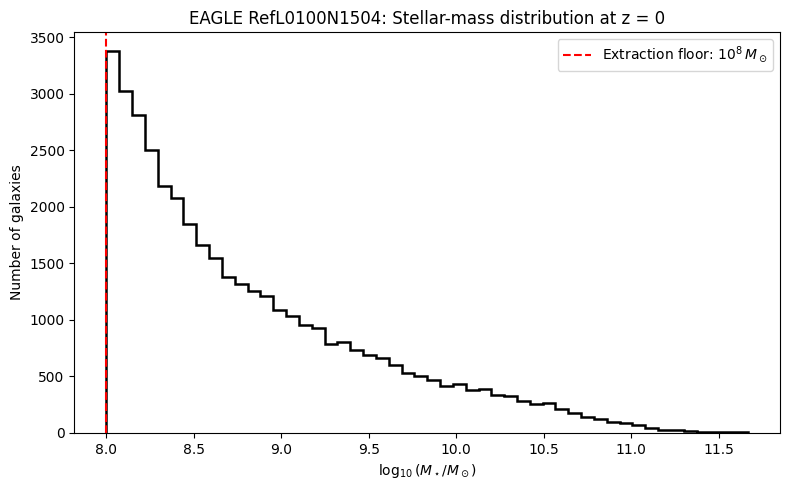

In [146]:
eagle["logMstar"] = np.log10(
    eagle["Mstar_30pkpc"]
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    eagle["logMstar"],
    bins=50,
    histtype="step",
    linewidth=1.8,
    color="black"
)

ax.axvline(
    8.0,
    linestyle="--",
    color="red",
    label=r"Extraction floor: $10^8\,M_\odot$"
)

ax.set_xlabel(
    r"$\log_{10}(M_\star/M_\odot)$"
)

ax.set_ylabel("Number of galaxies")

ax.set_title(
    "EAGLE RefL0100N1504: "
    "Stellar-mass distribution at z = 0"
)

ax.legend()

plt.tight_layout()
plt.show()

In [147]:
# Candidate stellar-mass thresholds
log_mass_limits = np.array([
    8.0, 8.5, 9.0, 9.5, 10.0
])

# EAGLE box volume in comoving Mpc^3
box_volume = BOX_SIZE_CMPC**3

# GW190814 90% HPD-equivalent volume
mock_volume = V90

results = []

for log_limit in log_mass_limits:

    mass_limit = 10**log_limit

    selected = eagle[
        eagle["Mstar_30pkpc"] > mass_limit
    ]

    n_galaxies = len(selected)

    number_density = n_galaxies / box_volume

    # Mean expected count in an equivalent volume
    expected_count = number_density * mock_volume

    results.append({
        "logM_limit": log_limit,
        "N_box": n_galaxies,
        "number_density_cMpc3": number_density,
        "expected_N_mock": expected_count
    })

threshold_df = pd.DataFrame(results)

display(
    threshold_df.round({
        "number_density_cMpc3": 5,
        "expected_N_mock": 1
    })
)

,logM_limit,N_box,number_density_cMpc3,expected_N_mock
0,8.0,40076,0.04008,1269.0
1,8.5,22580,0.02258,715.0
2,9.0,13200,0.01320,418.0
3,9.5,7241,0.00724,229.3
4,10.0,3562,0.00356,112.8


In [148]:
# Provisional primary stellar-mass threshold
LOG_MASS_MIN = 9.0
MASS_MIN = 10**LOG_MASS_MIN

# Select galaxies above threshold
eagle_science = eagle.loc[
    eagle["Mstar_30pkpc"] >= MASS_MIN
].copy()

# Fix random seed for reproducibility
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Cube side length from GW190814 3D volume
L = V90**(1 / 3)

# Uniformly position the cube entirely inside
# the EAGLE simulation box
cube_origin = rng.uniform(
    0,
    BOX_SIZE_CMPC - L,
    size=3
)

cube_upper = cube_origin + L

# Select galaxies within the cube
position_columns = ["x", "y", "z"]
positions = eagle_science[position_columns].to_numpy()

inside = np.all(
    (positions >= cube_origin)
    & (positions < cube_upper),
    axis=1
)

reference_cube = eagle_science.loc[inside].copy()

print("REFERENCE EAGLE CUBE")
print("-" * 45)
print(f"Random seed: {RANDOM_SEED}")
print(f"Stellar-mass threshold: 10^{LOG_MASS_MIN:.1f} Msun")
print(f"Cube side length: {L:.3f} cMpc")
print(f"Cube volume: {L**3:,.2f} cMpc³")
print(f"Cube origin: {cube_origin.round(3)}")
print(f"Galaxies selected: {len(reference_cube):,}")

display(reference_cube.head())

REFERENCE EAGLE CUBE
---------------------------------------------
Random seed: 42
Stellar-mass threshold: 10^9.0 Msun
Cube side length: 31.637 cMpc
Cube volume: 31,665.93 cMpc³
Cube origin: [52.91  30.003 58.696]
Galaxies selected: 402


,GalaxyID,SnapNum,x,y,z,Mstar_30pkpc,Mgas_30pkpc,SFR_30pkpc,GroupID,SubGroupNumber,logMstar
147,12387853,28,55.954685,46.836952,78.147629,2.887872e+09,2.790637e+09,0.126163,28000000004849,0,9.460578
209,9815878,28,68.455559,55.367146,77.979416,3.334509e+10,3.499430e+09,1.137328,28000000001676,0,10.523032
290,9938600,28,53.934929,57.452042,84.517723,1.132788e+10,4.834770e+09,0.548920,28000000001782,0,10.054149
303,10300541,28,71.326813,54.998787,69.391090,5.950605e+09,1.406845e+09,0.309663,28000000002133,0,9.774561
350,11424252,28,58.689266,43.915962,63.224422,5.411926e+09,6.449043e+08,0.307598,28000000003418,0,9.733352


In [149]:
# Confirm that the reference cube satisfies
# all of our selection requirements.

assert reference_cube["GalaxyID"].is_unique

assert (
    reference_cube["Mstar_30pkpc"] >= MASS_MIN
).all()

assert np.all(
    (reference_cube[["x", "y", "z"]].to_numpy()
     >= cube_origin)
    &
    (reference_cube[["x", "y", "z"]].to_numpy()
     < cube_upper)
)

# Summarise the galaxy population

n_gal = len(reference_cube)
n_zero_sfr = (reference_cube["SFR_30pkpc"] == 0).sum()

summary = pd.Series({
    "Galaxy count": n_gal,
    "Number density (cMpc^-3)": n_gal / V90,
    "Median log stellar mass": reference_cube["logMstar"].median(),
    "Maximum log stellar mass": reference_cube["logMstar"].max(),
    "Median SFR (Msun/yr)": reference_cube["SFR_30pkpc"].median(),
    "Zero-SFR fraction": n_zero_sfr / n_gal,
    "Distinct GroupIDs": reference_cube["GroupID"].nunique()
})

display(summary.to_frame("Value"))

,Value
Galaxy count,402.000000
Number density (cMpc^-3),0.012695
Median log stellar mass,9.538293
Maximum log stellar mass,11.410273
Median SFR (Msun/yr),0.133528
Zero-SFR fraction,0.181592
Distinct GroupIDs,237.000000


In [150]:
# Save the actual reference galaxy population
reference_path = DATA / "EAGLE_reference_cube_seed42.csv"

reference_cube.to_csv(
    reference_path,
    index=False
)

# Record the exact configuration
cube_config = {
    "simulation": SIMULATION,
    "snapshot": SNAPSHOT,
    "redshift": 0.0,
    "stellar_mass_threshold_msun": float(MASS_MIN),
    "random_seed": RANDOM_SEED,
    "box_size_comoving_mpc": BOX_SIZE_CMPC,
    "cube_origin_comoving_mpc": cube_origin.tolist(),
    "cube_upper_comoving_mpc": cube_upper.tolist(),
    "cube_side_comoving_mpc": float(L),
    "cube_volume_comoving_mpc3": float(L**3),
    "galaxy_count": int(len(reference_cube)),
    "boundary_handling": "cube entirely inside simulation box"
}

config_path = DATA / "EAGLE_reference_cube_config.json"

with open(config_path, "w") as f:
    json.dump(cube_config, f, indent=2)

print("Reference cube saved:", reference_path)
print("Configuration saved:", config_path)

Reference cube saved: data/EAGLE_reference_cube_seed42.csv
Configuration saved: data/EAGLE_reference_cube_config.json


In [151]:
def sample_periodic_cube(
    catalogue,
    origin,
    side_length,
    box_size=100.0
):
    """
    Select galaxies inside a cube in a periodic
    cosmological simulation box.

    Parameters
    ----------
    catalogue : pandas.DataFrame
        Galaxy catalogue containing x, y, z.
    origin : array-like, length 3
        Cube origin in comoving Mpc.
    side_length : float
        Cube side length in comoving Mpc.
    box_size : float
        Simulation box side length in comoving Mpc.

    Returns
    -------
    pandas.DataFrame
        Galaxies contained in the periodic cube.
    """

    origin = np.asarray(origin, dtype=float)

    assert origin.shape == (3,)
    assert 0 < side_length <= box_size

    positions = catalogue[
        ["x", "y", "z"]
    ].to_numpy(dtype=float)

    # Position relative to the cube origin,
    # wrapping across periodic boundaries
    relative = (
        positions - origin
    ) % box_size

    inside = np.all(
        relative < side_length,
        axis=1
    )

    return catalogue.loc[inside].copy()

In [152]:
# Repeat reference cube selection using
# the periodic implementation

periodic_reference = sample_periodic_cube(
    catalogue=eagle_science,
    origin=cube_origin,
    side_length=L,
    box_size=BOX_SIZE_CMPC
)

original_ids = set(reference_cube["GalaxyID"])
periodic_ids = set(periodic_reference["GalaxyID"])

assert original_ids == periodic_ids, (
    "Periodic and non-periodic selections differ."
)

print("PASS: Periodic selection reproduces reference cube.")
print("Galaxy count:", len(periodic_reference))

PASS: Periodic selection reproduces reference cube.
Galaxy count: 402


In [153]:
# Artificial catalogue for boundary testing
test_galaxies = pd.DataFrame({
    "GalaxyID": [1, 2, 3, 4],
    "x": [98.0, 2.0, 50.0, 99.0],
    "y": [98.0, 2.0, 50.0, 1.0],
    "z": [98.0, 2.0, 50.0, 99.0]
})

# Cube extends from 95 to 105 on each axis,
# wrapping around the 100 cMpc boundary.
test_cube = sample_periodic_cube(
    catalogue=test_galaxies,
    origin=[95.0, 95.0, 95.0],
    side_length=10.0,
    box_size=100.0
)

# Galaxies 1, 2 and 4 should be included.
assert set(test_cube["GalaxyID"]) == {1, 2, 4}

print("PASS: Periodic boundary wrapping works correctly.")

PASS: Periodic boundary wrapping works correctly.


In [154]:
N_CUBES = 500
ENSEMBLE_SEED = 12345

rng = np.random.default_rng(ENSEMBLE_SEED)

cube_records = []

for cube_id in range(N_CUBES):

    origin = rng.uniform(
        0,
        BOX_SIZE_CMPC,
        size=3
    )

    mock = sample_periodic_cube(
        catalogue=eagle_science,
        origin=origin,
        side_length=L,
        box_size=BOX_SIZE_CMPC
    )

    n = len(mock)

    cube_records.append({
        "cube_id": cube_id,
        "origin_x": origin[0],
        "origin_y": origin[1],
        "origin_z": origin[2],
        "N_galaxies": n,
        "number_density": n / V90,
        "median_logMstar": (
            mock["logMstar"].median()
            if n > 0 else np.nan
        ),
        "median_SFR": (
            mock["SFR_30pkpc"].median()
            if n > 0 else np.nan
        ),
        "zero_SFR_fraction": (
            (mock["SFR_30pkpc"] == 0).mean()
            if n > 0 else np.nan
        ),
        "total_stellar_mass": (
            mock["Mstar_30pkpc"].sum()
        ),
        "total_SFR": (
            mock["SFR_30pkpc"].sum()
        )
    })

ensemble = pd.DataFrame(cube_records)

assert len(ensemble) == N_CUBES
assert ensemble["N_galaxies"].ge(0).all()

display(ensemble.head())

print(f"\nGenerated {N_CUBES} periodic mock volumes.")

,cube_id,origin_x,origin_y,origin_z,N_galaxies,number_density,median_logMstar,median_SFR,zero_SFR_fraction,total_stellar_mass,total_SFR
0,0,22.733602,31.675834,79.736546,440,0.013895,9.595505,0.154030,0.161364,5.031541e+12,159.328857
1,1,67.625467,39.110955,33.281393,647,0.020432,9.564050,0.125409,0.204019,8.303957e+12,254.166367
2,2,59.830875,18.673419,67.275604,335,0.010579,9.570224,0.167062,0.110448,4.146894e+12,141.501801
3,3,94.180287,24.824571,94.888115,234,0.007390,9.484066,0.193414,0.102564,2.251755e+12,93.595169
4,4,66.723745,9.589794,44.183967,532,0.016800,9.563738,0.152211,0.184211,6.533456e+12,257.141052



Generated 500 periodic mock volumes.


In [155]:
summary_for_writeup = pd.DataFrame({
    "Property": [
        "Number of galaxies",
        r"Median $\log_{10}(M_\star/M_\odot)$",
        r"Median SFR ($M_\odot\,\mathrm{yr}^{-1}$)",
        "Zero-SFR fraction",
        r"Total stellar mass ($M_\odot$)",
        r"Total SFR ($M_\odot\,\mathrm{yr}^{-1}$)"
    ],
    "Median": [
        ensemble["N_galaxies"].median(),
        ensemble["median_logMstar"].median(),
        ensemble["median_SFR"].median(),
        ensemble["zero_SFR_fraction"].median(),
        ensemble["total_stellar_mass"].median(),
        ensemble["total_SFR"].median()
    ],
    "16th percentile": [
        ensemble["N_galaxies"].quantile(0.16),
        ensemble["median_logMstar"].quantile(0.16),
        ensemble["median_SFR"].quantile(0.16),
        ensemble["zero_SFR_fraction"].quantile(0.16),
        ensemble["total_stellar_mass"].quantile(0.16),
        ensemble["total_SFR"].quantile(0.16)
    ],
    "84th percentile": [
        ensemble["N_galaxies"].quantile(0.84),
        ensemble["median_logMstar"].quantile(0.84),
        ensemble["median_SFR"].quantile(0.84),
        ensemble["zero_SFR_fraction"].quantile(0.84),
        ensemble["total_stellar_mass"].quantile(0.84),
        ensemble["total_SFR"].quantile(0.84)
    ],
    "Minimum": [
        ensemble["N_galaxies"].min(),
        ensemble["median_logMstar"].min(),
        ensemble["median_SFR"].min(),
        ensemble["zero_SFR_fraction"].min(),
        ensemble["total_stellar_mass"].min(),
        ensemble["total_SFR"].min()
    ],
    "Maximum": [
        ensemble["N_galaxies"].max(),
        ensemble["median_logMstar"].max(),
        ensemble["median_SFR"].max(),
        ensemble["zero_SFR_fraction"].max(),
        ensemble["total_stellar_mass"].max(),
        ensemble["total_SFR"].max()
    ]
})

summary_for_writeup

,Property,Median,16th percentile,84th percentile,Minimum,Maximum
0,Number of galaxies,3.805000e+02,2.156800e+02,6.226400e+02,8.100000e+01,1.426000e+03
1,Median $\log_{10}(M_\star/M_\odot)$,9.563968e+00,9.517296e+00,9.600317e+00,9.340024e+00,9.693915e+00
2,"Median SFR ($M_\odot\,\mathrm{yr}^{-1}$)",1.523377e-01,1.005304e-01,1.862919e-01,0.000000e+00,2.489420e-01
3,Zero-SFR fraction,1.692781e-01,8.568421e-02,2.989430e-01,6.172840e-03,5.361184e-01
4,Total stellar mass ($M_\odot$),4.570324e+12,2.182685e+12,7.972172e+12,6.721946e+11,2.087515e+13
5,"Total SFR ($M_\odot\,\mathrm{yr}^{-1}$)",1.564683e+02,8.629304e+01,2.464690e+02,2.306959e+01,4.884771e+02


In [156]:
summary_display = summary_for_writeup.copy()

summary_display.loc[0, summary_display.columns[1:]] = summary_display.loc[0, summary_display.columns[1:]].round(0)
summary_display.loc[1, summary_display.columns[1:]] = summary_display.loc[1, summary_display.columns[1:]].round(3)
summary_display.loc[2, summary_display.columns[1:]] = summary_display.loc[2, summary_display.columns[1:]].round(3)
summary_display.loc[3, summary_display.columns[1:]] = summary_display.loc[3, summary_display.columns[1:]].round(3)
summary_display.loc[4, summary_display.columns[1:]] = summary_display.loc[4, summary_display.columns[1:]].map(lambda x: f"{x:.2e}")
summary_display.loc[5, summary_display.columns[1:]] = summary_display.loc[5, summary_display.columns[1:]].round(2)

display(summary_display)

/tmp/ipykernel_1534/717540742.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '4.57e+12' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  summary_display.loc[4, summary_display.columns[1:]] = summary_display.loc[4, summary_display.columns[1:]].map(lambda x: f"{x:.2e}")
/tmp/ipykernel_1534/717540742.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '2.18e+12' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  summary_display.loc[4, summary_display.columns[1:]] = summary_display.loc[4, summary_display.columns[1:]].map(lambda x: f"{x:.2e}")
/tmp/ipykernel_1534/717540742.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '7.97e+12' has dtype incompatible with f

,Property,Median,16th percentile,84th percentile,Minimum,Maximum
0,Number of galaxies,380.5,215.68,622.64,81.0,1426.0
1,Median $\log_{10}(M_\star/M_\odot)$,9.563968,9.517296,9.600317,9.340024,9.693915
2,"Median SFR ($M_\odot\,\mathrm{yr}^{-1}$)",0.152338,0.10053,0.186292,0.0,0.248942
3,Zero-SFR fraction,0.169278,0.085684,0.298943,0.006173,0.536118
4,Total stellar mass ($M_\odot$),4.57e+12,2.18e+12,7.97e+12,6.72e+11,2.09e+13
5,"Total SFR ($M_\odot\,\mathrm{yr}^{-1}$)",156.468292,86.293039,246.469045,23.06959,488.477051


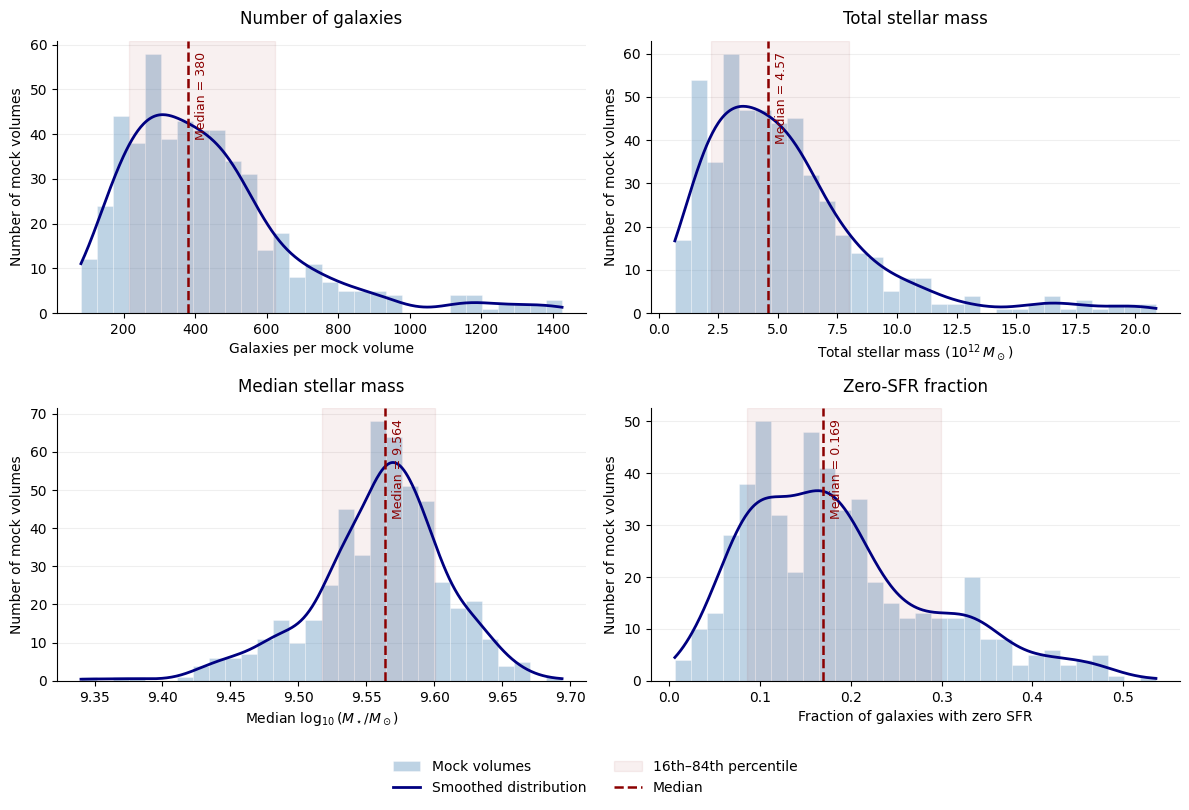

In [157]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# --------------------------------------------------
# Configuration
# --------------------------------------------------

plot_specs = [
    {
        "column": "N_galaxies",
        "title": "Number of galaxies",
        "xlabel": "Galaxies per mock volume",
        "scale": 1,
        "precision": 0
    },
    {
        "column": "total_stellar_mass",
        "title": "Total stellar mass",
        "xlabel": r"Total stellar mass ($10^{12}\,M_\odot$)",
        "scale": 1e12,
        "precision": 2
    },
    {
        "column": "median_logMstar",
        "title": "Median stellar mass",
        "xlabel": r"Median $\log_{10}(M_\star/M_\odot)$",
        "scale": 1,
        "precision": 3
    },
    {
        "column": "zero_SFR_fraction",
        "title": "Zero-SFR fraction",
        "xlabel": "Fraction of galaxies with zero SFR",
        "scale": 1,
        "precision": 3
    }
]

# --------------------------------------------------
# Create figure
# --------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8)
)

for ax, spec in zip(axes.flat, plot_specs):

    values = (
        ensemble[spec["column"]]
        .dropna()
        .to_numpy(dtype=float)
        / spec["scale"]
    )

    # Summary statistics
    median = np.median(values)
    p16, p84 = np.percentile(values, [16, 84])

    # Histogram: actual number of mock volumes
    counts, edges, _ = ax.hist(
        values,
        bins=30,
        color="steelblue",
        alpha=0.35,
        edgecolor="white",
        linewidth=0.7,
        label="Mock volumes"
    )

    # Kernel density estimate
    kde = gaussian_kde(values)

    x_grid = np.linspace(
        values.min(),
        values.max(),
        500
    )

    # Convert KDE density into expected bin counts
    bin_width = np.mean(np.diff(edges))

    kde_counts = (
        kde(x_grid)
        * len(values)
        * bin_width
    )

    ax.plot(
        x_grid,
        kde_counts,
        color="navy",
        linewidth=2,
        label="Smoothed distribution"
    )

    # Central 68% interval
    ax.axvspan(
        p16,
        p84,
        color="darkred",
        alpha=0.06,
        label="16th–84th percentile"
    )

    # Median line
    ax.axvline(
        median,
        color="darkred",
        linewidth=1.8,
        linestyle="--",
        label="Median"
    )

    # --------------------------------------------------
    # Numerical median label
    # --------------------------------------------------

    precision = spec["precision"]

    median_label = (
        f"Median = {median:.{precision}f}"
    )

    # Position label near the top of the line
    ax.annotate(
        median_label,
        xy=(median, 0.96),
        xycoords=ax.get_xaxis_transform(),
        xytext=(5, 0),
        textcoords="offset points",
        rotation=90,
        ha="left",
        va="top",
        fontsize=9,
        color="darkred"
    )

    # --------------------------------------------------
    # Formatting
    # --------------------------------------------------

    ax.set_title(
        spec["title"],
        fontsize=12,
        pad=12
    )

    ax.set_xlabel(spec["xlabel"])
    ax.set_ylabel("Number of mock volumes")

    ax.grid(
        axis="y",
        alpha=0.2
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# --------------------------------------------------
# Shared legend
# --------------------------------------------------

handles, labels = axes.flat[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, -0.015)
)

# No overall figure title:
# the dissertation figure caption will serve
# that purpose.

plt.tight_layout(
    rect=[0, 0.065, 1, 1]
)

# --------------------------------------------------
# Save high-resolution outputs
# --------------------------------------------------

fig.savefig(
    "EAGLE_population_distributions.pdf",
    bbox_inches="tight"
)

fig.savefig(
    "EAGLE_population_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [158]:
from scipy.stats import spearmanr

mass_thresholds = [8.0, 8.5, 9.0, 9.5]

threshold_records = []

# Use EXACTLY the same 500 cube origins
# to isolate the effect of changing the mass threshold.

for log_limit in mass_thresholds:

    catalogue = eagle.loc[
        eagle["Mstar_30pkpc"] >= 10**log_limit
    ].copy()

    for _, row in ensemble.iterrows():

        origin = row[
            ["origin_x", "origin_y", "origin_z"]
        ].to_numpy(dtype=float)

        mock = sample_periodic_cube(
            catalogue,
            origin,
            L,
            BOX_SIZE_CMPC
        )

        n = len(mock)

        threshold_records.append({
            "threshold": log_limit,
            "cube_id": int(row["cube_id"]),
            "N_galaxies": n,
            "zero_SFR_fraction": (
                (mock["SFR_30pkpc"] == 0).mean()
                if n > 0 else np.nan
            ),
            "median_logMstar": (
                np.log10(mock["Mstar_30pkpc"]).median()
                if n > 0 else np.nan
            ),
            "total_stellar_mass": mock["Mstar_30pkpc"].sum(),
            "total_SFR": mock["SFR_30pkpc"].sum()
        })

threshold_results = pd.DataFrame(threshold_records)

summary_records = []

for limit, group in threshold_results.groupby("threshold"):

    rho, _ = spearmanr(
        group["N_galaxies"],
        group["zero_SFR_fraction"],
        nan_policy="omit"
    )

    summary_records.append({
        "logM_min": limit,
        "median_N": group["N_galaxies"].median(),
        "N_16": group["N_galaxies"].quantile(0.16),
        "N_84": group["N_galaxies"].quantile(0.84),
        "median_zero_SFR_fraction":
            group["zero_SFR_fraction"].median(),
        "Spearman_rho": rho
    })

threshold_summary = pd.DataFrame(summary_records)

display(threshold_summary.round(3))

threshold_results.to_csv(
    DATA / "EAGLE_mass_threshold_sensitivity.csv",
    index=False
)

,logM_min,median_N,N_16,N_84,median_zero_SFR_fraction,Spearman_rho
0,8.0,1182.5,682.84,1839.80,0.375,0.893
1,8.5,664.0,382.52,1051.44,0.244,0.871
2,9.0,380.5,215.68,622.64,0.169,0.843
3,9.5,215.0,110.84,333.16,0.130,0.808


In [159]:
# ============================================================
# CELL 33
# Stellar-mass threshold sensitivity:
# retained stellar mass and star formation
# ============================================================

import numpy as np
import pandas as pd

MASS_THRESHOLDS = [8.0, 8.5, 9.0, 9.5]

# ------------------------------------------------------------
# 1. Retained fractions across the full EAGLE parent catalogue
# ------------------------------------------------------------

parent_total_mass = eagle["Mstar_30pkpc"].sum()
parent_total_sfr = eagle["SFR_30pkpc"].sum()
parent_count = len(eagle)

box_records = []

for log_limit in MASS_THRESHOLDS:

    selected = eagle.loc[
        eagle["Mstar_30pkpc"] >= 10**log_limit
    ]

    box_records.append({
        "logM_min": log_limit,
        "N_galaxies": len(selected),
        "galaxies_retained_pct":
            100 * len(selected) / parent_count,
        "stellar_mass_retained_pct":
            100 * selected["Mstar_30pkpc"].sum()
            / parent_total_mass,
        "SFR_retained_pct":
            100 * selected["SFR_30pkpc"].sum()
            / parent_total_sfr
    })

box_retention = pd.DataFrame(box_records)

print("FULL EAGLE BOX: RETAINED FRACTIONS")
display(box_retention.round(2))


# ------------------------------------------------------------
# 2. Retained fractions within each of the 500 mock volumes
# ------------------------------------------------------------

cube_records = []

for _, row in ensemble.iterrows():

    origin = row[
        ["origin_x", "origin_y", "origin_z"]
    ].to_numpy(dtype=float)

    # Extract the full parent population above 10^8 Msun
    mock_parent = sample_periodic_cube(
        catalogue=eagle,
        origin=origin,
        side_length=L,
        box_size=BOX_SIZE_CMPC
    )

    reference_mass = mock_parent["Mstar_30pkpc"].sum()
    reference_sfr = mock_parent["SFR_30pkpc"].sum()
    reference_count = len(mock_parent)

    for log_limit in MASS_THRESHOLDS:

        selected = mock_parent.loc[
            mock_parent["Mstar_30pkpc"] >= 10**log_limit
        ]

        cube_records.append({
            "cube_id": int(row["cube_id"]),
            "logM_min": log_limit,

            "galaxies_retained_pct":
                100 * len(selected) / reference_count
                if reference_count > 0 else np.nan,

            "stellar_mass_retained_pct":
                100 * selected["Mstar_30pkpc"].sum()
                / reference_mass
                if reference_mass > 0 else np.nan,

            "SFR_retained_pct":
                100 * selected["SFR_30pkpc"].sum()
                / reference_sfr
                if reference_sfr > 0 else np.nan
        })

cube_retention = pd.DataFrame(cube_records)


# ------------------------------------------------------------
# 3. Summarise variation between mock volumes
# ------------------------------------------------------------

summary_records = []

for log_limit, group in cube_retention.groupby("logM_min"):

    record = {"logM_min": log_limit}

    for column in [
        "galaxies_retained_pct",
        "stellar_mass_retained_pct",
        "SFR_retained_pct"
    ]:

        values = group[column].dropna()

        record[column + "_median"] = values.median()
        record[column + "_p16"] = values.quantile(0.16)
        record[column + "_p84"] = values.quantile(0.84)

    summary_records.append(record)

retention_summary = pd.DataFrame(summary_records)

print("\n500 MOCK VOLUMES: RETAINED FRACTIONS")
display(retention_summary.round(2))


# ------------------------------------------------------------
# 4. Save results
# ------------------------------------------------------------

box_retention.to_csv(
    DATA / "EAGLE_box_mass_threshold_retention.csv",
    index=False
)

cube_retention.to_csv(
    DATA / "EAGLE_cube_mass_threshold_retention.csv",
    index=False
)

retention_summary.to_csv(
    DATA / "EAGLE_mass_threshold_retention_summary.csv",
    index=False
)

print("\nRetention analysis completed and saved.")

FULL EAGLE BOX: RETAINED FRACTIONS


,logM_min,N_galaxies,galaxies_retained_pct,stellar_mass_retained_pct,SFR_retained_pct
0,8.0,40076,100.00,100.000000,100.000000
1,8.5,22580,56.34,98.180000,97.290001
2,9.0,13200,32.94,95.029999,92.480003
3,9.5,7241,18.07,88.709999,81.459999



500 MOCK VOLUMES: RETAINED FRACTIONS


,logM_min,galaxies_retained_pct_median,galaxies_retained_pct_p16,galaxies_retained_pct_p84,stellar_mass_retained_pct_median,stellar_mass_retained_pct_p16,stellar_mass_retained_pct_p84,SFR_retained_pct_median,SFR_retained_pct_p16,SFR_retained_pct_p84
0,8.0,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
1,8.5,56.05,54.07,57.83,98.09,97.64,98.38,97.47,96.32,98.03
2,9.0,32.72,30.75,34.47,94.83,93.77,95.53,92.23,90.05,93.71
3,9.5,17.84,16.01,19.11,88.37,85.79,89.63,80.85,76.49,83.63



Retention analysis completed and saved.


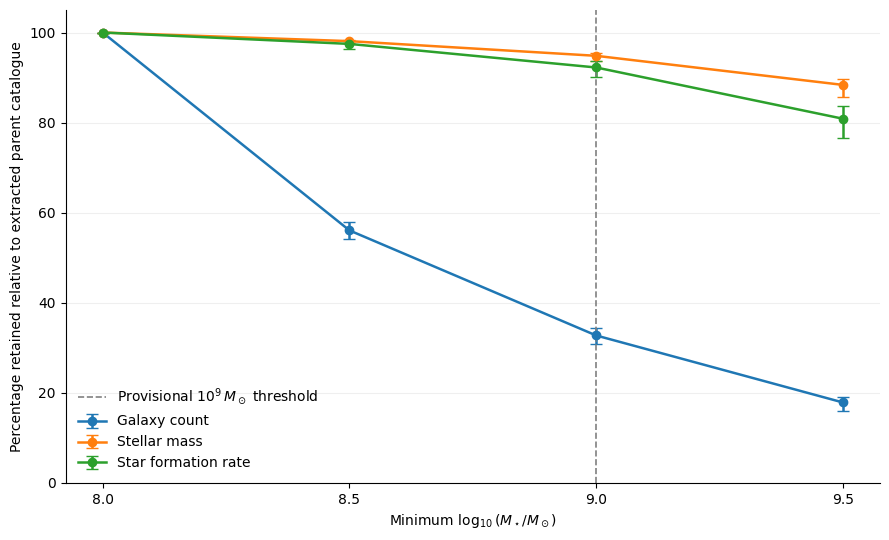

In [160]:
# ============================================================
# CELL 34
# Visualise galaxy, stellar-mass and SFR retention
# ============================================================

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5.5))

properties = [
    ("galaxies_retained_pct", "Galaxy count"),
    ("stellar_mass_retained_pct", "Stellar mass"),
    ("SFR_retained_pct", "Star formation rate")
]

for column, label in properties:

    medians = retention_summary[
        column + "_median"
    ].to_numpy()

    lower = retention_summary[
        column + "_p16"
    ].to_numpy()

    upper = retention_summary[
        column + "_p84"
    ].to_numpy()

    ax.errorbar(
        retention_summary["logM_min"],
        medians,
        yerr=[
            medians - lower,
            upper - medians
        ],
        marker="o",
        markersize=6,
        linewidth=1.8,
        capsize=4,
        label=label
    )

# Indicate our provisional threshold
ax.axvline(
    9.0,
    color="grey",
    linestyle="--",
    linewidth=1.2,
    label=r"Provisional $10^9\,M_\odot$ threshold"
)

ax.set_xlabel(
    r"Minimum $\log_{10}(M_\star/M_\odot)$"
)

ax.set_ylabel(
    "Percentage retained relative to extracted parent catalogue"
)

ax.set_ylim(0, 105)

ax.set_xticks(MASS_THRESHOLDS)

ax.grid(
    axis="y",
    alpha=0.2
)

ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

fig.savefig(
    "EAGLE_stellar_mass_threshold_retention.pdf",
    bbox_inches="tight"
)

fig.savefig(
    "EAGLE_stellar_mass_threshold_retention.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [161]:
properties = [
    "N_galaxies",
    "median_logMstar",
    "median_SFR",
    "zero_SFR_fraction",
    "total_stellar_mass",
    "total_SFR"
]

summary_rows = []

for name in properties:

    values = ensemble[name].dropna()

    summary_rows.append({
        "Property": name,
        "Median": values.median(),
        "16th percentile": values.quantile(0.16),
        "84th percentile": values.quantile(0.84),
        "Minimum": values.min(),
        "Maximum": values.max()
    })

ensemble_summary = pd.DataFrame(summary_rows)

display(ensemble_summary)

,Property,Median,16th percentile,84th percentile,Minimum,Maximum
0,N_galaxies,3.805000e+02,2.156800e+02,6.226400e+02,8.100000e+01,1.426000e+03
1,median_logMstar,9.563968e+00,9.517296e+00,9.600317e+00,9.340024e+00,9.693915e+00
2,median_SFR,1.523377e-01,1.005304e-01,1.862919e-01,0.000000e+00,2.489420e-01
3,zero_SFR_fraction,1.692781e-01,8.568421e-02,2.989430e-01,6.172840e-03,5.361184e-01
4,total_stellar_mass,4.570324e+12,2.182685e+12,7.972172e+12,6.721946e+11,2.087515e+13
5,total_SFR,1.564683e+02,8.629304e+01,2.464690e+02,2.306959e+01,4.884771e+02


In [162]:
ensemble_path = DATA / "EAGLE_500_periodic_mock_volumes.csv"

ensemble.to_csv(
    ensemble_path,
    index=False
)

ensemble_config = {
    "simulation": SIMULATION,
    "snapshot": SNAPSHOT,
    "number_of_cubes": N_CUBES,
    "random_seed": ENSEMBLE_SEED,
    "stellar_mass_threshold_msun": float(MASS_MIN),
    "cube_side_comoving_mpc": float(L),
    "cube_volume_comoving_mpc3": float(V90),
    "simulation_box_side_comoving_mpc": BOX_SIZE_CMPC,
    "sampling": "uniform random origins with periodic wrapping",
    "overlap_allowed": True
}

with open(
    DATA / "EAGLE_500_periodic_mock_volumes_config.json",
    "w"
) as f:
    json.dump(ensemble_config, f, indent=2)

print("Saved:", ensemble_path)

Saved: data/EAGLE_500_periodic_mock_volumes.csv


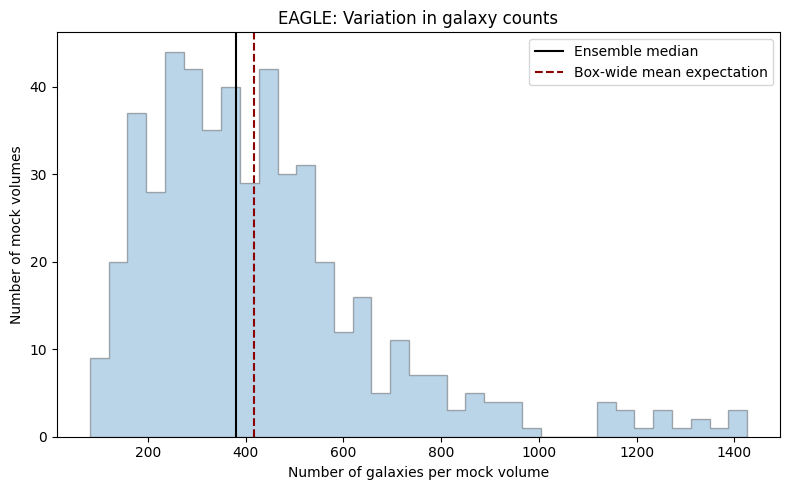

In [163]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    ensemble["N_galaxies"],
    bins=35,
    histtype="stepfilled",
    alpha=0.3,
    edgecolor="black"
)

ax.axvline(
    ensemble["N_galaxies"].median(),
    color="black",
    linewidth=1.5,
    label="Ensemble median"
)

ax.axvline(
    threshold_df.loc[
        threshold_df["logM_limit"] == 9.0,
        "expected_N_mock"
    ].iloc[0],
    color="darkred",
    linestyle="--",
    linewidth=1.5,
    label="Box-wide mean expectation"
)

ax.set_xlabel("Number of galaxies per mock volume")
ax.set_ylabel("Number of mock volumes")
ax.set_title("EAGLE: Variation in galaxy counts")

ax.legend()
plt.tight_layout()
plt.show()

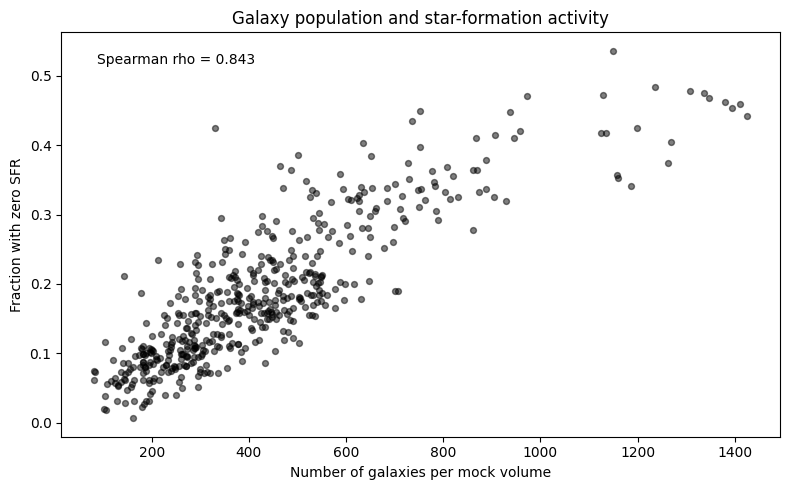

Spearman correlation: 0.8428
Nominal p-value: 4.345e-136


In [164]:
from scipy.stats import spearmanr

x = ensemble["N_galaxies"]
y = ensemble["zero_SFR_fraction"]

rho, p_value = spearmanr(x, y)

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    x,
    y,
    s=18,
    alpha=0.5,
    color="black"
)

ax.set_xlabel("Number of galaxies per mock volume")
ax.set_ylabel("Fraction with zero SFR")
ax.set_title("Galaxy population and star-formation activity")

ax.text(
    0.05,
    0.95,
    f"Spearman rho = {rho:.3f}",
    transform=ax.transAxes,
    va="top"
)

plt.tight_layout()
plt.show()

print(f"Spearman correlation: {rho:.4f}")
print(f"Nominal p-value: {p_value:.4g}")

In [165]:
mass_bins = [
    (9.0, 9.5),
    (9.5, 10.0),
    (10.0, 10.5),
    (10.5, np.inf)
]

records = []

for _, cube in ensemble.iterrows():

    origin = cube[
        ["origin_x", "origin_y", "origin_z"]
    ].to_numpy(dtype=float)

    mock = sample_periodic_cube(
        eagle_science,
        origin,
        L,
        BOX_SIZE_CMPC
    )

    for lower, upper in mass_bins:

        subset = mock[
            (mock["logMstar"] >= lower)
            & (mock["logMstar"] < upper)
        ]

        records.append({
            "cube_id": int(cube["cube_id"]),
            "N_galaxies": len(mock),
            "mass_bin": f"{lower:.1f}–{upper:.1f}",
            "N_in_bin": len(subset),
            "zero_SFR_fraction": (
                (subset["SFR_30pkpc"] == 0).mean()
                if len(subset) > 0 else np.nan
            )
        })

mass_bin_results = pd.DataFrame(records)

for mass_bin, group in mass_bin_results.groupby("mass_bin"):

    valid_group = group[
        group["N_in_bin"] >= 10
    ].dropna()

    rho, p = spearmanr(
        valid_group["N_galaxies"],
        valid_group["zero_SFR_fraction"]
    )

    print(
        f"{mass_bin}: "
        f"rho={rho:.3f}, "
        f"cubes={len(valid_group)}"
    )

10.0–10.5: rho=0.696, cubes=499
10.5–inf: rho=0.561, cubes=484
9.0–9.5: rho=0.838, cubes=500
9.5–10.0: rho=0.799, cubes=500


In [166]:
# ============================================================
# CELL 37
# Flat, stellar-mass and SFR host priors
# ============================================================

import numpy as np
import pandas as pd


def normalise_host_weights(weights):
    """
    Convert non-negative astrophysical host weights
    into normalised relative host probabilities.

    The resulting probabilities must sum to unity.
    """

    weights = np.asarray(weights, dtype=float)

    if weights.ndim != 1 or len(weights) == 0:
        raise ValueError("Weights must be a non-empty 1D array.")

    if not np.all(np.isfinite(weights)):
        raise ValueError("Host weights contain non-finite values.")

    if np.any(weights < 0):
        raise ValueError("Host weights cannot be negative.")

    # Scaling prevents overflow when summing large weights.
    scale = np.max(weights)

    if scale <= 0:
        raise ValueError(
            "All host weights are zero; "
            "this prior cannot be normalised."
        )

    scaled_weights = weights / scale
    probabilities = scaled_weights / scaled_weights.sum()

    np.testing.assert_allclose(
        probabilities.sum(),
        1.0,
        rtol=1e-12,
        atol=1e-12
    )

    return probabilities


def apply_host_priors(catalogue):
    """
    Apply three host-prior models to an EAGLE
    mock galaxy population.

    Returns the galaxy catalogue with additional
    columns containing normalised probabilities.
    """

    result = catalogue.copy()

    if result.empty:
        raise ValueError("The mock volume contains no galaxies.")

    if not result["GalaxyID"].is_unique:
        raise ValueError("Duplicate galaxy IDs detected.")

    # Raw astrophysical host weights
    flat_weights = np.ones(len(result), dtype=float)

    mass_weights = result[
        "Mstar_30pkpc"
    ].to_numpy(dtype=float)

    sfr_weights = result[
        "SFR_30pkpc"
    ].to_numpy(dtype=float)

    # Normalised relative probabilities
    result["P_flat"] = normalise_host_weights(
        flat_weights
    )

    result["P_mass"] = normalise_host_weights(
        mass_weights
    )

    result["P_SFR"] = normalise_host_weights(
        sfr_weights
    )

    return result

In [167]:
# ============================================================
# CELL 38
# Controlled test of host-prior normalisation
# ============================================================

test_sample = pd.DataFrame({
    "GalaxyID": [1, 2, 3],
    "Mstar_30pkpc": [1e9, 2e9, 7e9],
    "SFR_30pkpc": [0.0, 1.0, 3.0]
})

test_result = apply_host_priors(test_sample)

# Flat prior: every galaxy receives 1/3
np.testing.assert_allclose(
    test_result["P_flat"],
    [1/3, 1/3, 1/3]
)

# Mass prior: masses in the ratio 1:2:7
np.testing.assert_allclose(
    test_result["P_mass"],
    [0.1, 0.2, 0.7]
)

# SFR prior: SFR in the ratio 0:1:3
np.testing.assert_allclose(
    test_result["P_SFR"],
    [0.0, 0.25, 0.75]
)

display(
    test_result[
        ["GalaxyID", "P_flat", "P_mass", "P_SFR"]
    ]
)

print("PASS: All three prior calculations are correct.")

,GalaxyID,P_flat,P_mass,P_SFR
0,1,0.333333,0.1,0.00
1,2,0.333333,0.2,0.25
2,3,0.333333,0.7,0.75


PASS: All three prior calculations are correct.


In [168]:
# ============================================================
# CELL 39
# Apply host priors to the reference EAGLE cube
# ============================================================

reference_probabilities = apply_host_priors(
    reference_cube
)

print("REFERENCE CUBE HOST-PRIOR VALIDATION")
print("-" * 50)

print("Galaxies:", len(reference_probabilities))

for column in ["P_flat", "P_mass", "P_SFR"]:

    total = reference_probabilities[column].sum()

    print(f"{column}: total probability = {total:.12f}")

    assert np.isclose(total, 1.0, atol=1e-12)

# Confirm zero-SFR galaxies receive zero SFR weight
zero_sfr = reference_probabilities["SFR_30pkpc"] == 0

assert (
    reference_probabilities.loc[zero_sfr, "P_SFR"] == 0
).all()

print(
    "Zero-SFR galaxies:",
    int(zero_sfr.sum())
)

print("\nPASS: Reference cube priors normalised correctly.")

display(
    reference_probabilities[
        [
            "GalaxyID",
            "Mstar_30pkpc",
            "SFR_30pkpc",
            "P_flat",
            "P_mass",
            "P_SFR"
        ]
    ].head(10)
)

REFERENCE CUBE HOST-PRIOR VALIDATION
--------------------------------------------------
Galaxies: 402
P_flat: total probability = 1.000000000000
P_mass: total probability = 1.000000000000
P_SFR: total probability = 1.000000000000
Zero-SFR galaxies: 73

PASS: Reference cube priors normalised correctly.


,GalaxyID,Mstar_30pkpc,SFR_30pkpc,P_flat,P_mass,P_SFR
147,12387853,2.887872e+09,0.126163,0.002488,0.000531,0.000746
209,9815878,3.334509e+10,1.137328,0.002488,0.006126,0.006726
290,9938600,1.132788e+10,0.548920,0.002488,0.002081,0.003246
303,10300541,5.950605e+09,0.309663,0.002488,0.001093,0.001831
350,11424252,5.411926e+09,0.307598,0.002488,0.000994,0.001819
358,11629348,5.105167e+09,0.336360,0.002488,0.000938,0.001989
372,11820404,1.413096e+09,0.050784,0.002488,0.000260,0.000300
391,12274080,4.139351e+09,0.302228,0.002488,0.000761,0.001787
423,11161016,4.665965e+09,0.126384,0.002488,0.000857,0.000747
523,9295168,1.942489e+10,1.521009,0.002488,0.003569,0.008995


In [169]:
# ============================================================
# CELL 40
# Top ten galaxies under each host prior
# ============================================================

prior_columns = {
    "Flat": "P_flat",
    "Stellar mass": "P_mass",
    "Star formation rate": "P_SFR"
}

for prior_name, column in prior_columns.items():

    print("\n" + "=" * 55)
    print(f"{prior_name.upper()} PRIOR")
    print("=" * 55)

    ranked = reference_probabilities.sort_values(
        by=[column, "GalaxyID"],
        ascending=[False, True]
    )

    top10 = ranked.head(10).copy()

    display(
        top10[
            [
                "GalaxyID",
                "Mstar_30pkpc",
                "SFR_30pkpc",
                column
            ]
        ]
    )

    print(
        "Total relative probability in top ten:",
        f"{top10[column].sum():.4f}"
    )


FLAT PRIOR


,GalaxyID,Mstar_30pkpc,SFR_30pkpc,P_flat
36674,144241,2.371614e+09,0.000000,0.002488
27933,144411,2.682877e+09,0.000000,0.002488
29281,144876,2.382020e+09,0.000000,0.002488
37687,153308,1.246950e+10,0.064069,0.002488
34277,154200,4.261850e+09,0.108602,0.002488
32158,154675,3.603918e+09,0.000000,0.002488
38128,155194,3.026908e+09,0.000000,0.002488
35452,155669,1.509474e+09,0.000000,0.002488
38557,156797,4.321888e+10,0.000000,0.002488
36677,159349,2.658914e+10,0.000000,0.002488


Total relative probability in top ten: 0.0249

STELLAR MASS PRIOR


,GalaxyID,Mstar_30pkpc,SFR_30pkpc,P_mass
10663,18781589,2.572008e+11,4.627411,0.047255
7921,19250447,2.320766e+11,0.138327,0.042639
11695,19595681,1.936739e+11,2.724785,0.035584
26715,19556663,1.625425e+11,4.455964,0.029864
8157,19534448,1.612636e+11,1.935585,0.029629
15157,19575152,1.426138e+11,0.198250,0.026202
6527,19800923,1.315134e+11,3.244844,0.024163
18597,17193503,1.131447e+11,3.746344,0.020788
6503,15620685,9.622375e+10,6.114940,0.017679
15149,17596949,9.570472e+10,0.051039,0.017584


Total relative probability in top ten: 0.2914

STAR FORMATION RATE PRIOR


,GalaxyID,Mstar_30pkpc,SFR_30pkpc,P_SFR
6503,15620685,9.622375e+10,6.114940,0.036164
27042,18431033,1.794403e+10,4.855631,0.028716
10663,18781589,2.572008e+11,4.627411,0.027367
26715,19556663,1.625425e+11,4.455964,0.026353
7629,18004918,5.062866e+10,3.859985,0.022828
18597,17193503,1.131447e+11,3.746344,0.022156
16594,8468354,3.006650e+10,3.553464,0.021015
26697,17267398,3.465966e+10,3.405426,0.020140
10592,13167235,1.931480e+10,3.378057,0.019978
27013,15451066,5.860986e+10,3.267149,0.019322


Total relative probability in top ten: 0.2440


In [170]:
# ============================================================
# CELL 41 — CORRECTED
# Test documented EAGLE metallicity variables
# ============================================================

metallicity_test_query = """
SELECT TOP 5
    SH.GalaxyID,
    SH.SnapNum,
    SH.SF_Metallicity,
    SH.Stars_Metallicity,
    SH.InitialMassWeightedBirthZ,
    SH.StarFormationRate AS SFR_subhalo

FROM RefL0100N1504_SubHalo AS SH

WHERE SH.SnapNum = 28

ORDER BY SH.StarFormationRate DESC
"""

metallicity_test_result = sql.execute_query(
    con,
    metallicity_test_query
)

metallicity_test = pd.DataFrame(
    np.atleast_1d(metallicity_test_result)
)

print("Rows returned:", len(metallicity_test))
print("Columns:", metallicity_test.columns.tolist())

display(metallicity_test)

Rows returned: 5
Columns: ['GalaxyID', 'SnapNum', 'SF_Metallicity', 'Stars_Metallicity', 'InitialMassWeightedBirthZ', 'SFR_subhalo']


,GalaxyID,SnapNum,SF_Metallicity,Stars_Metallicity,InitialMassWeightedBirthZ,SFR_subhalo
0,21059562,28,0.027053,0.016942,2.448017,48.093414
1,21730535,28,0.023862,0.015985,2.415484,32.392792
2,21379521,28,0.026700,0.014072,2.214705,31.461987
3,21573586,28,0.024552,0.015588,2.045016,18.168200
4,19634929,28,0.034234,0.019188,2.215720,17.007065


In [171]:
# ============================================================
# CELL 42
# Retrieve EAGLE metallicities and merge with parent catalogue
# ============================================================

metallicity_query = """
SELECT
    SH.GalaxyID,
    SH.SF_Metallicity,
    SH.Stars_Metallicity,
    SH.InitialMassWeightedBirthZ,
    SH.StarFormationRate AS SFR_subhalo

FROM RefL0100N1504_SubHalo AS SH
INNER JOIN RefL0100N1504_Aperture AS AP
    ON SH.GalaxyID = AP.GalaxyID

WHERE SH.SnapNum = 28
    AND AP.ApertureSize = 30
    AND AP.Mass_Star > 1e8
"""

metallicity_result = sql.execute_query(
    con,
    metallicity_query
)

eagle_metallicity = pd.DataFrame(
    np.atleast_1d(metallicity_result)
)

metallicity_columns = [
    "SF_Metallicity",
    "Stars_Metallicity",
    "InitialMassWeightedBirthZ",
    "SFR_subhalo"
]

print("Rows retrieved:", len(eagle_metallicity))

assert eagle_metallicity["GalaxyID"].is_unique
assert len(eagle_metallicity) == 40076

# Remove previous versions of these columns if rerunning.
eagle = eagle.drop(
    columns=metallicity_columns,
    errors="ignore"
)

eagle = eagle.merge(
    eagle_metallicity[["GalaxyID"] + metallicity_columns],
    on="GalaxyID",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("\nMerge results:")
print(eagle["_merge"].value_counts())

assert (eagle["_merge"] == "both").all()
assert len(eagle) == 40076

eagle = eagle.drop(columns="_merge")

# Rebuild the science sample with the additional properties.
eagle_science = eagle.loc[
    eagle["Mstar_30pkpc"] >= MASS_MIN
].copy()

# Preserve the updated parent catalogue.
metallicity_path = (
    DATA / "EAGLE_RefL0100N1504_snap28_with_metallicity.csv"
)

eagle.to_csv(metallicity_path, index=False)

print("\nParent galaxies:", len(eagle))
print("Science sample galaxies:", len(eagle_science))
print("Saved:", metallicity_path)

display(
    eagle_science[
        [
            "GalaxyID",
            "Mstar_30pkpc",
            "SFR_30pkpc",
            "SF_Metallicity",
            "Stars_Metallicity",
            "InitialMassWeightedBirthZ"
        ]
    ].head(10)
)

Rows retrieved: 40076

Merge results:
_merge
both          40076
left_only         0
right_only        0
Name: count, dtype: int64

Parent galaxies: 40076
Science sample galaxies: 13200
Saved: data/EAGLE_RefL0100N1504_snap28_with_metallicity.csv


,GalaxyID,Mstar_30pkpc,SFR_30pkpc,SF_Metallicity,Stars_Metallicity,InitialMassWeightedBirthZ
0,8663517,5.079490e+09,0.448757,0.032428,0.014906,0.851138
1,8670584,1.340251e+10,0.682450,0.042512,0.020544,1.036790
2,8673391,8.390724e+09,0.480249,0.046996,0.019242,0.986550
3,8725617,1.083172e+10,0.900069,0.040279,0.018914,1.112334
5,8762117,8.419479e+09,1.132484,0.021511,0.015688,0.725586
6,8780419,1.593585e+10,1.672441,0.029671,0.019267,0.829872
7,8801276,2.842822e+09,0.282896,0.024296,0.015938,1.147460
8,8805938,7.172455e+09,1.812389,0.018672,0.014377,0.742704
9,8816166,1.109740e+10,0.000848,0.006576,0.015048,2.183991
10,8830488,5.461879e+09,0.206288,0.049700,0.019347,1.165989


In [172]:
# ============================================================
# CELL 43
# Examine metallicity availability by SFR status
# ============================================================

metallicity_fields = [
    "SF_Metallicity",
    "Stars_Metallicity"
]

diagnostic_rows = []

for field in metallicity_fields:

    for label, subset in [
        (
            "Positive SFR",
            eagle_science[
                eagle_science["SFR_30pkpc"] > 0
            ]
        ),
        (
            "Zero SFR",
            eagle_science[
                eagle_science["SFR_30pkpc"] == 0
            ]
        )
    ]:

        values = pd.to_numeric(
            subset[field],
            errors="coerce"
        ).to_numpy(dtype=float)

        valid = np.isfinite(values) & (values > 0)

        positive_values = values[valid]

        diagnostic_rows.append({
            "Field": field,
            "Population": label,
            "N_galaxies": len(subset),
            "N_valid": valid.sum(),
            "Valid_pct": 100 * valid.mean(),
            "N_zero": np.sum(values == 0),
            "N_nonfinite": np.sum(~np.isfinite(values)),
            "Median_Z": (
                np.median(positive_values)
                if len(positive_values) else np.nan
            ),
            "P16_Z": (
                np.percentile(positive_values, 16)
                if len(positive_values) else np.nan
            ),
            "P84_Z": (
                np.percentile(positive_values, 84)
                if len(positive_values) else np.nan
            )
        })

metallicity_diagnostics = pd.DataFrame(
    diagnostic_rows
)

display(
    metallicity_diagnostics.round(5)
)

,Field,Population,N_galaxies,N_valid,Valid_pct,N_zero,N_nonfinite,Median_Z,P16_Z,P84_Z
0,SF_Metallicity,Positive SFR,10211,10211,100.00000,0,0,0.03381,0.02407,0.04821
1,SF_Metallicity,Zero SFR,2989,104,3.47942,2885,0,0.02840,0.01815,0.03718
2,Stars_Metallicity,Positive SFR,10211,10211,100.00000,0,0,0.01685,0.01409,0.02080
3,Stars_Metallicity,Zero SFR,2989,2989,100.00000,0,0,0.01635,0.01278,0.02228


In [173]:
# ============================================================
# CELL 44
# Add metallicity properties to the reference cube
# ============================================================

metallicity_columns = [
    "SF_Metallicity",
    "Stars_Metallicity",
    "InitialMassWeightedBirthZ",
    "SFR_subhalo"
]

reference_cube = reference_cube.drop(
    columns=metallicity_columns,
    errors="ignore"
)

reference_cube = reference_cube.merge(
    eagle[["GalaxyID"] + metallicity_columns],
    on="GalaxyID",
    how="left",
    validate="one_to_one"
)

assert len(reference_cube) == 402
assert reference_cube["GalaxyID"].is_unique

print("Reference cube galaxies:", len(reference_cube))
print(
    "Zero-SFR galaxies:",
    int((reference_cube["SFR_30pkpc"] == 0).sum())
)

display(
    reference_cube[
        [
            "GalaxyID",
            "Mstar_30pkpc",
            "SFR_30pkpc",
            "SF_Metallicity",
            "Stars_Metallicity"
        ]
    ].head(10)
)

Reference cube galaxies: 402
Zero-SFR galaxies: 73


,GalaxyID,Mstar_30pkpc,SFR_30pkpc,SF_Metallicity,Stars_Metallicity
0,12387853,2.887872e+09,0.126163,0.037128,0.014707
1,9815878,3.334509e+10,1.137328,0.056400,0.024762
2,9938600,1.132788e+10,0.548920,0.038976,0.017668
3,10300541,5.950605e+09,0.309663,0.041500,0.018391
4,11424252,5.411926e+09,0.307598,0.047704,0.019218
5,11629348,5.105167e+09,0.336360,0.043076,0.017656
6,11820404,1.413096e+09,0.050784,0.030351,0.014228
7,12274080,4.139351e+09,0.302228,0.027703,0.013746
8,11161016,4.665965e+09,0.126384,0.034212,0.015123
9,9295168,1.942489e+10,1.521009,0.029509,0.021177


In [174]:
# ============================================================
# CELL 46
# Check EAGLE metallicity coverage of MOBSE grid
# ============================================================

MOBSE_Z_MIN = 0.0002
MOBSE_Z_MAX = 0.0200

records = []

for field in ["Stars_Metallicity", "SF_Metallicity"]:

    values = eagle_science[field].to_numpy(dtype=float)
    valid = np.isfinite(values) & (values > 0)
    z = values[valid]

    records.append({
        "Metallicity": field,
        "Valid galaxies": len(z),
        "Below MOBSE (%)": 100 * np.mean(z < MOBSE_Z_MIN),
        "Within MOBSE (%)": 100 * np.mean(
            (z >= MOBSE_Z_MIN) & (z <= MOBSE_Z_MAX)
        ),
        "Above MOBSE (%)": 100 * np.mean(z > MOBSE_Z_MAX),
        "Median Z": np.median(z),
        "P16 Z": np.percentile(z, 16),
        "P84 Z": np.percentile(z, 84)
    })

mobse_coverage = pd.DataFrame(records)

display(mobse_coverage.round(3))

,Metallicity,Valid galaxies,Below MOBSE (%),Within MOBSE (%),Above MOBSE (%),Median Z,P16 Z,P84 Z
0,Stars_Metallicity,13200,0.0,78.212,21.788,0.017,0.014,0.021
1,SF_Metallicity,10315,0.0,6.486,93.514,0.034,0.024,0.048


In [175]:
# ============================================================
# CELL 47
# MOBSE BBH merger efficiency versus metallicity
# Bounded log-log interpolation
# ============================================================

import numpy as np
import pandas as pd

# Giacobbo, Mapelli & Spera (2018)
# Values transcribed from Chapter 5, Table 1.
# Units: merging BBHs per unit initial stellar mass.

MOBSE_Z = np.array([
    0.0002, 0.0004, 0.0008, 0.0012,
    0.0016, 0.0020, 0.0040, 0.0060,
    0.0080, 0.0120, 0.0160, 0.0200
])

MOBSE_ETA = np.array([
    8.7e-5, 1.0e-4, 7.9e-5, 6.9e-5,
    6.1e-5, 5.0e-5, 5.5e-6, 9.2e-7,
    4.8e-7, 2.4e-7, 1.8e-7, 1.0e-7
])

# Validate the reference grid.
assert np.all(np.diff(MOBSE_Z) > 0)
assert np.all(MOBSE_ETA > 0)


def mobse_efficiency(metallicity):
    """
    Convert absolute metal mass fraction to a MOBSE
    BBH merger-efficiency weight.

    Uses log-log interpolation inside the tabulated
    metallicity range.

    Outside the range, the nearest boundary value
    is used. This is a modelling assumption, not
    a validated prediction beyond the MOBSE grid.
    """

    z = np.asarray(metallicity, dtype=float)

    if not np.all(np.isfinite(z)):
        raise ValueError("Non-finite metallicity detected.")

    if np.any(z <= 0):
        raise ValueError("Metallicity must be positive.")

    z_bounded = np.clip(
        z,
        MOBSE_Z.min(),
        MOBSE_Z.max()
    )

    log_eta = np.interp(
        np.log10(z_bounded),
        np.log10(MOBSE_Z),
        np.log10(MOBSE_ETA)
    )

    return 10 ** log_eta


# TEST 1: Exact recovery of tabulated efficiencies.
np.testing.assert_allclose(
    mobse_efficiency(MOBSE_Z),
    MOBSE_ETA,
    rtol=1e-12
)

# TEST 2: Upper-boundary treatment.
np.testing.assert_allclose(
    mobse_efficiency(np.array([0.03, 0.05])),
    np.array([MOBSE_ETA[-1], MOBSE_ETA[-1]]),
    rtol=1e-12
)

# TEST 3: Lower-boundary treatment.
np.testing.assert_allclose(
    mobse_efficiency(np.array([0.0001])),
    np.array([MOBSE_ETA[0]]),
    rtol=1e-12
)

print("PASS: MOBSE interpolation and boundary tests.")

display(pd.DataFrame({
    "Metallicity_Z": MOBSE_Z,
    "BBH_efficiency_per_Msun": MOBSE_ETA
}))

PASS: MOBSE interpolation and boundary tests.


,Metallicity_Z,BBH_efficiency_per_Msun
0,0.0002,8.700000e-05
1,0.0004,1.000000e-04
2,0.0008,7.900000e-05
3,0.0012,6.900000e-05
4,0.0016,6.100000e-05
5,0.0020,5.000000e-05
6,0.0040,5.500000e-06
7,0.0060,9.200000e-07
8,0.0080,4.800000e-07
9,0.0120,2.400000e-07


In [176]:
# ============================================================
# CELL 48
# Apply metallicity and mass-metallicity host priors
# to the reference EAGLE cube
# ============================================================

import numpy as np
import pandas as pd

# Work with the existing reference cube.
reference_probabilities = reference_cube.copy()

# Verify the expected sample.
assert len(reference_probabilities) == 402
assert reference_probabilities["GalaxyID"].is_unique

# Retrieve physical properties.
Z = reference_probabilities[
    "Stars_Metallicity"
].to_numpy(dtype=float)

Mstar = reference_probabilities[
    "Mstar_30pkpc"
].to_numpy(dtype=float)

SFR = reference_probabilities[
    "SFR_30pkpc"
].to_numpy(dtype=float)

# Validate metallicity and mass.
assert np.all(np.isfinite(Z) & (Z > 0))
assert np.all(np.isfinite(Mstar) & (Mstar > 0))
assert np.all(np.isfinite(SFR) & (SFR >= 0))

# Identify galaxies above the MOBSE calibration grid.
reference_probabilities["MOBSE_above_grid"] = (
    Z > MOBSE_Z.max()
)

# Calculate model efficiency per unit initial stellar mass.
reference_probabilities["MOBSE_eta"] = mobse_efficiency(Z)

# Two distinct astrophysical host-prior prescriptions.
weights_Z = reference_probabilities[
    "MOBSE_eta"
].to_numpy(dtype=float)

weights_MZ = Mstar * weights_Z

# Normalise over the same 402-galaxy sample.
reference_probabilities["P_Z"] = normalise_host_weights(
    weights_Z
)

reference_probabilities["P_MZ"] = normalise_host_weights(
    weights_MZ
)

# Recalculate the original three priors on the same sample.
reference_probabilities["P_flat"] = normalise_host_weights(
    np.ones(len(reference_probabilities))
)

reference_probabilities["P_mass"] = normalise_host_weights(
    Mstar
)

reference_probabilities["P_SFR"] = normalise_host_weights(
    SFR
)

# Validate all five models.
prior_columns = [
    "P_flat", "P_mass", "P_SFR", "P_Z", "P_MZ"
]

for column in prior_columns:
    np.testing.assert_allclose(
        reference_probabilities[column].sum(),
        1.0,
        atol=1e-12
    )

print("REFERENCE CUBE — FIVE PRIOR MODELS")
print("-" * 55)
print("Galaxies:", len(reference_probabilities))

print(
    "Above MOBSE upper boundary:",
    int(reference_probabilities["MOBSE_above_grid"].sum())
)

for column in prior_columns:
    print(
        f"{column}: "
        f"{reference_probabilities[column].sum():.12f}"
    )

print("\nPASS: All five priors normalised correctly.")

display(
    reference_probabilities[
        [
            "GalaxyID",
            "Mstar_30pkpc",
            "Stars_Metallicity",
            "MOBSE_eta",
            "P_mass",
            "P_Z",
            "P_MZ"
        ]
    ].head(10)
)

REFERENCE CUBE — FIVE PRIOR MODELS
-------------------------------------------------------
Galaxies: 402
Above MOBSE upper boundary: 80
P_flat: 1.000000000000
P_mass: 1.000000000000
P_SFR: 1.000000000000
P_Z: 1.000000000000
P_MZ: 1.000000000000

PASS: All five priors normalised correctly.


,GalaxyID,Mstar_30pkpc,Stars_Metallicity,MOBSE_eta,P_mass,P_Z,P_MZ
0,12387853,2.887872e+09,0.014707,1.958240e-07,0.000531,0.002984,0.000826
1,9815878,3.334509e+10,0.024762,1.000000e-07,0.006126,0.001524,0.004871
2,9938600,1.132788e+10,0.017668,1.386249e-07,0.002081,0.002112,0.002294
3,10300541,5.950605e+09,0.018391,1.247190e-07,0.001093,0.001900,0.001084
4,11424252,5.411926e+09,0.019218,1.110741e-07,0.000994,0.001693,0.000878
5,11629348,5.105167e+09,0.017656,1.388653e-07,0.000938,0.002116,0.001036
6,11820404,1.413096e+09,0.014228,2.024170e-07,0.000260,0.003084,0.000418
7,12274080,4.139351e+09,0.013746,2.095108e-07,0.000761,0.003192,0.001267
8,11161016,4.665965e+09,0.015123,1.904441e-07,0.000857,0.002902,0.001298
9,9295168,1.942489e+10,0.021177,1.000000e-07,0.003569,0.001524,0.002837


In [177]:
# ============================================================
# CELL 49
# Top-ten candidates under both metallicity priors
# ============================================================

for label, probability_column in [
    ("Metallicity-only", "P_Z"),
    ("Mass × metallicity", "P_MZ")
]:

    ranked = reference_probabilities.sort_values(
        [probability_column, "GalaxyID"],
        ascending=[False, True]
    )

    top10 = ranked.head(10)

    print("\n" + "=" * 60)
    print(label.upper())
    print("=" * 60)

    display(
        top10[
            [
                "GalaxyID",
                "Mstar_30pkpc",
                "Stars_Metallicity",
                "MOBSE_eta",
                probability_column
            ]
        ]
    )

    print(
        "Top-ten probability:",
        f"{top10[probability_column].sum():.4f}"
    )

    print(
        "Galaxies above MOBSE grid in top ten:",
        int(top10["MOBSE_above_grid"].sum())
    )


METALLICITY-ONLY


,GalaxyID,Mstar_30pkpc,Stars_Metallicity,MOBSE_eta,P_Z
236,6690381,1.049686e+09,0.008809,4.070836e-07,0.006203
260,3417414,1.411785e+09,0.009424,3.627762e-07,0.005528
282,4189656,1.104855e+09,0.009604,3.511948e-07,0.005351
235,6690869,1.288661e+09,0.010107,3.218478e-07,0.004904
374,5978048,1.047078e+09,0.010228,3.153680e-07,0.004805
240,8435853,1.182444e+10,0.010276,3.128786e-07,0.004768
267,3431641,1.199135e+09,0.010608,2.963172e-07,0.004515
291,3888616,1.023934e+09,0.010785,2.880387e-07,0.004389
251,14883340,5.983604e+10,0.010843,2.854276e-07,0.004349
242,5040473,1.953251e+09,0.010859,2.846870e-07,0.004338


Top-ten probability: 0.0492
Galaxies above MOBSE grid in top ten: 0

MASS × METALLICITY


,GalaxyID,Mstar_30pkpc,Stars_Metallicity,MOBSE_eta,P_MZ
203,18781589,2.572008e+11,0.018169,1.287688e-07,0.048379
164,19250447,2.320766e+11,0.017998,1.320294e-07,0.044758
166,19534448,1.612636e+11,0.018463,1.234537e-07,0.029081
222,19595681,1.936739e+11,0.021905,1.000000e-07,0.028291
251,14883340,5.983604e+10,0.010843,2.854276e-07,0.024948
314,19556663,1.625425e+11,0.020218,1.000000e-07,0.023743
248,19575152,1.426138e+11,0.019506,1.068035e-07,0.022249
247,17596949,9.570472e+10,0.016968,1.541962e-07,0.021556
152,19800923,1.315134e+11,0.020093,1.000000e-07,0.019211
315,15451066,5.860986e+10,0.014298,2.014241e-07,0.017245


Top-ten probability: 0.2795
Galaxies above MOBSE grid in top ten: 3


In [178]:
# ============================================================
# CELL 50
# MOBSE high-metallicity boundary sensitivity
# ============================================================

import numpy as np
import pandas as pd

# Start with the 402-galaxy reference sample.
boundary_sample = reference_probabilities.copy()

Z = boundary_sample["Stars_Metallicity"].to_numpy(float)
M = boundary_sample["Mstar_30pkpc"].to_numpy(float)

assert len(boundary_sample) == 402
assert np.all(np.isfinite(Z) & (Z > 0))
assert np.all(np.isfinite(M) & (M > 0))

# The existing bounded-interpolation model.
eta_clamped = mobse_efficiency(Z)

# Log-log extrapolation of the last two MOBSE points.
upper_log_slope = (
    np.log(MOBSE_ETA[-1] / MOBSE_ETA[-2])
    / np.log(MOBSE_Z[-1] / MOBSE_Z[-2])
)

def mobse_extrapolated(z):
    """
    Use MOBSE log-log interpolation inside the grid.
    Above the grid, extend the slope of its final
    two points.

    This extension is a sensitivity experiment,
    not a calibrated physical prediction.
    """
    z = np.asarray(z, dtype=float)

    if np.any(~np.isfinite(z)) or np.any(z <= 0):
        raise ValueError("Metallicity must be finite and positive.")

    eta = mobse_efficiency(z)

    above = z > MOBSE_Z[-1]

    eta[above] = (
        MOBSE_ETA[-1]
        * (z[above] / MOBSE_Z[-1]) ** upper_log_slope
    )

    return eta


eta_extrapolated = mobse_extrapolated(Z)

# Check that the two models agree within the grid.
inside = (Z >= MOBSE_Z[0]) & (Z <= MOBSE_Z[-1])

np.testing.assert_allclose(
    eta_clamped[inside],
    eta_extrapolated[inside],
    rtol=1e-12
)

# Calculate full-sample probabilities for both
# metallicity-only and mass-times-metallicity models.
boundary_sample["P_Z_clamped"] = normalise_host_weights(
    eta_clamped
)

boundary_sample["P_Z_extrapolated"] = normalise_host_weights(
    eta_extrapolated
)

boundary_sample["P_MZ_clamped"] = normalise_host_weights(
    M * eta_clamped
)

boundary_sample["P_MZ_extrapolated"] = normalise_host_weights(
    M * eta_extrapolated
)

# The restricted sample is a separate experiment.
restricted_sample = boundary_sample.loc[inside].copy()

Z_r = restricted_sample["Stars_Metallicity"].to_numpy(float)
M_r = restricted_sample["Mstar_30pkpc"].to_numpy(float)
SFR_r = restricted_sample["SFR_30pkpc"].to_numpy(float)

eta_r = mobse_efficiency(Z_r)

restricted_sample["P_flat"] = normalise_host_weights(
    np.ones(len(restricted_sample))
)

restricted_sample["P_mass"] = normalise_host_weights(M_r)
restricted_sample["P_SFR"] = normalise_host_weights(SFR_r)

restricted_sample["P_Z"] = normalise_host_weights(eta_r)
restricted_sample["P_MZ"] = normalise_host_weights(M_r * eta_r)

print("MOBSE BOUNDARY SENSITIVITY SETUP")
print("-" * 52)
print("Full sample:", len(boundary_sample))
print("Within calibration:", len(restricted_sample))
print("Above calibration:", int(np.sum(Z > MOBSE_Z[-1])))
print("Upper extrapolation slope:", round(upper_log_slope, 3))

print("\nPASS: Boundary models constructed.")

MOBSE BOUNDARY SENSITIVITY SETUP
----------------------------------------------------
Full sample: 402
Within calibration: 322
Above calibration: 80
Upper extrapolation slope: -2.634

PASS: Boundary models constructed.


In [179]:
# ============================================================
# CELL 51
# MOBSE boundary sensitivity metrics
# ============================================================

def concentration_metrics(probabilities):
    """
    Calculate probability concentration metrics
    for one normalised galaxy population.
    """
    p = np.asarray(probabilities, dtype=float)

    assert len(p) > 0
    assert np.all(np.isfinite(p))
    assert np.all(p >= 0)
    np.testing.assert_allclose(p.sum(), 1.0, atol=1e-12)

    ranked = np.sort(p)[::-1]
    cumulative = np.cumsum(ranked)

    return {
        "N_galaxies": len(p),
        "N50": int(np.searchsorted(cumulative, 0.50) + 1),
        "N90": int(np.searchsorted(cumulative, 0.90) + 1),
        "P1_pct": 100 * ranked[0],
        "C5_pct": 100 * ranked[:5].sum(),
        "C10_pct": 100 * ranked[:10].sum()
    }


models = [
    ("Z only", "Clamped", boundary_sample, "P_Z_clamped"),
    ("Z only", "Extrapolated", boundary_sample, "P_Z_extrapolated"),
    ("Z only", "Restricted", restricted_sample, "P_Z"),
    ("Mass × Z", "Clamped", boundary_sample, "P_MZ_clamped"),
    ("Mass × Z", "Extrapolated", boundary_sample, "P_MZ_extrapolated"),
    ("Mass × Z", "Restricted", restricted_sample, "P_MZ")
]

rows = []

for prior, treatment, sample, column in models:
    rows.append({
        "Prior": prior,
        "Boundary treatment": treatment,
        **concentration_metrics(sample[column])
    })

boundary_metrics = pd.DataFrame(rows)

print("PROBABILITY CONCENTRATION")
display(boundary_metrics.round(3))


# Compare probability distributions on the same
# 402-galaxy sample using total variation distance.
def total_variation(p, q):
    return 0.5 * np.abs(
        np.asarray(p) - np.asarray(q)
    ).sum()


# Compare the identities of the ten highest-ranked
# galaxies under the two full-sample assumptions.
def top10_ids(sample, probability_column):
    return set(
        sample.nlargest(10, probability_column)["GalaxyID"]
    )


comparisons = []

for prior, clamped, extrapolated in [
    ("Z only", "P_Z_clamped", "P_Z_extrapolated"),
    ("Mass × Z", "P_MZ_clamped", "P_MZ_extrapolated")
]:

    overlap = len(
        top10_ids(boundary_sample, clamped)
        & top10_ids(boundary_sample, extrapolated)
    )

    comparisons.append({
        "Prior": prior,
        "TV_distance": total_variation(
            boundary_sample[clamped],
            boundary_sample[extrapolated]
        ),
        "Top10_overlap": overlap
    })

boundary_comparison = pd.DataFrame(comparisons)

print("\nCLAMPED VS EXTRAPOLATED — SAME 402 GALAXIES")
display(boundary_comparison.round(4))


# A separate, matched-sample comparison:
# How much does retaining only in-grid galaxies
# change the weighting relative to a clamped
# model renormalised on those very same galaxies?
matched_rows = []

for prior, full_column, restricted_column in [
    ("Z only", "P_Z_clamped", "P_Z"),
    ("Mass × Z", "P_MZ_clamped", "P_MZ")
]:

    selected = boundary_sample.loc[
        inside, full_column
    ].to_numpy(float)

    selected = normalise_host_weights(selected)

    restricted = restricted_sample[
        restricted_column
    ].to_numpy(float)

    matched_rows.append({
        "Prior": prior,
        "TV_on_matched_sample": total_variation(
            selected, restricted
        )
    })

print("\nMATCHED IN-GRID GALAXIES — CONSISTENCY CHECK")
display(pd.DataFrame(matched_rows).round(8))

PROBABILITY CONCENTRATION


,Prior,Boundary treatment,N_galaxies,N50,N90,P1_pct,C5_pct,C10_pct
0,Z only,Clamped,402,150,337,0.620,2.679,4.915
1,Z only,Extrapolated,402,144,317,0.642,2.772,5.085
2,Z only,Restricted,322,129,272,0.706,3.051,5.597
3,Mass × Z,Clamped,402,32,203,4.838,17.546,27.946
4,Mass × Z,Extrapolated,402,31,213,5.354,18.839,30.159
5,Mass × Z,Restricted,322,18,181,7.808,27.343,40.189



CLAMPED VS EXTRAPOLATED — SAME 402 GALAXIES


,Prior,TV_distance,Top10_overlap
0,Z only,0.0305,10
1,Mass × Z,0.0709,10



MATCHED IN-GRID GALAXIES — CONSISTENCY CHECK


,Prior,TV_on_matched_sample
0,Z only,0.0
1,Mass × Z,0.0


In [180]:
# ============================================================
# CELL 52
# Diagnose SFR behaviour before implementing Artale Fit 3D
# ============================================================

import numpy as np
import pandas as pd

sfr = reference_cube["SFR_30pkpc"].to_numpy(dtype=float)
mass = reference_cube["Mstar_30pkpc"].to_numpy(dtype=float)
metal = reference_cube["Stars_Metallicity"].to_numpy(dtype=float)

assert np.all(np.isfinite(sfr) & (sfr >= 0))
assert np.all(np.isfinite(mass) & (mass > 0))
assert np.all(np.isfinite(metal) & (metal > 0))

positive_sfr = sfr[sfr > 0]

print("ARTALE JOINT PRIOR — INPUT DIAGNOSTICS")
print("-" * 55)
print("Total galaxies:", len(sfr))
print("Zero-SFR galaxies:", int(np.sum(sfr == 0)))
print("Positive-SFR galaxies:", len(positive_sfr))

print("\nPositive-SFR distribution (Msun/yr):")
print(f"Minimum: {positive_sfr.min():.8g}")

for percentile in [1, 5, 16, 50, 84, 95, 99]:
    print(
        f"P{percentile:02d}: "
        f"{np.percentile(positive_sfr, percentile):.8g}"
    )

print(f"Maximum: {positive_sfr.max():.8g}")

# Quantify how strongly the SFR component alone changes
# for representative low but strictly positive SFR values.
gamma_sfr = -0.051

test_sfr = np.array([
    1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1.0, 10.0
])

sfr_factors = test_sfr ** gamma_sfr

display(pd.DataFrame({
    "SFR_Msun_per_year": test_sfr,
    "Artale_SFR_factor": sfr_factors
}))

print("\nPASS: Artale input diagnostic complete.")

ARTALE JOINT PRIOR — INPUT DIAGNOSTICS
-------------------------------------------------------
Total galaxies: 402
Zero-SFR galaxies: 73
Positive-SFR galaxies: 329

Positive-SFR distribution (Msun/yr):
Minimum: 0.003073039
P01: 0.0052695838
P05: 0.014273834
P16: 0.043311094
P50: 0.2075754
P84: 0.82665228
P95: 2.2961506
P99: 4.2890897
Maximum: 6.1149397


,SFR_Msun_per_year,Artale_SFR_factor
0,0.00001,1.798871
1,0.00010,1.599558
2,0.00100,1.422329
3,0.01000,1.264736
4,0.10000,1.124605
5,1.00000,1.000000
6,10.00000,0.889201



PASS: Artale input diagnostic complete.


In [181]:
# ============================================================
# CELL 53 — REPLACEMENT
# Artale joint prior on a clean positive-SFR sample
# ============================================================

import numpy as np
import pandas as pd

ARTALE_GAMMA_M = 0.921
ARTALE_GAMMA_SFR = -0.051
ARTALE_GAMMA_Z = -0.404

# Start from the physical galaxy properties, not from
# a DataFrame containing previously calculated priors.
physical_columns = [
    "GalaxyID",
    "Mstar_30pkpc",
    "SFR_30pkpc",
    "Stars_Metallicity",
    "SF_Metallicity"
]

artale_sample = reference_cube.loc[
    reference_cube["SFR_30pkpc"] > 0,
    physical_columns
].copy().reset_index(drop=True)

assert len(artale_sample) == 329
assert artale_sample.columns.is_unique
assert artale_sample["GalaxyID"].is_unique

M = artale_sample["Mstar_30pkpc"].to_numpy(float)
SFR = artale_sample["SFR_30pkpc"].to_numpy(float)
Z = artale_sample["Stars_Metallicity"].to_numpy(float)

assert np.all(np.isfinite(M) & (M > 0))
assert np.all(np.isfinite(SFR) & (SFR > 0))
assert np.all(np.isfinite(Z) & (Z > 0))


def artale_weights(mass, sfr, metallicity):
    """
    Relative weights based on Artale Fit 3D:

    H proportional to:
        Mstar^0.921 * SFR^-0.051 * Z^-0.404

    The common multiplicative constant cancels
    during probability normalisation.
    """

    m = np.asarray(mass, dtype=float)
    s = np.asarray(sfr, dtype=float)
    z = np.asarray(metallicity, dtype=float)

    if not (m.shape == s.shape == z.shape):
        raise ValueError("Artale inputs must have matching shapes.")

    if (
        np.any(~np.isfinite(m)) or
        np.any(~np.isfinite(s)) or
        np.any(~np.isfinite(z)) or
        np.any(m <= 0) or
        np.any(s <= 0) or
        np.any(z <= 0)
    ):
        raise ValueError("Artale inputs must be finite and positive.")

    log_w = (
        ARTALE_GAMMA_M * np.log(m)
        + ARTALE_GAMMA_SFR * np.log(s)
        + ARTALE_GAMMA_Z * np.log(z)
    )

    return np.exp(log_w - np.max(log_w))


# Calculate each prior independently.
eta = mobse_efficiency(Z)

artale_sample["P_flat"] = normalise_host_weights(
    np.ones(len(artale_sample))
)

artale_sample["P_mass"] = normalise_host_weights(M)

artale_sample["P_SFR"] = normalise_host_weights(SFR)

artale_sample["P_Z"] = normalise_host_weights(eta)

artale_sample["P_MZ"] = normalise_host_weights(M * eta)

artale_sample["P_Artale"] = normalise_host_weights(
    artale_weights(M, SFR, Z)
)

# Validate all six probability distributions.
prior_cols = [
    "P_flat",
    "P_mass",
    "P_SFR",
    "P_Z",
    "P_MZ",
    "P_Artale"
]

print("ARTALE MATCHED-SAMPLE VALIDATION")
print("-" * 55)
print("Galaxies:", len(artale_sample))
print("Unique columns:", artale_sample.columns.is_unique)

for col in prior_cols:
    total = artale_sample[col].sum()

    np.testing.assert_allclose(
        total, 1.0, atol=1e-12
    )

    print(f"{col}: {total:.12f}")

np.testing.assert_allclose(
    artale_sample["P_flat"].to_numpy(),
    np.full(329, 1 / 329)
)

print("\nPASS: All six priors correctly normalised.")

display(
    artale_sample[
        [
            "GalaxyID",
            "Mstar_30pkpc",
            "SFR_30pkpc",
            "Stars_Metallicity",
            "P_flat",
            "P_mass",
            "P_MZ",
            "P_Artale"
        ]
    ].head(10)
)

ARTALE MATCHED-SAMPLE VALIDATION
-------------------------------------------------------
Galaxies: 329
Unique columns: True
P_flat: 1.000000000000
P_mass: 1.000000000000
P_SFR: 1.000000000000
P_Z: 1.000000000000
P_MZ: 1.000000000000
P_Artale: 1.000000000000

PASS: All six priors correctly normalised.


,GalaxyID,Mstar_30pkpc,SFR_30pkpc,Stars_Metallicity,P_flat,P_mass,P_MZ,P_Artale
0,12387853,2.887872e+09,0.126163,0.014707,0.00304,0.000601,0.000936,0.000877
1,9815878,3.334509e+10,1.137328,0.024762,0.00304,0.006934,0.005516,0.006043
2,9938600,1.132788e+10,0.548920,0.017668,0.00304,0.002356,0.002598,0.002659
3,10300541,5.950605e+09,0.309663,0.018391,0.00304,0.001237,0.001228,0.001489
4,11424252,5.411926e+09,0.307598,0.019218,0.00304,0.001125,0.000994,0.001341
5,11629348,5.105167e+09,0.336360,0.017656,0.00304,0.001062,0.001173,0.001309
6,11820404,1.413096e+09,0.050784,0.014228,0.00304,0.000294,0.000473,0.000482
7,12274080,4.139351e+09,0.302228,0.013746,0.00304,0.000861,0.001435,0.001201
8,11161016,4.665965e+09,0.126384,0.015123,0.00304,0.000970,0.001470,0.001348
9,9295168,1.942489e+10,1.521009,0.021177,0.00304,0.004040,0.003214,0.003856


In [182]:
# ============================================================
# CELL 54
# Compare Artale against five priors
# on the SAME positive-SFR population
# ============================================================

comparison_priors = {
    "Flat": "P_flat",
    "Stellar mass": "P_mass",
    "SFR": "P_SFR",
    "Metallicity": "P_Z",
    "Mass × metallicity": "P_MZ",
    "Artale joint": "P_Artale"
}

rows = []

for name, col in comparison_priors.items():
    rows.append({
        "Prior": name,
        **concentration_metrics(artale_sample[col])
    })

artale_concentration = pd.DataFrame(rows)

print("POSITIVE-SFR SAMPLE — PROBABILITY CONCENTRATION")
display(artale_concentration.round(3))

print("\nTOP TEN — ARTALE JOINT PRIOR")

display(
    artale_sample.nlargest(
        10, "P_Artale"
    )[
        [
            "GalaxyID",
            "Mstar_30pkpc",
            "SFR_30pkpc",
            "Stars_Metallicity",
            "P_Artale"
        ]
    ]
)

# Compare identities of top-ten candidates.
artale_top10 = set(
    artale_sample.nlargest(10, "P_Artale")["GalaxyID"]
)

overlap_rows = []

for name, col in comparison_priors.items():
    if name == "Flat":
        continue

    comparison_top10 = set(
        artale_sample.nlargest(10, col)["GalaxyID"]
    )

    overlap_rows.append({
        "Comparison": f"Artale vs {name}",
        "Top10_overlap": len(
            artale_top10 & comparison_top10
        )
    })

print("\nARTALE TOP-TEN OVERLAP")
display(pd.DataFrame(overlap_rows))

POSITIVE-SFR SAMPLE — PROBABILITY CONCENTRATION


,Prior,N_galaxies,N50,N90,P1_pct,C5_pct,C10_pct
0,Flat,329,165,297,0.304,1.520,3.040
1,Stellar mass,329,22,128,5.349,20.936,32.981
2,SFR,329,31,151,3.616,14.143,24.404
3,Metallicity,329,125,276,0.676,3.002,5.531
4,Mass × metallicity,329,24,160,5.479,19.871,31.650
5,Artale joint,329,29,163,4.570,17.426,28.220



TOP TEN — ARTALE JOINT PRIOR


,GalaxyID,Mstar_30pkpc,SFR_30pkpc,Stars_Metallicity,P_Artale
159,19250447,2.320766e+11,0.138327,0.017998,0.045703
193,18781589,2.572008e+11,4.627411,0.018169,0.041846
207,19595681,1.936739e+11,2.724785,0.021905,0.030698
161,19534448,1.612636e+11,1.935585,0.018463,0.028277
225,19575152,1.426138e+11,0.198250,0.019506,0.027739
272,19556663,1.625425e+11,4.455964,0.020218,0.026314
147,19800923,1.315134e+11,3.244844,0.020093,0.022058
224,17596949,9.570472e+10,0.051039,0.016968,0.021780
200,15172288,8.899104e+10,0.010035,0.021683,0.020044
238,17193503,1.131447e+11,3.746344,0.023997,0.017744



ARTALE TOP-TEN OVERLAP


,Comparison,Top10_overlap
0,Artale vs Stellar mass,9
1,Artale vs SFR,3
2,Artale vs Metallicity,0
3,Artale vs Mass × metallicity,8
4,Artale vs Artale joint,10


In [183]:
# ============================================================
# CELL 55
# Artale full-sample sensitivity to zero-SFR treatment
# ============================================================

ARTALE_SFR_FLOORS = [1e-4, 1e-3, 1e-2]

artale_full = reference_cube.copy()

M = artale_full["Mstar_30pkpc"].to_numpy(float)
SFR = artale_full["SFR_30pkpc"].to_numpy(float)
Z = artale_full["Stars_Metallicity"].to_numpy(float)

assert len(artale_full) == 402
assert artale_full["GalaxyID"].is_unique
assert np.all(np.isfinite(SFR) & (SFR >= 0))

zero_sfr = SFR == 0

# Recalculate full-population comparison priors.
artale_full["P_flat"] = normalise_host_weights(
    np.ones(len(artale_full))
)
artale_full["P_mass"] = normalise_host_weights(M)
artale_full["P_SFR"] = normalise_host_weights(SFR)

eta = mobse_efficiency(Z)

artale_full["P_Z"] = normalise_host_weights(eta)
artale_full["P_MZ"] = normalise_host_weights(M * eta)

floor_rows = []

for floor in ARTALE_SFR_FLOORS:

    sfr_modified = SFR.copy()
    sfr_modified[zero_sfr] = floor

    column = f"P_Artale_floor_{floor:g}"

    artale_full[column] = normalise_host_weights(
        artale_weights(M, sfr_modified, Z)
    )

    p = artale_full[column].to_numpy(float)

    floor_rows.append({
        "SFR_floor": floor,
        **concentration_metrics(p),
        "Zero_SFR_weight_pct": 100 * p[zero_sfr].sum(),
        "Top10_overlap_with_mass": len(
            set(artale_full.nlargest(10, column)["GalaxyID"])
            & set(artale_full.nlargest(10, "P_mass")["GalaxyID"])
        )
    })

artale_floor_metrics = pd.DataFrame(floor_rows)

print("ARTALE FULL-SAMPLE SFR-FLOOR SENSITIVITY")
print("-" * 60)
print("Total galaxies:", len(artale_full))
print("Zero-SFR galaxies:", int(zero_sfr.sum()))

display(artale_floor_metrics.round(4))

ARTALE FULL-SAMPLE SFR-FLOOR SENSITIVITY
------------------------------------------------------------
Total galaxies: 402
Zero-SFR galaxies: 73


,SFR_floor,N_galaxies,N50,N90,P1_pct,C5_pct,C10_pct,Zero_SFR_weight_pct,Top10_overlap_with_mass
0,0.0001,402,39,207,3.7761,14.3979,23.3161,17.3778,9
1,0.0010,402,39,206,3.8502,14.6806,23.7739,15.7558,9
2,0.0100,402,38,206,3.9187,14.9414,24.1963,14.2590,9


In [184]:
# ============================================================
# CELL 56
# Compare full-sample Artale probability distributions
# ============================================================

comparisons = []

for i, floor_a in enumerate(ARTALE_SFR_FLOORS):
    for floor_b in ARTALE_SFR_FLOORS[i + 1:]:

        col_a = f"P_Artale_floor_{floor_a:g}"
        col_b = f"P_Artale_floor_{floor_b:g}"

        p = artale_full[col_a].to_numpy(float)
        q = artale_full[col_b].to_numpy(float)

        top_a = set(
            artale_full.nlargest(10, col_a)["GalaxyID"]
        )
        top_b = set(
            artale_full.nlargest(10, col_b)["GalaxyID"]
        )

        comparisons.append({
            "SFR_floor_A": floor_a,
            "SFR_floor_B": floor_b,
            "TV_distance": total_variation(p, q),
            "Top10_overlap": len(top_a & top_b),
            "N50_A": concentration_metrics(p)["N50"],
            "N50_B": concentration_metrics(q)["N50"]
        })

artale_floor_comparison = pd.DataFrame(comparisons)

print("ARTALE SFR-FLOOR COMPARISONS")
display(artale_floor_comparison.round(5))

# Additional check: changing the floor must not alter
# the relative Artale weights of two positive-SFR galaxies.
positive_indices = np.flatnonzero(SFR > 0)

i, j = positive_indices[:2]

for floor in ARTALE_SFR_FLOORS:
    col = f"P_Artale_floor_{floor:g}"
    print(
        f"Floor {floor:g}: positive-SFR weight ratio = "
        f"{artale_full[col].iloc[i] / artale_full[col].iloc[j]:.8f}"
    )

ARTALE SFR-FLOOR COMPARISONS


,SFR_floor_A,SFR_floor_B,TV_distance,Top10_overlap,N50_A,N50_B
0,0.0001,0.001,0.01622,10,39,39
1,0.0001,0.010,0.03119,10,39,38
2,0.0010,0.010,0.01497,10,39,38


Floor 0.0001: positive-SFR weight ratio = 0.14507400
Floor 0.001: positive-SFR weight ratio = 0.14507400
Floor 0.01: positive-SFR weight ratio = 0.14507400


In [185]:

# ============================================================
# CELL 57
# Reconstruct the 500 mock volumes with metallicity data
# ============================================================

import numpy as np
import pandas as pd

assert len(ensemble) == N_CUBES == 500
assert len(eagle_science) == 13200
assert eagle_science["GalaxyID"].is_unique

required_columns = [
    "GalaxyID", "x", "y", "z",
    "Mstar_30pkpc", "SFR_30pkpc",
    "Stars_Metallicity", "SF_Metallicity"
]

assert all(c in eagle_science.columns for c in required_columns)

# Use cube_id as the permanent identifier, not row position.
assert ensemble["cube_id"].is_unique

cube_catalogues = {}
validation_rows = []

for record in ensemble.itertuples(index=False):

    cube_id = int(record.cube_id)

    origin = np.array([
        record.origin_x,
        record.origin_y,
        record.origin_z
    ], dtype=float)

    cube = sample_periodic_cube(
        eagle_science,
        origin,
        L,
        box_size=100.0
    ).copy()

    assert cube["GalaxyID"].is_unique
    assert len(cube) > 0

    # Every galaxy must meet our adopted science threshold.
    assert (cube["Mstar_30pkpc"] >= MASS_MIN).all()

    # Check essential physical quantities.
    assert np.isfinite(
        cube[["Mstar_30pkpc", "SFR_30pkpc",
              "Stars_Metallicity"]].to_numpy(float)
    ).all()

    assert (cube["Mstar_30pkpc"] > 0).all()
    assert (cube["SFR_30pkpc"] >= 0).all()
    assert (cube["Stars_Metallicity"] > 0).all()

    cube_catalogues[cube_id] = cube

    validation_rows.append({
        "cube_id": cube_id,
        "N_reconstructed": len(cube),
        "N_original": int(record.N_galaxies)
    })

cube_validation = pd.DataFrame(validation_rows)

cube_validation["N_difference"] = (
    cube_validation["N_reconstructed"]
    - cube_validation["N_original"]
)

assert (cube_validation["N_difference"] == 0).all()

print("ENSEMBLE RECONSTRUCTION")
print("-" * 55)
print("Mock volumes:", len(cube_catalogues))
print("Total galaxy appearances:",
      cube_validation["N_reconstructed"].sum())
print("Count mismatches:",
      (cube_validation["N_difference"] != 0).sum())

print("\nPASS: All 500 cube memberships reproduced.")


ENSEMBLE RECONSTRUCTION
-------------------------------------------------------
Mock volumes: 500
Total galaxy appearances: 215889
Count mismatches: 0

PASS: All 500 cube memberships reproduced.


In [186]:

# ============================================================
# CELL 58
# Calculate six prior models in every mock volume
# ============================================================

ARTALE_BASELINE_FLOOR = 1e-3

ensemble_probabilities = {}
prior_validation_rows = []

prior_names = {
    "Flat": "P_flat",
    "Stellar mass": "P_mass",
    "SFR": "P_SFR",
    "Metallicity": "P_Z",
    "Mass × metallicity": "P_MZ",
    "Artale joint": "P_Artale"
}


def calculate_six_priors(cube, sfr_floor=1e-3):
    """Return a galaxy catalogue with six normalised priors."""

    # Start clean: never inherit probabilities from an
    # earlier calculation with a different sample.
    result = cube.drop(
        columns=list(prior_names.values()),
        errors="ignore"
    ).copy()

    assert result.columns.is_unique
    assert result["GalaxyID"].is_unique
    assert len(result) > 0

    mass = result["Mstar_30pkpc"].to_numpy(float)
    sfr = result["SFR_30pkpc"].to_numpy(float)
    metallicity = result["Stars_Metallicity"].to_numpy(float)

    if not np.isfinite(sfr_floor) or sfr_floor <= 0:
        raise ValueError("Artale SFR floor must be positive.")

    if not np.all(np.isfinite(mass) & (mass > 0)):
        raise ValueError("Invalid stellar masses.")

    if not np.all(np.isfinite(sfr) & (sfr >= 0)):
        raise ValueError("Invalid SFR values.")

    if not np.all(np.isfinite(metallicity) & (metallicity > 0)):
        raise ValueError("Invalid stellar metallicities.")

    eta = mobse_efficiency(metallicity)

    # Only exact zero SFRs receive the Artale floor.
    sfr_artale = sfr.copy()
    sfr_artale[sfr_artale == 0] = sfr_floor

    weights = {
        "P_flat": np.ones(len(result)),
        "P_mass": mass,
        "P_SFR": sfr,
        "P_Z": eta,
        "P_MZ": mass * eta,
        "P_Artale": artale_weights(
            mass, sfr_artale, metallicity
        )
    }

    for column, raw_weights in weights.items():
        result[column] = normalise_host_weights(raw_weights)

    result["MOBSE_above_grid"] = (
        metallicity > MOBSE_Z[-1]
    )

    return result


for cube_id, cube in cube_catalogues.items():

    result = calculate_six_priors(
        cube,
        sfr_floor=ARTALE_BASELINE_FLOOR
    )

    ensemble_probabilities[cube_id] = result

    sums = result[list(prior_names.values())].sum()

    np.testing.assert_allclose(
        sums.to_numpy(float),
        np.ones(len(prior_names)),
        rtol=1e-12,
        atol=1e-12
    )

    sfr_zero = result["SFR_30pkpc"] == 0

    assert (result.loc[sfr_zero, "P_SFR"] == 0).all()

    prior_validation_rows.append({
        "cube_id": cube_id,
        "N_galaxies": len(result),
        "N_zero_SFR": int(sfr_zero.sum()),
        "N_above_MOBSE": int(
            result["MOBSE_above_grid"].sum()
        ),
        "max_normalisation_error": float(
            np.max(np.abs(sums.to_numpy(float) - 1.0))
        )
    })

prior_validation = pd.DataFrame(prior_validation_rows)

print("SIX-PRIOR ENSEMBLE VALIDATION")
print("-" * 55)
print("Mock volumes:", len(ensemble_probabilities))
print("Prior distributions:", 6 * len(ensemble_probabilities))
print("Largest normalisation error:",
      f"{prior_validation['max_normalisation_error'].max():.3e}")

print("\nPASS: All 3,000 prior distributions normalised.")


SIX-PRIOR ENSEMBLE VALIDATION
-------------------------------------------------------
Mock volumes: 500
Prior distributions: 3000
Largest normalisation error: 6.661e-16

PASS: All 3,000 prior distributions normalised.


In [187]:

# ============================================================
# CELL 59
# Probability concentration across 500 mock volumes
# ============================================================

concentration_rows = []

for cube_id, cube in ensemble_probabilities.items():

    for prior_label, probability_column in prior_names.items():

        metrics = concentration_metrics(
            cube[probability_column].to_numpy(float)
        )

        concentration_rows.append({
            "cube_id": cube_id,
            "Prior": prior_label,
            **metrics
        })

ensemble_concentration = pd.DataFrame(concentration_rows)

assert len(ensemble_concentration) == 500 * 6

assert not ensemble_concentration.duplicated(
    ["cube_id", "Prior"]
).any()

assert (
    ensemble_concentration["N50"]
    <= ensemble_concentration["N90"]
).all()

assert (
    ensemble_concentration["N90"]
    <= ensemble_concentration["N_galaxies"]
).all()

assert (
    ensemble_concentration["P1_pct"]
    <= ensemble_concentration["C5_pct"]
).all()

assert (
    ensemble_concentration["C5_pct"]
    <= ensemble_concentration["C10_pct"]
).all()

print("ENSEMBLE PROBABILITY CONCENTRATION")
print("-" * 55)
print("Rows:", len(ensemble_concentration))
print("Cubes:", ensemble_concentration["cube_id"].nunique())
print("Priors:", ensemble_concentration["Prior"].nunique())

display(ensemble_concentration.head(12))

print("\nPASS: Concentration metrics calculated.")


ENSEMBLE PROBABILITY CONCENTRATION
-------------------------------------------------------
Rows: 3000
Cubes: 500
Priors: 6


,cube_id,Prior,N_galaxies,N50,N90,P1_pct,C5_pct,C10_pct
0,0,Flat,440,221,396,0.227273,1.136364,2.272727
1,0,Stellar mass,440,40,205,5.574305,14.659385,23.094248
2,0,SFR,440,44,188,3.377519,12.684035,21.362722
3,0,Metallicity,440,163,370,0.600637,2.486747,4.584763
4,0,Mass × metallicity,440,46,247,5.259147,15.787676,23.070513
5,0,Artale joint,440,48,241,4.214627,12.737788,20.273960
6,1,Flat,647,324,583,0.154560,0.772798,1.545595
7,1,Stellar mass,647,50,277,2.793339,11.451910,19.394928
8,1,SFR,647,50,242,2.793656,9.648510,17.059360
9,1,Metallicity,647,241,544,1.148834,2.670296,4.159989



PASS: Concentration metrics calculated.


In [188]:
# ============================================================
# CELL 60A
# Fix cumulative-probability floating-point precision
# and regenerate ensemble concentration results
# ============================================================

import numpy as np
import pandas as pd

def concentration_metrics(probabilities):
    p = np.asarray(probabilities, dtype=float)

    if p.ndim != 1 or len(p) == 0:
        raise ValueError("Expected a non-empty 1D array.")

    if not np.all(np.isfinite(p)) or np.any(p < 0):
        raise ValueError("Invalid probabilities.")

    np.testing.assert_allclose(
        p.sum(), 1.0, rtol=1e-12, atol=1e-12
    )

    ranked = np.sort(p)[::-1]
    cumulative = np.cumsum(ranked)

    tolerance = 1e-12

    return {
        "N_galaxies": len(p),
        "N50": int(
            np.searchsorted(cumulative, 0.50 - tolerance) + 1
        ),
        "N90": int(
            np.searchsorted(cumulative, 0.90 - tolerance) + 1
        ),
        "P1_pct": 100 * ranked[0],
        "C5_pct": 100 * ranked[:5].sum(),
        "C10_pct": 100 * ranked[:10].sum()
    }


# Test against the exact flat-prior solution.
for n in range(1, 1501):
    p = np.full(n, 1.0 / n)
    metrics = concentration_metrics(p)

    assert metrics["N50"] == int(np.ceil(0.5 * n))
    assert metrics["N90"] == int(np.ceil(0.9 * n))

print("PASS: Numerical precision tests.")


# Recalculate all 3,000 cube/prior combinations.
concentration_rows = []

for cube_id, cube in ensemble_probabilities.items():
    for prior_label, probability_column in prior_names.items():

        concentration_rows.append({
            "cube_id": cube_id,
            "Prior": prior_label,
            **concentration_metrics(
                cube[probability_column].to_numpy(float)
            )
        })

ensemble_concentration = pd.DataFrame(concentration_rows)

assert len(ensemble_concentration) == 3000


# Rebuild the summary table.
metric_columns = [
    "N50", "N90", "P1_pct", "C5_pct", "C10_pct"
]

summary_rows = []
thesis_rows = []

for prior_label in prior_names:

    subset = ensemble_concentration[
        ensemble_concentration["Prior"] == prior_label
    ]

    summary = {
        "Prior": prior_label,
        "N_cubes": len(subset)
    }

    display_row = {"Prior": prior_label}

    for metric in metric_columns:
        values = subset[metric].to_numpy(float)

        median = np.median(values)
        p16 = np.percentile(values, 16)
        p84 = np.percentile(values, 84)

        summary[f"{metric}_median"] = median
        summary[f"{metric}_p16"] = p16
        summary[f"{metric}_p84"] = p84

        if metric in ["N50", "N90"]:
            display_row[metric] = (
                f"{median:.1f} [{p16:.1f}, {p84:.1f}]"
            )
        else:
            display_row[metric] = (
                f"{median:.2f}% [{p16:.2f}, {p84:.2f}]"
            )

    summary_rows.append(summary)
    thesis_rows.append(display_row)

concentration_summary = pd.DataFrame(summary_rows)
thesis_concentration_table = pd.DataFrame(thesis_rows)


# Verify flat-prior results against analytic expectations.
flat_rows = ensemble_concentration[
    ensemble_concentration["Prior"] == "Flat"
]

n = flat_rows["N_galaxies"].to_numpy(int)

assert np.array_equal(
    flat_rows["N50"].to_numpy(int),
    np.ceil(0.5 * n).astype(int)
)

assert np.array_equal(
    flat_rows["N90"].to_numpy(int),
    np.ceil(0.9 * n).astype(int)
)

print("\nPASS: All 3,000 distributions recalculated.")
print("PASS: Flat-prior analytic validation.")

print("\nCORRECTED SECTION 6.5 RESULTS")
display(thesis_concentration_table)

PASS: Numerical precision tests.

PASS: All 3,000 distributions recalculated.
PASS: Flat-prior analytic validation.

CORRECTED SECTION 6.5 RESULTS


,Prior,N50,N90,P1_pct,C5_pct,C10_pct
0,Flat,"190.5 [107.8, 311.3]","342.5 [194.7, 560.6]","0.26% [0.16, 0.46]","1.31% [0.80, 2.32]","2.63% [1.61, 4.64]"
1,Stellar mass,"32.0 [19.0, 47.0]","172.5 [102.0, 262.0]","4.78% [3.56, 6.71]","16.60% [12.94, 22.60]","26.28% [20.88, 35.53]"
2,SFR,"35.0 [22.0, 51.0]","155.5 [98.8, 224.0]","4.12% [2.83, 6.52]","14.22% [10.65, 21.48]","23.56% [18.15, 33.21]"
3,Metallicity,"145.0 [83.0, 228.2]","322.5 [180.7, 522.5]","0.72% [0.52, 1.18]","2.84% [2.12, 4.41]","5.09% [3.79, 7.95]"
4,Mass × metallicity,"34.0 [22.0, 51.0]","211.5 [123.8, 330.2]","5.18% [3.73, 7.22]","17.27% [13.81, 22.08]","26.70% [21.32, 33.36]"
5,Artale joint,"41.0 [24.8, 61.0]","214.0 [124.5, 329.3]","3.84% [2.84, 5.66]","13.77% [10.71, 19.74]","22.57% [17.42, 30.96]"


In [189]:

# ============================================================
# CELL 60
# Summarise concentration across the 500 mock volumes
# ============================================================

metric_columns = [
    "N50", "N90", "P1_pct", "C5_pct", "C10_pct"
]

summary_rows = []

for prior_label in prior_names:

    subset = ensemble_concentration.loc[
        ensemble_concentration["Prior"] == prior_label
    ]

    row = {
        "Prior": prior_label,
        "N_cubes": len(subset)
    }

    for metric in metric_columns:

        values = subset[metric].to_numpy(float)

        row[f"{metric}_median"] = np.median(values)
        row[f"{metric}_p16"] = np.percentile(values, 16)
        row[f"{metric}_p84"] = np.percentile(values, 84)

    summary_rows.append(row)

concentration_summary = pd.DataFrame(summary_rows)

assert (concentration_summary["N_cubes"] == 500).all()

# Compact, readable version for inspecting results.
thesis_rows = []

for _, record in concentration_summary.iterrows():

    row = {"Prior": record["Prior"]}

    for metric in metric_columns:

        median = record[f"{metric}_median"]
        p16 = record[f"{metric}_p16"]
        p84 = record[f"{metric}_p84"]

        if metric in ["N50", "N90"]:
            row[metric] = (
                f"{median:.1f} [{p16:.1f}, {p84:.1f}]"
            )
        else:
            row[metric] = (
                f"{median:.2f}% [{p16:.2f}, {p84:.2f}]"
            )

    thesis_rows.append(row)

thesis_concentration_table = pd.DataFrame(thesis_rows)

print("SECTION 6.5 — PROBABILITY CONCENTRATION")
print("Median [16th, 84th percentile] across 500 cubes")
print("-" * 70)

display(thesis_concentration_table)

# Independently verify the analytic flat-prior result.
flat_rows = ensemble_concentration.loc[
    ensemble_concentration["Prior"] == "Flat"
].copy()

n = flat_rows["N_galaxies"].to_numpy(int)

np.testing.assert_allclose(
    flat_rows["P1_pct"].to_numpy(float),
    100 / n,
    rtol=1e-12,
    atol=1e-12
)

np.testing.assert_allclose(
    flat_rows["C10_pct"].to_numpy(float),
    100 * np.minimum(10, n) / n,
    rtol=1e-12,
    atol=1e-12
)

assert np.array_equal(
    flat_rows["N50"].to_numpy(int),
    np.ceil(0.5 * n).astype(int)
)

# A small tolerance avoids floating-point
# ambiguity at exact cumulative thresholds.
assert np.all(
    np.abs(
        flat_rows["N90"].to_numpy(int)
        - np.ceil(0.9 * n).astype(int)
    ) <= 1
)

print("\nPASS: Flat-prior analytic checks.")


SECTION 6.5 — PROBABILITY CONCENTRATION
Median [16th, 84th percentile] across 500 cubes
----------------------------------------------------------------------


,Prior,N50,N90,P1_pct,C5_pct,C10_pct
0,Flat,"190.5 [107.8, 311.3]","342.5 [194.7, 560.6]","0.26% [0.16, 0.46]","1.31% [0.80, 2.32]","2.63% [1.61, 4.64]"
1,Stellar mass,"32.0 [19.0, 47.0]","172.5 [102.0, 262.0]","4.78% [3.56, 6.71]","16.60% [12.94, 22.60]","26.28% [20.88, 35.53]"
2,SFR,"35.0 [22.0, 51.0]","155.5 [98.8, 224.0]","4.12% [2.83, 6.52]","14.22% [10.65, 21.48]","23.56% [18.15, 33.21]"
3,Metallicity,"145.0 [83.0, 228.2]","322.5 [180.7, 522.5]","0.72% [0.52, 1.18]","2.84% [2.12, 4.41]","5.09% [3.79, 7.95]"
4,Mass × metallicity,"34.0 [22.0, 51.0]","211.5 [123.8, 330.2]","5.18% [3.73, 7.22]","17.27% [13.81, 22.08]","26.70% [21.32, 33.36]"
5,Artale joint,"41.0 [24.8, 61.0]","214.0 [124.5, 329.3]","3.84% [2.84, 5.66]","13.77% [10.71, 19.74]","22.57% [17.42, 30.96]"



PASS: Flat-prior analytic checks.


In [190]:
# ============================================================
# CELL 61
# Save the corrected 500-cube Bayesian analysis
# ============================================================

from pathlib import Path
import json
import pandas as pd

DATA.mkdir(parents=True, exist_ok=True)

# 1. Save all 3,000 cube/prior concentration measurements
ensemble_concentration.to_csv(
    DATA / "EAGLE_500cube_prior_concentration.csv",
    index=False
)

# 2. Save numerical summary statistics
concentration_summary.to_csv(
    DATA / "EAGLE_500cube_concentration_summary.csv",
    index=False
)

# 3. Save the readable results table
thesis_concentration_table.to_csv(
    DATA / "EAGLE_500cube_thesis_results.csv",
    index=False
)

# 4. Save validation results
prior_validation.to_csv(
    DATA / "EAGLE_500cube_prior_validation.csv",
    index=False
)

# 5. Preserve individual galaxy probabilities
probability_catalogue = pd.concat(
    [
        cube.assign(cube_id=cube_id)
        for cube_id, cube in ensemble_probabilities.items()
    ],
    ignore_index=True
)

probability_catalogue.to_csv(
    DATA / "EAGLE_500cube_galaxy_probabilities.csv",
    index=False
)

# 6. Record the modelling assumptions
model_config = {
    "simulation": "RefL0100N1504",
    "snapshot": 28,
    "parent_mass_floor_Msun": 1e8,
    "science_mass_floor_Msun": float(MASS_MIN),
    "mock_volume_cMpc3": float(V90),
    "mock_side_length_cMpc": float(L),
    "number_of_cubes": int(N_CUBES),
    "ensemble_seed": int(ENSEMBLE_SEED),
    "stellar_mass_aperture_pkpc": 30,
    "metallicity_field": "Stars_Metallicity",
    "mobse_interpolation": "Log-log linear",
    "mobse_boundary": "Clamped to grid endpoints",
    "artale_mass_exponent": 0.921,
    "artale_sfr_exponent": -0.051,
    "artale_metallicity_exponent": -0.404,
    "artale_zero_sfr_floor": 1e-3,
    "note": (
        "Mock cubes may overlap. Percentiles describe "
        "variation within one finite EAGLE simulation, "
        "not independent cosmological realisations."
    )
}

with open(
    DATA / "EAGLE_500cube_model_configuration.json",
    "w"
) as f:
    json.dump(model_config, f, indent=2)

# 7. Final verification
assert len(ensemble_concentration) == 3000
assert len(concentration_summary) == 6
assert len(ensemble_probabilities) == 500

print("PASS: Bayesian ensemble results saved.")
print()
print("Files saved in:", DATA.resolve())
print("Cube/prior measurements:", len(ensemble_concentration))
print("Individual galaxy appearances:", len(probability_catalogue))
print("Prior models:", len(concentration_summary))

PASS: Bayesian ensemble results saved.

Files saved in: /content/data
Cube/prior measurements: 3000
Individual galaxy appearances: 215889
Prior models: 6


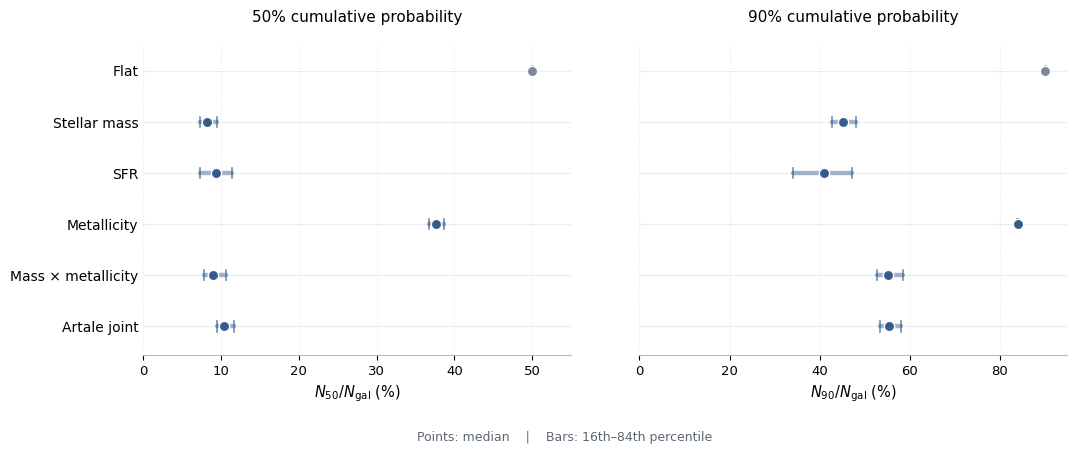

PASS: Revised fractional-concentration figure saved.


In [191]:

# ============================================================
# CELL 63
# Publication-style fractional probability concentration
# Cleaner two-panel design
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reuse the validated results from Cell 62.
plot_data = ensemble_concentration.copy()

plot_data["f50_pct"] = (
    100 * plot_data["N50"] / plot_data["N_galaxies"]
)
plot_data["f90_pct"] = (
    100 * plot_data["N90"] / plot_data["N_galaxies"]
)

prior_order = [
    "Flat",
    "Stellar mass",
    "SFR",
    "Metallicity",
    "Mass × metallicity",
    "Artale joint"
]

summary_rows = []

for prior in prior_order:
    subset = plot_data[plot_data["Prior"] == prior]

    row = {"Prior": prior}

    for metric in ["f50_pct", "f90_pct"]:
        values = subset[metric].to_numpy(float)

        row[f"{metric}_median"] = np.median(values)
        row[f"{metric}_p16"] = np.percentile(values, 16)
        row[f"{metric}_p84"] = np.percentile(values, 84)

    summary_rows.append(row)

fractional_summary = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# Figure design
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(11.7, 4.8),
    sharey=True
)

y = np.arange(len(prior_order))

# Flat control is grey; all astrophysical models are blue.
flat_color = "#7D8996"
model_color = "#355C8A"

panels = [
    ("f50_pct", 0, 55, 10,
     r"$N_{50}/N_{\rm gal}$ (%)",
     "50% cumulative probability"),
    ("f90_pct", 0, 95, 20,
     r"$N_{90}/N_{\rm gal}$ (%)",
     "90% cumulative probability")
]

for ax, (metric, xmin, xmax, tick_step, xlabel, heading) in zip(
    axes, panels
):

    # Light horizontal guides to help compare models.
    for yi in y:
        ax.axhline(
            yi,
            color="#E9EDF1",
            linewidth=0.8,
            zorder=0
        )

    for i, prior in enumerate(prior_order):

        record = fractional_summary[
            fractional_summary["Prior"] == prior
        ].iloc[0]

        median = record[f"{metric}_median"]
        low = record[f"{metric}_p16"]
        high = record[f"{metric}_p84"]

        color = (
            flat_color if prior == "Flat"
            else model_color
        )

        # Percentile range, with visible endpoints.
        ax.plot(
            [low, high],
            [i, i],
            color=color,
            linewidth=3.2,
            alpha=0.45,
            solid_capstyle="round",
            zorder=2
        )

        ax.plot(
            [low, low], [i-0.10, i+0.10],
            color=color, linewidth=1.2,
            alpha=0.7, zorder=2
        )
        ax.plot(
            [high, high], [i-0.10, i+0.10],
            color=color, linewidth=1.2,
            alpha=0.7, zorder=2
        )

        # Median point.
        ax.scatter(
            median, i,
            s=55,
            facecolor=color,
            edgecolor="white",
            linewidth=1,
            zorder=4
        )

    ax.set_xlim(xmin, xmax)
    ax.set_xticks(np.arange(xmin, xmax + 1, tick_step))
    ax.set_xlabel(xlabel, fontsize=10.5)
    ax.set_title(heading, fontsize=11, pad=15)

    ax.grid(
        axis="x",
        color="#E7EBF0",
        linestyle=":",
        linewidth=0.8
    )

    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", labelsize=9.5)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_color("#B5BDC6")

    ax.set_yticks(y)
    ax.set_yticklabels(prior_order, fontsize=10)

    ax.set_ylim(5.55, -0.55)

# Explanatory notation below the panels.
fig.text(
    0.55, 0.04,
    "Points: median    |    Bars: 16th–84th percentile",
    ha="center",
    fontsize=9,
    color="#5D6773"
)

fig.subplots_adjust(
    left=0.19,
    right=0.98,
    top=0.87,
    bottom=0.22,
    wspace=0.16
)

fig.savefig(
    DATA / "EAGLE_500cube_fractional_concentration_clean.pdf",
    bbox_inches="tight"
)

fig.savefig(
    DATA / "EAGLE_500cube_fractional_concentration_clean.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PASS: Revised fractional-concentration figure saved.")


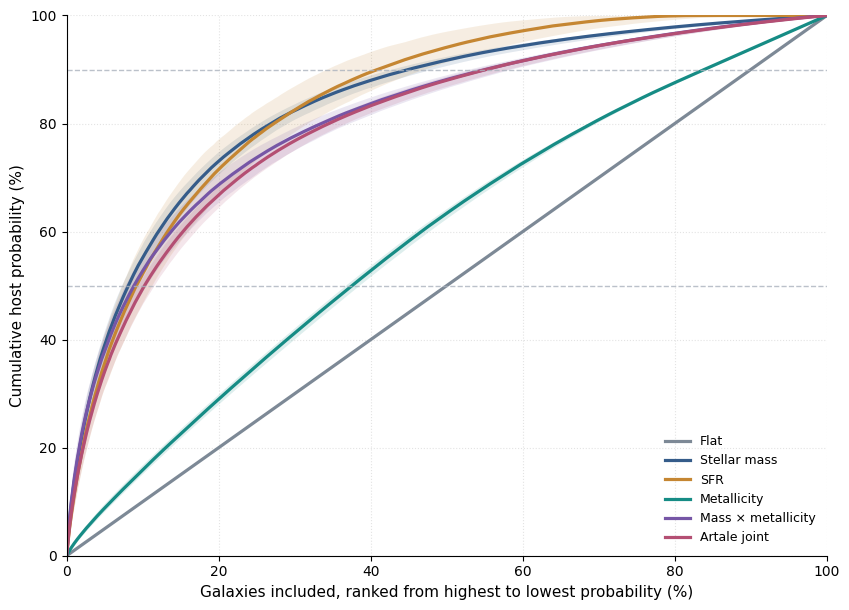

PASS: Ranked cumulative probability curves generated and saved.


In [192]:
# ============================================================
# CELL 64
# Ranked cumulative probability curves across 500 mock volumes
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

prior_order = [
    "Flat",
    "Stellar mass",
    "SFR",
    "Metallicity",
    "Mass × metallicity",
    "Artale joint"
]

prior_columns = {
    "Flat": "P_flat",
    "Stellar mass": "P_mass",
    "SFR": "P_SFR",
    "Metallicity": "P_Z",
    "Mass × metallicity": "P_MZ",
    "Artale joint": "P_Artale"
}

prior_colors = {
    "Flat": "#7D8996",
    "Stellar mass": "#355C8A",
    "SFR": "#C58632",
    "Metallicity": "#168C85",
    "Mass × metallicity": "#7656A6",
    "Artale joint": "#B44F73"
}

# Common x-grid: fraction of galaxies included
x_grid = np.linspace(0, 1, 500)

curve_store = {prior: [] for prior in prior_order}

for cube_id, cube in ensemble_probabilities.items():
    for prior in prior_order:
        p = cube[prior_columns[prior]].to_numpy(dtype=float)

        # Rank from highest to lowest probability
        ranked = np.sort(p)[::-1]
        cumulative = np.cumsum(ranked)

        # Fraction of galaxies included
        x = np.arange(1, len(ranked) + 1) / len(ranked)

        # Include origin explicitly
        x_full = np.concatenate(([0.0], x))
        y_full = np.concatenate(([0.0], cumulative))

        # Interpolate cumulative probability onto common grid
        y_interp = np.interp(x_grid, x_full, y_full)

        curve_store[prior].append(y_interp)

# Summarise curves
curve_summary = {}

for prior in prior_order:
    arr = np.vstack(curve_store[prior])

    curve_summary[prior] = {
        "median": np.median(arr, axis=0),
        "p16": np.percentile(arr, 16, axis=0),
        "p84": np.percentile(arr, 84, axis=0)
    }

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8.6, 6.2))

for prior in prior_order:
    summary = curve_summary[prior]
    color = prior_colors[prior]

    ax.fill_between(
        100 * x_grid,
        100 * summary["p16"],
        100 * summary["p84"],
        color=color,
        alpha=0.14,
        linewidth=0
    )

    ax.plot(
        100 * x_grid,
        100 * summary["median"],
        color=color,
        linewidth=2.3,
        label=prior
    )

# Reference lines for 50% and 90% cumulative probability
for y in [50, 90]:
    ax.axhline(
        y,
        color="#AAB2BD",
        linestyle="--",
        linewidth=1.0,
        alpha=0.8
    )

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)

ax.set_xlabel("Galaxies included, ranked from highest to lowest probability (%)", fontsize=11)
ax.set_ylabel("Cumulative host probability (%)", fontsize=11)

ax.grid(True, linestyle=":", linewidth=0.8, alpha=0.35)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

ax.legend(
    loc="lower right",
    frameon=False,
    fontsize=9
)

fig.tight_layout()

fig.savefig(
    DATA / "EAGLE_500cube_ranked_cumulative_probability_curves.pdf",
    bbox_inches="tight"
)
fig.savefig(
    DATA / "EAGLE_500cube_ranked_cumulative_probability_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PASS: Ranked cumulative probability curves generated and saved.")

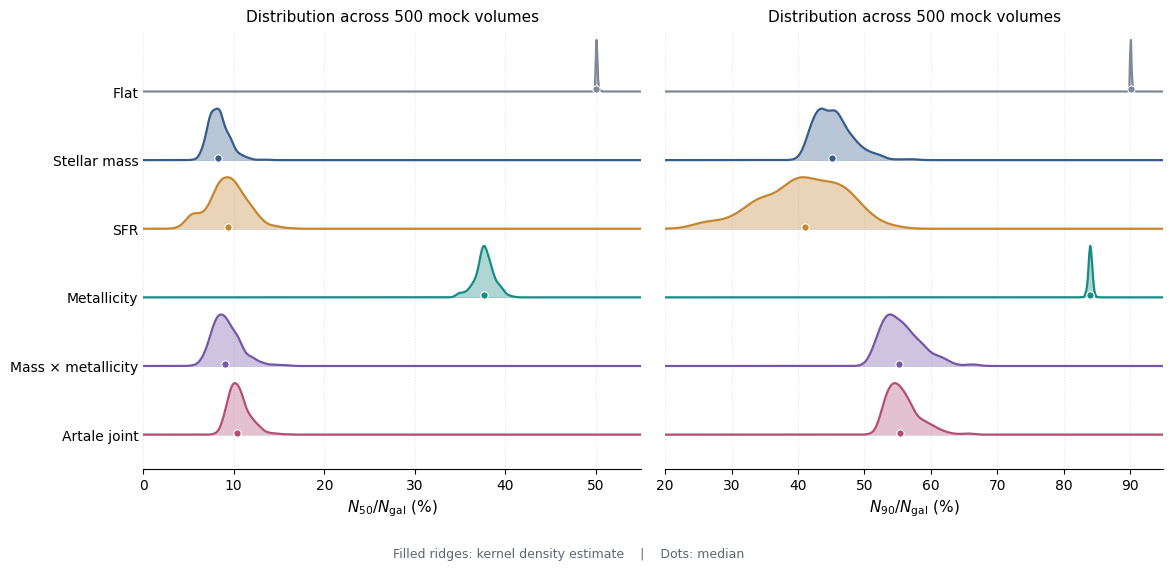

PASS: Ridgeline plot generated and saved.


In [193]:
# ============================================================
# CELL 65
# Ridgeline distributions for fractional N50 and N90
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

ridge_data = ensemble_concentration.copy()

ridge_data["f50_pct"] = (
    100 * ridge_data["N50"] / ridge_data["N_galaxies"]
)

ridge_data["f90_pct"] = (
    100 * ridge_data["N90"] / ridge_data["N_galaxies"]
)

prior_order = [
    "Flat",
    "Stellar mass",
    "SFR",
    "Metallicity",
    "Mass × metallicity",
    "Artale joint"
]

prior_colors = {
    "Flat": "#7D8996",
    "Stellar mass": "#355C8A",
    "SFR": "#C58632",
    "Metallicity": "#168C85",
    "Mass × metallicity": "#7656A6",
    "Artale joint": "#B44F73"
}

def draw_ridgeline_panel(ax, dataframe, metric, xlim, xlabel):
    y_positions = np.arange(len(prior_order))[::-1]

    x_grid = np.linspace(xlim[0], xlim[1], 600)

    for y, prior in zip(y_positions, prior_order):
        values = dataframe.loc[
            dataframe["Prior"] == prior, metric
        ].to_numpy(dtype=float)

        kde = gaussian_kde(values)
        density = kde(x_grid)

        # Normalise each ridge to a common height
        density = density / density.max() * 0.75

        color = prior_colors[prior]

        ax.fill_between(
            x_grid,
            y,
            y + density,
            color=color,
            alpha=0.35,
            linewidth=0
        )

        ax.plot(
            x_grid,
            y + density,
            color=color,
            linewidth=1.6
        )

        # Median marker
        median = np.median(values)
        ax.scatter(
            median,
            y + 0.03,
            s=28,
            color=color,
            edgecolor="white",
            linewidth=0.8,
            zorder=5
        )

        # Baseline
        ax.hlines(
            y,
            xlim[0],
            xlim[1],
            color="#D9DEE5",
            linewidth=0.7,
            zorder=0
        )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(prior_order, fontsize=10)
    ax.set_xlim(*xlim)
    ax.set_xlabel(xlabel, fontsize=11)

    ax.grid(axis="x", linestyle=":", linewidth=0.8, alpha=0.3)
    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.5, len(prior_order) - 0.1)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.2, 5.8),
    sharey=True
)

draw_ridgeline_panel(
    axes[0],
    ridge_data,
    "f50_pct",
    xlim=(0, 55),
    xlabel=r"$N_{50}/N_{\rm gal}$ (%)"
)
axes[0].set_title("Distribution across 500 mock volumes", fontsize=11)

draw_ridgeline_panel(
    axes[1],
    ridge_data,
    "f90_pct",
    xlim=(20, 95),
    xlabel=r"$N_{90}/N_{\rm gal}$ (%)"
)
axes[1].set_title("Distribution across 500 mock volumes", fontsize=11)

fig.text(
    0.5, 0.03,
    "Filled ridges: kernel density estimate    |    Dots: median",
    ha="center",
    fontsize=9,
    color="#5D6773"
)

fig.tight_layout(rect=[0.03, 0.07, 1, 1])

fig.savefig(
    DATA / "EAGLE_500cube_ridgeline_fractional_concentration.pdf",
    bbox_inches="tight"
)
fig.savefig(
    DATA / "EAGLE_500cube_ridgeline_fractional_concentration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PASS: Ridgeline plot generated and saved.")

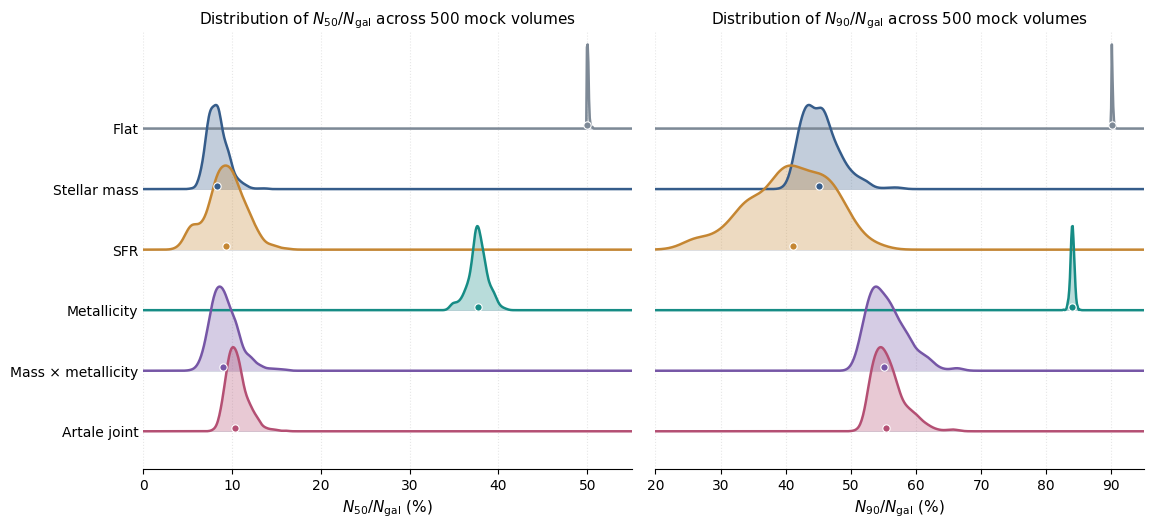

PASS: Overlapping joyplot ridgelines saved.


In [194]:
# ============================================================
# CELL 66
# Overlapping joyplot-style ridgelines for fractional N50/N90
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

ridge_data = ensemble_concentration.copy()

ridge_data["f50_pct"] = (
    100 * ridge_data["N50"] / ridge_data["N_galaxies"]
)
ridge_data["f90_pct"] = (
    100 * ridge_data["N90"] / ridge_data["N_galaxies"]
)

prior_order = [
    "Flat",
    "Stellar mass",
    "SFR",
    "Metallicity",
    "Mass × metallicity",
    "Artale joint"
]

prior_colors = {
    "Flat": "#7D8996",
    "Stellar mass": "#355C8A",
    "SFR": "#C58632",
    "Metallicity": "#168C85",
    "Mass × metallicity": "#7656A6",
    "Artale joint": "#B44F73"
}

def draw_overlap_ridges(ax, dataframe, metric, xlim, xlabel):
    # smaller spacing -> more overlap
    spacing = 0.72
    height = 1.00
    y_positions = np.arange(len(prior_order))[::-1] * spacing

    x_grid = np.linspace(xlim[0], xlim[1], 700)

    for y, prior in zip(y_positions, prior_order):
        values = dataframe.loc[
            dataframe["Prior"] == prior, metric
        ].to_numpy(dtype=float)

        kde = gaussian_kde(values)
        density = kde(x_grid)

        density = density / density.max() * height
        color = prior_colors[prior]

        # filled ridge
        ax.fill_between(
            x_grid, y, y + density,
            color=color,
            alpha=0.30,
            linewidth=0,
            zorder=2
        )

        # ridge outline
        ax.plot(
            x_grid, y + density,
            color=color,
            linewidth=1.8,
            zorder=3
        )

        # baseline
        ax.hlines(
            y, xlim[0], xlim[1],
            color="#D9DEE5",
            linewidth=0.6,
            zorder=1
        )

        # median marker
        median = np.median(values)
        ax.scatter(
            median, y + 0.04,
            s=28,
            color=color,
            edgecolor="white",
            linewidth=0.8,
            zorder=4
        )

    ax.set_xlim(*xlim)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_yticks(y_positions)
    ax.set_yticklabels(prior_order, fontsize=10)
    ax.tick_params(axis="y", length=0)

    ax.grid(axis="x", linestyle=":", linewidth=0.8, alpha=0.3)
    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.set_ylim(-0.45, y_positions[0] + 1.15)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.0, 5.8),
    sharey=True
)

draw_overlap_ridges(
    axes[0],
    ridge_data,
    "f50_pct",
    xlim=(0, 55),
    xlabel=r"$N_{50}/N_{\rm gal}$ (%)"
)
axes[0].set_title(r"Distribution of $N_{50}/N_{\rm gal}$ across 500 mock volumes", fontsize=11)

draw_overlap_ridges(
    axes[1],
    ridge_data,
    "f90_pct",
    xlim=(20, 95),
    xlabel=r"$N_{90}/N_{\rm gal}$ (%)"
)
axes[1].set_title(r"Distribution of $N_{90}/N_{\rm gal}$ across 500 mock volumes", fontsize=11)


fig.tight_layout(rect=[0.03, 0.07, 1, 1])

fig.savefig(
    DATA / "EAGLE_500cube_overlapping_ridgelines.pdf",
    bbox_inches="tight"
)
fig.savefig(
    DATA / "EAGLE_500cube_overlapping_ridgelines.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PASS: Overlapping joyplot ridgelines saved.")

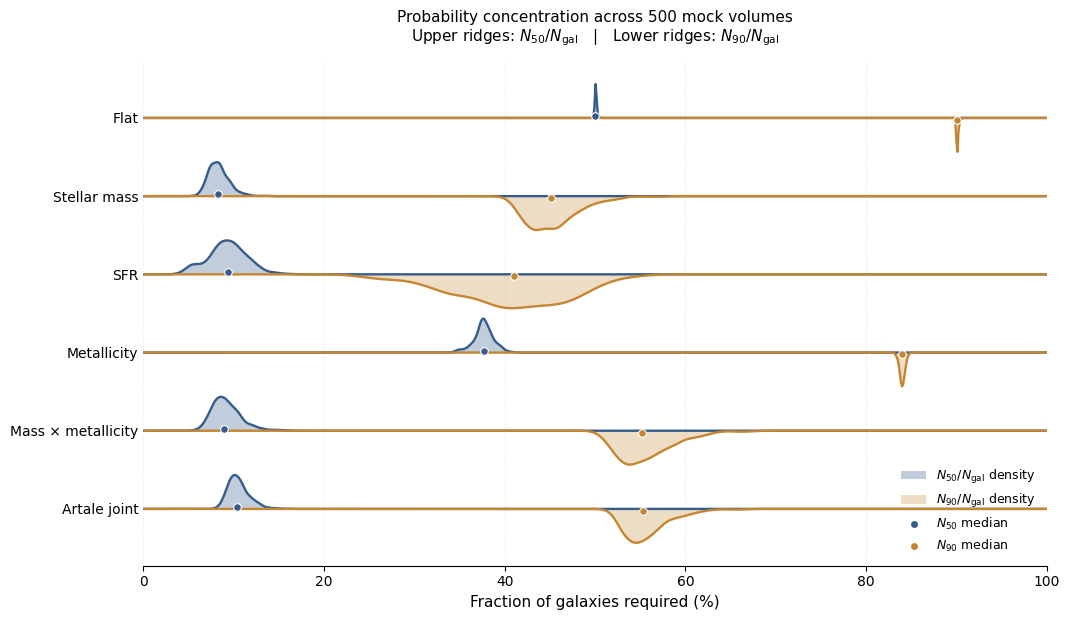

PASS: Combined mirrored ridgeline saved.


In [195]:
# ============================================================
# CELL 67
# Combined mirrored ridgeline: N50 above, N90 below
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

combo_data = ensemble_concentration.copy()

combo_data["f50_pct"] = (
    100 * combo_data["N50"] / combo_data["N_galaxies"]
)
combo_data["f90_pct"] = (
    100 * combo_data["N90"] / combo_data["N_galaxies"]
)

prior_order = [
    "Flat",
    "Stellar mass",
    "SFR",
    "Metallicity",
    "Mass × metallicity",
    "Artale joint"
]

# one colour per metric, not per prior
color_50 = "#355C8A"
color_90 = "#C58632"

spacing = 1.2
height = 0.52
y_positions = np.arange(len(prior_order))[::-1] * spacing

x_grid = np.linspace(0, 100, 800)

fig, ax = plt.subplots(figsize=(10.8, 6.3))

for y, prior in zip(y_positions, prior_order):

    vals50 = combo_data.loc[
        combo_data["Prior"] == prior, "f50_pct"
    ].to_numpy(dtype=float)

    vals90 = combo_data.loc[
        combo_data["Prior"] == prior, "f90_pct"
    ].to_numpy(dtype=float)

    kde50 = gaussian_kde(vals50)
    kde90 = gaussian_kde(vals90)

    d50 = kde50(x_grid)
    d90 = kde90(x_grid)

    d50 = d50 / d50.max() * height
    d90 = d90 / d90.max() * height

    # baseline
    ax.hlines(
        y, 0, 100,
        color="#D9DEE5",
        linewidth=0.75,
        zorder=1
    )

    # N50 ridge above baseline
    ax.fill_between(
        x_grid, y, y + d50,
        color=color_50,
        alpha=0.30,
        linewidth=0,
        zorder=2
    )
    ax.plot(
        x_grid, y + d50,
        color=color_50,
        linewidth=1.7,
        zorder=3
    )

    # N90 ridge below baseline
    ax.fill_between(
        x_grid, y, y - d90,
        color=color_90,
        alpha=0.28,
        linewidth=0,
        zorder=2
    )
    ax.plot(
        x_grid, y - d90,
        color=color_90,
        linewidth=1.7,
        zorder=3
    )

    # median markers
    med50 = np.median(vals50)
    med90 = np.median(vals90)

    ax.scatter(
        med50, y + 0.03,
        s=30,
        color=color_50,
        edgecolor="white",
        linewidth=0.8,
        zorder=4
    )
    ax.scatter(
        med90, y - 0.03,
        s=30,
        color=color_90,
        edgecolor="white",
        linewidth=0.8,
        zorder=4
    )

ax.set_xlim(0, 100)
ax.set_xlabel("Fraction of galaxies required (%)", fontsize=11)
ax.set_yticks(y_positions)
ax.set_yticklabels(prior_order, fontsize=10)
ax.tick_params(axis="y", length=0)

ax.grid(axis="x", linestyle=":", linewidth=0.8, alpha=0.3)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.set_title(
    r"Probability concentration across 500 mock volumes"
    "\n"
    r"Upper ridges: $N_{50}/N_{\rm gal}$   |   Lower ridges: $N_{90}/N_{\rm gal}$",
    fontsize=11,
    pad=14
)

legend_handles = [
    Patch(facecolor=color_50, edgecolor="none", alpha=0.30,
          label=r"$N_{50}/N_{\rm gal}$ density"),
    Patch(facecolor=color_90, edgecolor="none", alpha=0.28,
          label=r"$N_{90}/N_{\rm gal}$ density"),
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor=color_50, markeredgecolor="white",
           markersize=6, label=r"$N_{50}$ median"),
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor=color_90, markeredgecolor="white",
           markersize=6, label=r"$N_{90}$ median"),
]

ax.legend(
    handles=legend_handles,
    frameon=False,
    fontsize=9,
    loc="lower right"
)

fig.tight_layout()

fig.savefig(
    DATA / "EAGLE_500cube_combined_mirrored_ridgeline.pdf",
    bbox_inches="tight"
)
fig.savefig(
    DATA / "EAGLE_500cube_combined_mirrored_ridgeline.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PASS: Combined mirrored ridgeline saved.")

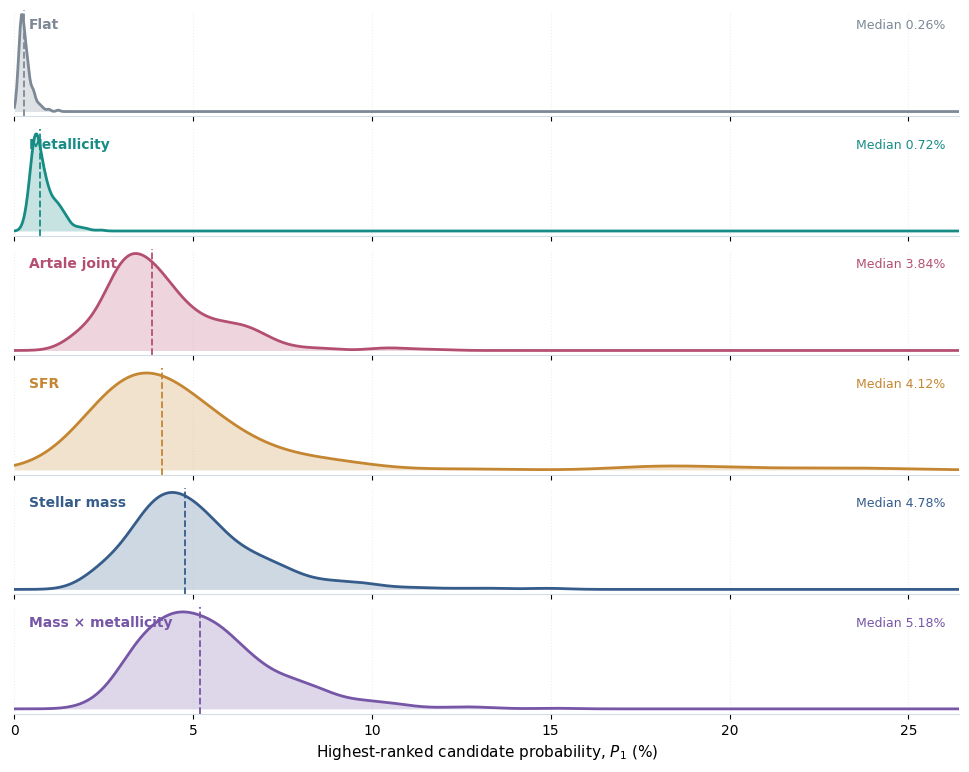

PASS: P1 density small multiples saved.


In [196]:

# ============================================================
# CELL 69
# P1 probability distributions — density small multiples
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

prior_order = [
    "Flat",
    "Metallicity",
    "Artale joint",
    "SFR",
    "Stellar mass",
    "Mass × metallicity"
]

colors = {
    "Flat": "#7D8996",
    "Metallicity": "#168C85",
    "Artale joint": "#B44F73",
    "SFR": "#C58632",
    "Stellar mass": "#355C8A",
    "Mass × metallicity": "#7656A6"
}

data = {
    name: ensemble_concentration.loc[
        ensemble_concentration["Prior"] == name,
        "P1_pct"
    ].to_numpy(dtype=float)
    for name in prior_order
}

assert all(len(v) == 500 for v in data.values())

# Shared horizontal scale captures the full observed range.
x_max = max(v.max() for v in data.values()) * 1.05
x = np.linspace(0, x_max, 800)

fig, axes = plt.subplots(
    len(prior_order), 1,
    figsize=(10.5, 8),
    sharex=True
)

for ax, name in zip(axes, prior_order):

    values = data[name]
    color = colors[name]

    kde = gaussian_kde(values, bw_method="scott")
    density = kde(x)

    ax.fill_between(
        x, density,
        color=color,
        alpha=0.24,
        linewidth=0
    )

    ax.plot(
        x, density,
        color=color,
        linewidth=2
    )

    median = np.median(values)

    # Vertical median reference line.
    ax.axvline(
        median,
        color=color,
        linewidth=1.3,
        linestyle="--"
    )

    ax.text(
        0.015, 0.82,
        name,
        transform=ax.transAxes,
        fontsize=10,
        weight="bold",
        color=color
    )

    ax.text(
        0.985, 0.82,
        f"Median {median:.2f}%",
        transform=ax.transAxes,
        ha="right",
        fontsize=9,
        color=color
    )

    ax.set_yticks([])
    ax.set_xlim(0, x_max)

    ax.grid(
        axis="x",
        linestyle=":",
        alpha=0.2
    )

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_color("#D4DCE3")

axes[-1].set_xlabel(
    r"Highest-ranked candidate probability, $P_1$ (%)",
    fontsize=11
)

fig.subplots_adjust(
    hspace=0.12,
    left=0.08,
    right=0.98,
    top=0.97,
    bottom=0.09
)

fig.savefig(
    DATA / "EAGLE_500cube_P1_density_small_multiples.pdf",
    bbox_inches="tight"
)

fig.savefig(
    DATA / "EAGLE_500cube_P1_density_small_multiples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PASS: P1 density small multiples saved.")


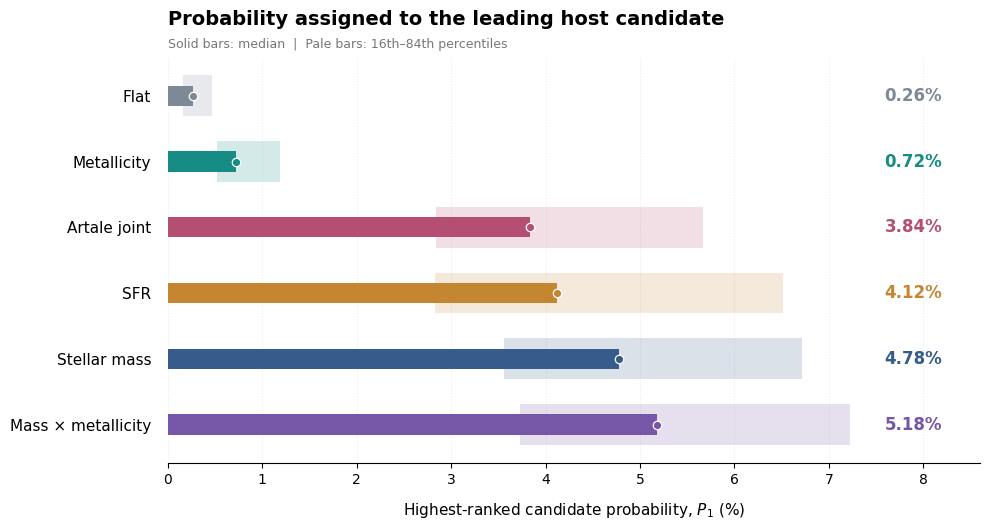

In [197]:

# ============================================================
# CELL 70 — P1 median probability bars
# Median and 16th–84th percentiles across 500 mock cubes
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

prior_order = [
    "Flat",
    "Metallicity",
    "Artale joint",
    "SFR",
    "Stellar mass",
    "Mass × metallicity"
]

colors = {
    "Flat": "#7D8996",
    "Metallicity": "#168C85",
    "Artale joint": "#B44F73",
    "SFR": "#C58632",
    "Stellar mass": "#355C8A",
    "Mass × metallicity": "#7656A6"
}

fig, ax = plt.subplots(figsize=(10, 5.4))

for i, prior in enumerate(prior_order):
    values = ensemble_concentration.loc[
        ensemble_concentration["Prior"] == prior,
        "P1_pct"
    ].to_numpy(dtype=float)

    assert len(values) == 500, (
        f"Expected 500 cubes for {prior}, got {len(values)}"
    )

    p16, med, p84 = np.percentile(
        values, [16, 50, 84]
    )

    color = colors[prior]

    # Light range: central 68% of cubes.
    ax.barh(
        i, p84 - p16,
        left=p16,
        height=0.62,
        color=color,
        alpha=0.18,
        edgecolor="none",
        zorder=2
    )

    # Strong solid bar: median P1.
    ax.barh(
        i, med,
        height=0.31,
        color=color,
        edgecolor="none",
        zorder=3
    )

    # Median endpoint.
    ax.scatter(
        med, i,
        s=37,
        color=color,
        edgecolor="white",
        linewidth=0.9,
        zorder=4
    )

    # Median annotation at right of each bar.
    ax.text(
        8.2, i,
        f"{med:.2f}%",
        ha="right",
        va="center",
        fontsize=12,
        weight="bold",
        color=color
    )

ax.set_yticks(np.arange(len(prior_order)))
ax.set_yticklabels(prior_order, fontsize=11)
ax.invert_yaxis()

ax.set_xlim(0, 8.6)
ax.set_xticks(np.arange(0, 9, 1))

ax.set_xlabel(
    r"Highest-ranked candidate probability, $P_1$ (%)",
    fontsize=11,
    labelpad=10
)

ax.grid(
    axis="x",
    linestyle=":",
    linewidth=0.75,
    alpha=0.25
)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0, pad=12)
ax.tick_params(axis="x", labelsize=10)

ax.set_title(
    "Probability assigned to the leading host candidate",
    fontsize=14,
    weight="bold",
    loc="left",
    pad=23
)

ax.text(
    0, 1.015,
    "Solid bars: median  |  Pale bars: 16th–84th percentiles",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=9,
    color="#777777"
)

fig.tight_layout()

fig.savefig(
    DATA / "EAGLE_500cube_P1_probability_bars.pdf",
    bbox_inches="tight"
)
fig.savefig(
    DATA / "EAGLE_500cube_P1_probability_bars.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


/tmp/ipykernel_1534/2812587487.py:51: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


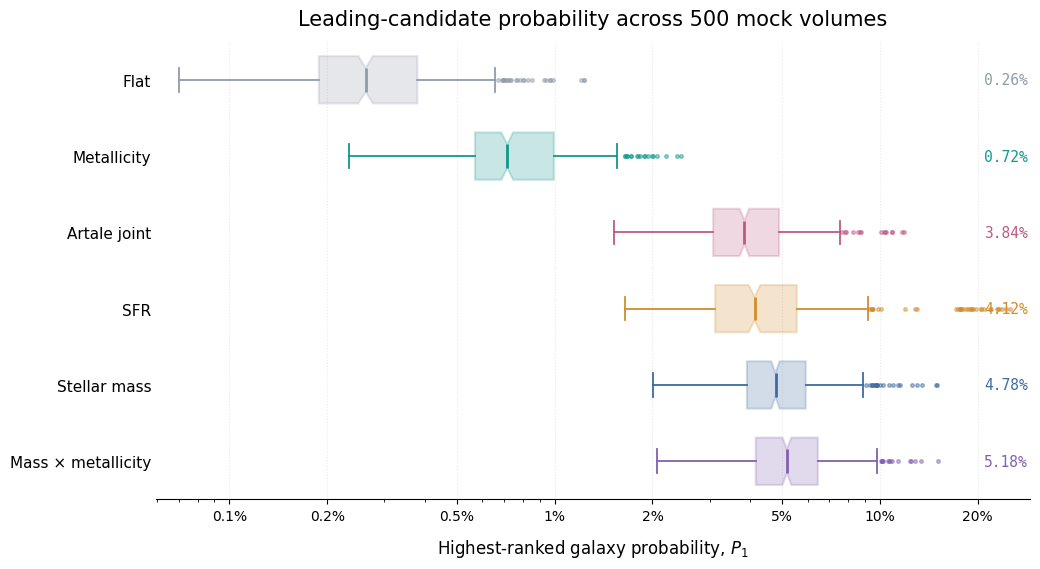

PASS: P1 box-and-whisker figure generated.


In [198]:
# ============================================================
# CELL 77 — P1 BOX-AND-WHISKER PLOT
# Horizontal boxplots on a logarithmic x-axis
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter

prior_order = [
    "Flat",
    "Metallicity",
    "Artale joint",
    "SFR",
    "Stellar mass",
    "Mass × metallicity"
]

colors = {
    "Flat": "#909BAA",
    "Metallicity": "#12978D",
    "Artale joint": "#BC5A82",
    "SFR": "#D18C2B",
    "Stellar mass": "#3E6BA2",
    "Mass × metallicity": "#8060B0"
}

# Collect data
data = []
medians = []

for prior in prior_order:
    values = ensemble_concentration.loc[
        ensemble_concentration["Prior"] == prior,
        "P1_pct"
    ].to_numpy(float)

    assert len(values) == 500, f"{prior}: expected 500 values"
    assert np.all(np.isfinite(values) & (values > 0)), f"{prior}: invalid P1 values"

    data.append(values)
    medians.append(np.median(values))

# Reverse so Flat appears at the top
plot_order = prior_order[::-1]
plot_data = data[::-1]
plot_medians = medians[::-1]

fig, ax = plt.subplots(figsize=(10.5, 5.8))

bp = ax.boxplot(
    plot_data,
    vert=False,
    patch_artist=True,
    labels=plot_order,
    widths=0.62,
    whis=1.5,
    showfliers=True,
    notch=True
)

# Style boxes
for patch, prior in zip(bp["boxes"], plot_order):
    patch.set_facecolor(colors[prior])
    patch.set_alpha(0.23)
    patch.set_edgecolor(colors[prior])
    patch.set_linewidth(1.5)

for whisker, prior in zip(bp["whiskers"], np.repeat(plot_order, 2)):
    whisker.set_color(colors[prior])
    whisker.set_linewidth(1.3)

for cap, prior in zip(bp["caps"], np.repeat(plot_order, 2)):
    cap.set_color(colors[prior])
    cap.set_linewidth(1.3)

for median_line, prior in zip(bp["medians"], plot_order):
    median_line.set_color(colors[prior])
    median_line.set_linewidth(2.0)

for flier, prior in zip(bp["fliers"], plot_order):
    flier.set_marker("o")
    flier.set_markersize(2.6)
    flier.set_markerfacecolor(colors[prior])
    flier.set_markeredgecolor(colors[prior])
    flier.set_alpha(0.45)

# Log axis
ax.set_xscale("log")

# Ticks
ticks = [0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50]
xmin = min(v.min() for v in plot_data) * 0.85
xmax = max(v.max() for v in plot_data) * 1.15
ticks = [t for t in ticks if xmin <= t <= xmax]

ax.set_xlim(xmin, xmax)
ax.set_xticks(ticks)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{v:g}%"))
ax.xaxis.set_minor_formatter(NullFormatter())

# Median labels on right
for y, med, prior in zip(range(1, len(plot_order) + 1), plot_medians, plot_order):
    ax.text(
        xmax * 0.985,
        y,
        f"{med:.2f}%",
        ha="right",
        va="center",
        fontsize=10.5,
        color=colors[prior],
        fontfamily="monospace"
    )

# Aesthetics
ax.set_xlabel(r"Highest-ranked galaxy probability, $P_1$", fontsize=12, labelpad=10)
ax.set_title(r"Leading-candidate probability across 500 mock volumes", fontsize=15, pad=12)

ax.grid(axis="x", which="major", linestyle=":", linewidth=0.8, alpha=0.28)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0, labelsize=11)
ax.tick_params(axis="x", labelsize=10)

fig.tight_layout()

fig.savefig(
    DATA / "EAGLE_P1_boxplot.pdf",
    bbox_inches="tight"
)
fig.savefig(
    DATA / "EAGLE_P1_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PASS: P1 box-and-whisker figure generated.")

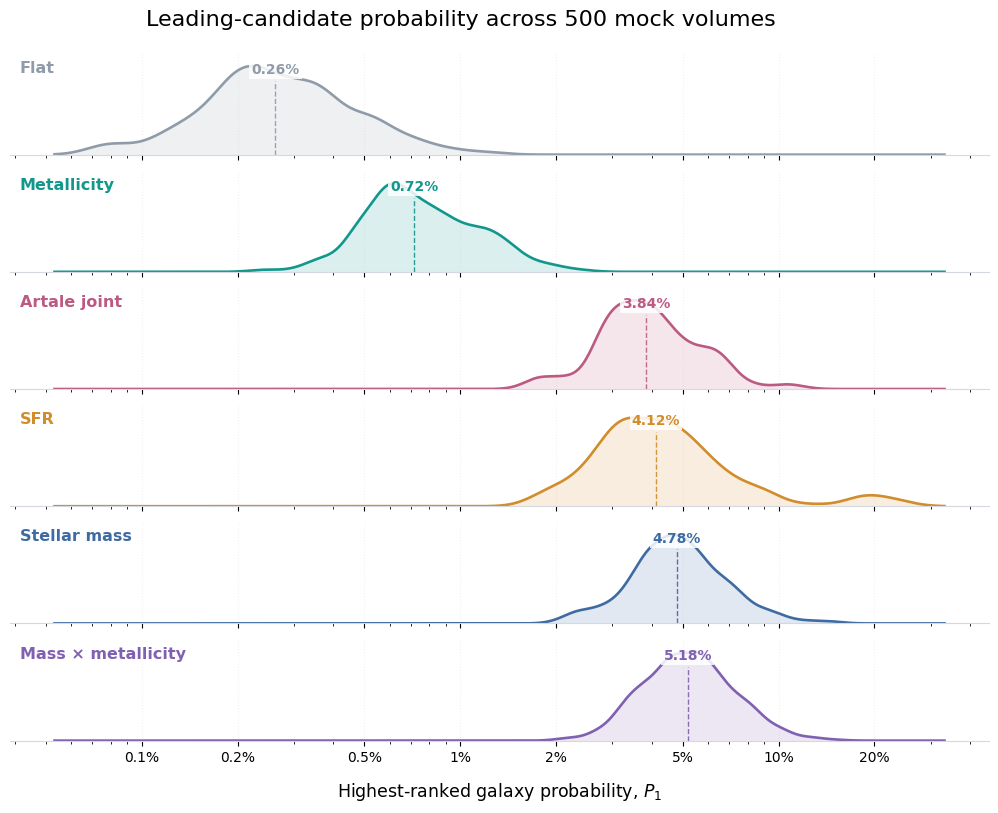

PASS: Final P1 posterior-style figure generated.


In [199]:
# ============================================================
# FINAL P1 FIGURE — CLEANED POSTERIOR-STYLE DISTRIBUTIONS
# Log-space KDE, upright densities, cleaner panel layout
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from matplotlib.ticker import FuncFormatter, NullFormatter

priors = [
    "Flat",
    "Metallicity",
    "Artale joint",
    "SFR",
    "Stellar mass",
    "Mass × metallicity"
]

colors = [
    "#909BAA",  # Flat
    "#12978D",  # Metallicity
    "#BC5A82",  # Artale joint
    "#D18C2B",  # SFR
    "#3E6BA2",  # Stellar mass
    "#8060B0"   # Mass × metallicity
]

samples = []
for prior in priors:
    v = ensemble_concentration.loc[
        ensemble_concentration["Prior"] == prior,
        "P1_pct"
    ].to_numpy(float)

    assert len(v) == 500, f"{prior}: expected 500 values"
    assert np.all(np.isfinite(v) & (v > 0)), f"{prior}: invalid P1 values"

    samples.append(v)

# Shared plotting range in log10 space
pooled = np.concatenate(samples)
xlo = np.log10(pooled.min()) - 0.12
xhi = np.log10(pooled.max()) + 0.12

log_x = np.linspace(xlo, xhi, 1000)
x = 10**log_x

fig, axes = plt.subplots(
    6, 1,
    figsize=(11, 8.4),
    sharex=True,
    gridspec_kw={"hspace": 0.14}
)

for ax, prior, color, values in zip(axes, priors, colors, samples):

    kde = gaussian_kde(np.log10(values), bw_method=0.25)
    density = kde(log_x)

    # Normalise each curve to the same peak height for visual comparison
    density = density / density.max()

    med = np.median(values)

    # Filled density
    ax.fill_between(
        x, density, 0,
        color=color,
        alpha=0.15,
        linewidth=0
    )

    # Outline
    ax.plot(
        x, density,
        color=color,
        lw=1.9
    )

    # Median line
    ax.axvline(
      med,
      ymin=0,
      ymax=0.72,
      color=color,
      ls="--",
      lw=1.0,
      alpha=0.90
    )

    # Median value directly above the dashed line
    ax.text(
      med, 0.88,
      f"{med:.2f}%",
      ha="center",
      va="bottom",
      fontsize=10,
      fontweight="semibold",
      color=color,
      bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.85,
        pad=1.5
      ),
      zorder=10
  )

    # Prior label only
    ax.text(
        0.01, 0.80,
        prior,
        transform=ax.transAxes,
        fontsize=11.5,
        weight="semibold",
        color=color
    )

    ax.set_ylim(0, 1.16)
    ax.set_yticks([])
    ax.set_xscale("log")

    ax.grid(
        axis="x",
        linestyle=":",
        alpha=0.16
    )

    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)

    ax.spines["bottom"].set_color("#D4D8E1")
    ax.tick_params(axis="y", length=0)

# Shared x-axis formatting
ticks = [0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50]
ticks = [t for t in ticks if 10**xlo <= t <= 10**xhi]

axes[-1].set_xticks(ticks)
axes[-1].xaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{v:g}%"))
axes[-1].xaxis.set_minor_formatter(NullFormatter())

for ax in axes[:-1]:
    ax.tick_params(axis="x", labelbottom=False)

axes[-1].set_xlabel(
    r"Highest-ranked galaxy probability, $P_1$",
    fontsize=12.5,
    labelpad=12
)

fig.suptitle(
    r"Leading-candidate probability across 500 mock volumes",
    fontsize=16,
    y=0.98
)

fig.subplots_adjust(
    left=0.09,
    right=0.98,
    top=0.93,
    bottom=0.11
)

fig.savefig(
    DATA / "EAGLE_P1_final_posterior_style.pdf",
    bbox_inches="tight"
)
fig.savefig(
    DATA / "EAGLE_P1_final_posterior_style.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PASS: Final P1 posterior-style figure generated.")

In [200]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Median values and 16th–84th percentile ranges from Section 6.5
summary = pd.DataFrame({
    "Prior": [
        "Flat",
        "Stellar mass",
        "SFR",
        "Metallicity",
        "Mass × metallicity",
        "Artale joint"
    ],

    "P1_med":  [0.26, 4.78, 4.12, 0.72, 5.18, 3.84],
    "P1_p16":  [0.16, 3.56, 2.83, 0.52, 3.73, 2.84],
    "P1_p84":  [0.46, 6.71, 6.52, 1.18, 7.22, 5.66],

    "C5_med":  [1.31, 16.60, 14.22, 2.84, 17.27, 13.77],
    "C5_p16":  [0.80, 12.94, 10.65, 2.12, 13.81, 10.71],
    "C5_p84":  [2.32, 22.60, 21.48, 4.41, 22.08, 19.74],

    "C10_med": [2.63, 26.28, 23.56, 5.09, 26.70, 22.57],
    "C10_p16": [1.61, 20.88, 18.15, 3.79, 21.32, 17.42],
    "C10_p84": [4.64, 35.53, 33.21, 7.95, 33.36, 30.96]
})

# Incremental contributions for the stacked version
summary["Top1"] = summary["P1_med"]
summary["Ranks2to5"] = summary["C5_med"] - summary["P1_med"]
summary["Ranks6to10"] = summary["C10_med"] - summary["C5_med"]

# Reverse order so first row plots at the top
summary_plot = summary.iloc[::-1].reset_index(drop=True)

display(summary_plot[[
    "Prior", "P1_med", "C5_med", "C10_med",
    "Top1", "Ranks2to5", "Ranks6to10"
]])

,Prior,P1_med,C5_med,C10_med,Top1,Ranks2to5,Ranks6to10
0,Artale joint,3.84,13.77,22.57,3.84,9.93,8.80
1,Mass × metallicity,5.18,17.27,26.70,5.18,12.09,9.43
2,Metallicity,0.72,2.84,5.09,0.72,2.12,2.25
3,SFR,4.12,14.22,23.56,4.12,10.10,9.34
4,Stellar mass,4.78,16.60,26.28,4.78,11.82,9.68
5,Flat,0.26,1.31,2.63,0.26,1.05,1.32


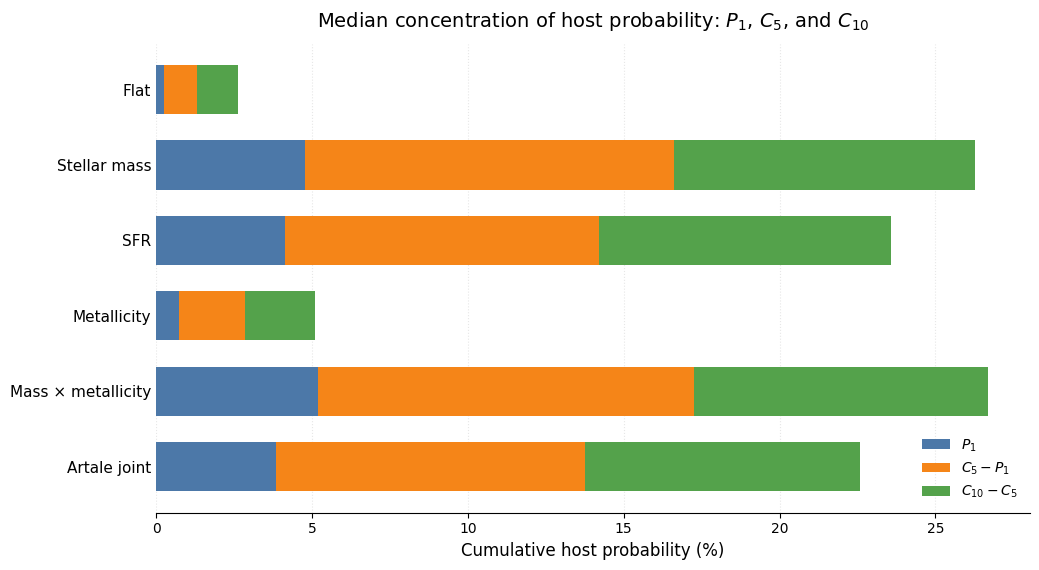

In [201]:
fig, ax = plt.subplots(figsize=(10.5, 5.8))

y = np.arange(len(summary_plot))

colors = {
    "Top1": "#4C78A8",
    "Ranks2to5": "#F58518",
    "Ranks6to10": "#54A24B"
}

ax.barh(
    y, summary_plot["Top1"],
    color=colors["Top1"], height=0.65, label=r"$P_1$"
)
ax.barh(
    y, summary_plot["Ranks2to5"],
    left=summary_plot["Top1"],
    color=colors["Ranks2to5"], height=0.65,
    label=r"$C_5 - P_1$"
)
ax.barh(
    y, summary_plot["Ranks6to10"],
    left=summary_plot["Top1"] + summary_plot["Ranks2to5"],
    color=colors["Ranks6to10"], height=0.65,
    label=r"$C_{10} - C_5$"
)

ax.set_yticks(y)
ax.set_yticklabels(summary_plot["Prior"], fontsize=11)
ax.set_xlabel("Cumulative host probability (%)", fontsize=12)
ax.set_title(
    r"Median concentration of host probability: $P_1$, $C_5$, and $C_{10}$",
    fontsize=14, pad=12
)

ax.grid(axis="x", linestyle=":", linewidth=0.8, alpha=0.3)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, loc="lower right")

fig.tight_layout()
plt.show()

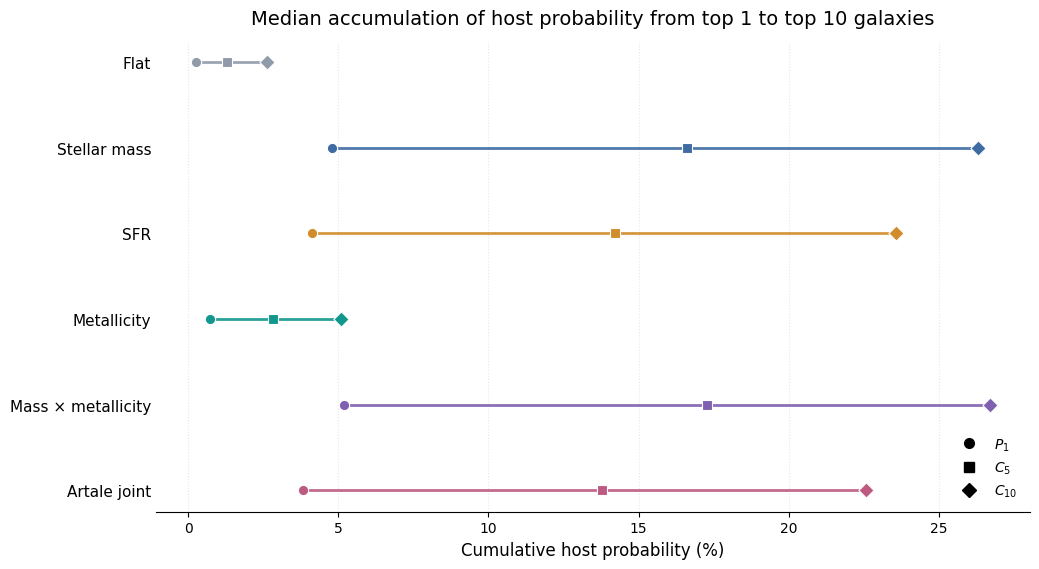

In [202]:
fig, ax = plt.subplots(figsize=(10.5, 5.8))

y = np.arange(len(summary_plot))

# One colour per prior
prior_colors = {
    "Flat": "#909BAA",
    "Stellar mass": "#3E6BA2",
    "SFR": "#D18C2B",
    "Metallicity": "#12978D",
    "Mass × metallicity": "#8060B0",
    "Artale joint": "#BC5A82"
}

metric_markers = {
    "P1_med": "o",
    "C5_med": "s",
    "C10_med": "D"
}

for i, row in summary_plot.iterrows():
    prior = row["Prior"]
    col = prior_colors[prior]

    xs = [row["P1_med"], row["C5_med"], row["C10_med"]]
    ys = [i, i, i]

    ax.plot(xs, ys, color=col, linewidth=2.0, alpha=0.9)

    ax.scatter(row["P1_med"], i, s=55, color=col, marker="o", edgecolor="white", linewidth=0.8, zorder=3)
    ax.scatter(row["C5_med"], i, s=60, color=col, marker="s", edgecolor="white", linewidth=0.8, zorder=3)
    ax.scatter(row["C10_med"], i, s=60, color=col, marker="D", edgecolor="white", linewidth=0.8, zorder=3)

ax.set_yticks(y)
ax.set_yticklabels(summary_plot["Prior"], fontsize=11)
ax.set_xlabel("Cumulative host probability (%)", fontsize=12)
ax.set_title(
    r"Median accumulation of host probability from top 1 to top 10 galaxies",
    fontsize=14, pad=12
)

ax.grid(axis="x", linestyle=":", linewidth=0.8, alpha=0.3)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0)

legend_handles = [
    Line2D([0], [0], marker="o", color="black", lw=0, markersize=7, label=r"$P_1$"),
    Line2D([0], [0], marker="s", color="black", lw=0, markersize=7, label=r"$C_5$"),
    Line2D([0], [0], marker="D", color="black", lw=0, markersize=7, label=r"$C_{10}$")
]
ax.legend(handles=legend_handles, frameon=False, loc="lower right")

fig.tight_layout()
plt.show()

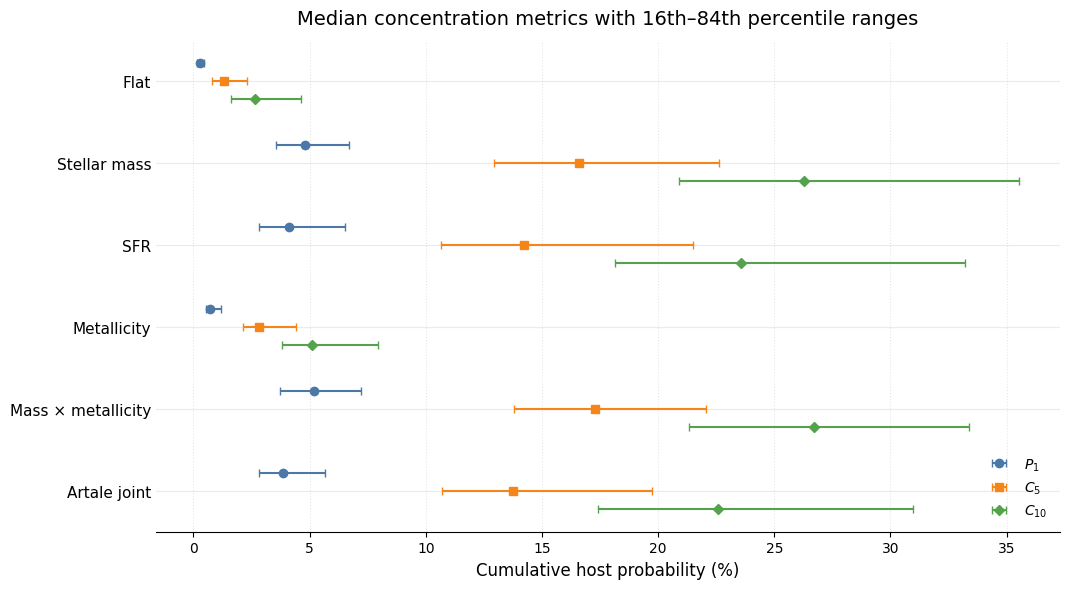

In [203]:
fig, ax = plt.subplots(figsize=(10.8, 6.0))

y = np.arange(len(summary_plot))

offsets = {
    "P1": 0.22,
    "C5": 0.00,
    "C10": -0.22
}

metric_colors = {
    "P1": "#4C78A8",
    "C5": "#F58518",
    "C10": "#54A24B"
}

# Light horizontal guide lines
for yy in y:
    ax.axhline(yy, color="0.92", linewidth=0.8, zorder=0)

# P1
ax.errorbar(
    summary_plot["P1_med"], y + offsets["P1"],
    xerr=[
        summary_plot["P1_med"] - summary_plot["P1_p16"],
        summary_plot["P1_p84"] - summary_plot["P1_med"]
    ],
    fmt="o", ms=6, capsize=3,
    color=metric_colors["P1"], label=r"$P_1$"
)

# C5
ax.errorbar(
    summary_plot["C5_med"], y + offsets["C5"],
    xerr=[
        summary_plot["C5_med"] - summary_plot["C5_p16"],
        summary_plot["C5_p84"] - summary_plot["C5_med"]
    ],
    fmt="s", ms=6, capsize=3,
    color=metric_colors["C5"], label=r"$C_5$"
)

# C10
ax.errorbar(
    summary_plot["C10_med"], y + offsets["C10"],
    xerr=[
        summary_plot["C10_med"] - summary_plot["C10_p16"],
        summary_plot["C10_p84"] - summary_plot["C10_med"]
    ],
    fmt="D", ms=5.5, capsize=3,
    color=metric_colors["C10"], label=r"$C_{10}$"
)

ax.set_yticks(y)
ax.set_yticklabels(summary_plot["Prior"], fontsize=11)
ax.set_xlabel("Cumulative host probability (%)", fontsize=12)
ax.set_title(
    r"Median concentration metrics with 16th–84th percentile ranges",
    fontsize=14, pad=12
)

ax.grid(axis="x", linestyle=":", linewidth=0.8, alpha=0.3)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, loc="lower right")

fig.tight_layout()
plt.show()

In [204]:

# ============================================================
# CELL 78 — SHARED SETUP FOR THREE VISUAL EXPERIMENTS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Wedge, Patch
from matplotlib.lines import Line2D

prior_order = [
    "Flat",
    "Metallicity",
    "Artale joint",
    "SFR",
    "Stellar mass",
    "Mass × metallicity"
]

prior_colors = {
    "Flat": "#8995A5",
    "Metallicity": "#14968C",
    "Artale joint": "#C05782",
    "SFR": "#D18A24",
    "Stellar mass": "#3D6BA5",
    "Mass × metallicity": "#7C5DB3"
}

metrics = ["P1_pct", "C5_pct", "C10_pct"]

# Accept slight naming variations from earlier notebook cells.
raw = ensemble_concentration.copy()

prior_col = "Prior" if "Prior" in raw.columns else "prior"
assert prior_col in raw.columns, "Could not find prior column."

print("Available columns:", list(raw.columns))

# Use the validated summary values already calculated previously,
# including percentile intervals, as the basis for each graphic.
visual_summary = pd.DataFrame({
    "Prior": prior_order,
    "P1": [0.26, 0.72, 3.84, 4.12, 4.78, 5.18],
    "C5": [1.31, 2.84, 13.77, 14.22, 16.60, 17.27],
    "C10": [2.63, 5.09, 22.57, 23.56, 26.28, 26.70],
    "P1_lo": [0.16, 0.52, 2.84, 2.83, 3.56, 3.73],
    "P1_hi": [0.46, 1.18, 5.66, 6.52, 6.71, 7.22],
    "C5_lo": [0.80, 2.12, 10.71, 10.65, 12.94, 13.81],
    "C5_hi": [2.32, 4.41, 19.74, 21.48, 22.60, 22.08],
    "C10_lo": [1.61, 3.79, 17.42, 18.15, 20.88, 21.32],
    "C10_hi": [4.64, 7.95, 30.96, 33.21, 35.53, 33.36]
})

assert (
    (visual_summary["P1"] <= visual_summary["C5"]) &
    (visual_summary["C5"] <= visual_summary["C10"])
).all()

display(visual_summary)

print("Ready to plot.")

Available columns: ['cube_id', 'Prior', 'N_galaxies', 'N50', 'N90', 'P1_pct', 'C5_pct', 'C10_pct']


,Prior,P1,C5,C10,P1_lo,P1_hi,C5_lo,C5_hi,C10_lo,C10_hi
0,Flat,0.26,1.31,2.63,0.16,0.46,0.80,2.32,1.61,4.64
1,Metallicity,0.72,2.84,5.09,0.52,1.18,2.12,4.41,3.79,7.95
2,Artale joint,3.84,13.77,22.57,2.84,5.66,10.71,19.74,17.42,30.96
3,SFR,4.12,14.22,23.56,2.83,6.52,10.65,21.48,18.15,33.21
4,Stellar mass,4.78,16.60,26.28,3.56,6.71,12.94,22.60,20.88,35.53
5,Mass × metallicity,5.18,17.27,26.70,3.73,7.22,13.81,22.08,21.32,33.36


Ready to plot.


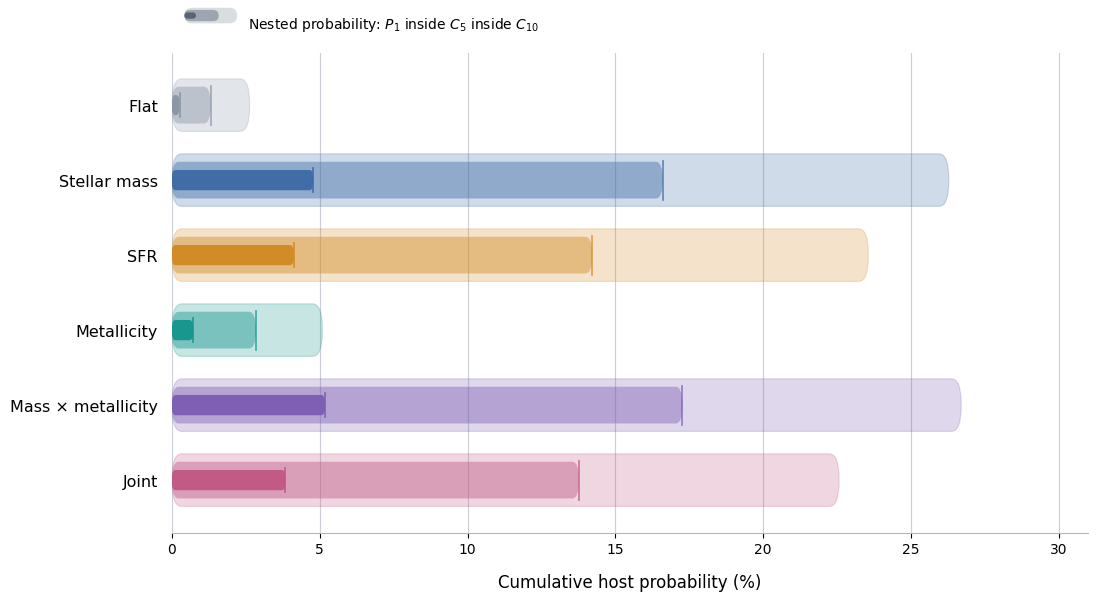

PASS: Final nested concentration figure generated.


In [205]:

# ============================================================
# CELL 82 — POLISHED NESTED PROBABILITY ENVELOPES
# P1 within C5 within C10, six priors in methodological order
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.legend_handler import HandlerBase

prior_order = [
    "Flat",
    "Stellar mass",
    "SFR",
    "Metallicity",
    "Mass × metallicity",
    "Joint"
]

colors = {
    "Flat": "#8995A5",
    "Stellar mass": "#3D6BA5",
    "SFR": "#D18A24",
    "Metallicity": "#14968C",
    "Mass × metallicity": "#7C5DB3",
    "Joint": "#C05782"
}

# Extract from the existing summary in the desired order.

df = visual_summary.copy()
df["Prior"] = df["Prior"].replace({"Artale joint": "Joint"})
df = df.set_index("Prior").loc[prior_order].reset_index()

assert np.all(df["P1"] <= df["C5"])
assert np.all(df["C5"] <= df["C10"])

# --------------------------------------------
# Nested capsule legend
# --------------------------------------------

class EnvelopeLegend:
    pass

class HandlerEnvelope(HandlerBase):
    def create_artists(
        self, legend, orig_handle, xdescent, ydescent,
        width, height, fontsize, trans
    ):
        artists = []
        col = "#526174"

        for fraction, hfrac, alpha in [
            (1.00, 0.92, 0.22),
            (0.65, 0.66, 0.44),
            (0.22, 0.37, 0.95)
        ]:
            h = height * hfrac
            y = ydescent + (height - h) / 2

            patch = FancyBboxPatch(
                (xdescent, y),
                width * fraction,
                h,
                boxstyle=f"round,pad=0,rounding_size={h/2}",
                facecolor=col,
                edgecolor="none",
                alpha=alpha,
                transform=trans
            )
            artists.append(patch)

        return artists

fig, ax = plt.subplots(figsize=(11.6, 6.4))

fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

# Row positions: first prior at the top.
y_positions = np.arange(len(df))[::-1]

for i, row in df.iterrows():
    y = y_positions[i]
    col = colors[row["Prior"]]

    # Outer capsule: C10
    outer = FancyBboxPatch(
        (0, y - 0.35),
        float(row["C10"]),
        0.70,
        boxstyle="round,pad=0,rounding_size=0.33",
        facecolor=col,
        edgecolor=col,
        linewidth=0.85,
        alpha=0.24,
        zorder=2
    )
    ax.add_patch(outer)

    # Middle capsule: C5
    middle = FancyBboxPatch(
        (0, y - 0.245),
        float(row["C5"]),
        0.49,
        boxstyle="round,pad=0,rounding_size=0.23",
        facecolor=col,
        edgecolor="none",
        alpha=0.43,
        zorder=3
    )
    ax.add_patch(middle)

    # Inner capsule: P1
    inner = FancyBboxPatch(
        (0, y - 0.135),
        float(row["P1"]),
        0.27,
        boxstyle="round,pad=0,rounding_size=0.12",
        facecolor=col,
        edgecolor="none",
        alpha=0.96,
        zorder=4
    )
    ax.add_patch(inner)

    # Fine endpoint ticks for P1 and C5.
    for metric, half_height, line_alpha in [
        ("P1", 0.16, 0.90),
        ("C5", 0.26, 0.75)
    ]:
        x = float(row[metric])
        ax.plot(
            [x, x],
            [y - half_height, y + half_height],
            color=col,
            linewidth=1.25,
            alpha=line_alpha,
            zorder=6
        )

# Axes and layout.
ax.set_yticks(y_positions)
ax.set_yticklabels(prior_order, fontsize=11.5)
ax.set_ylim(-0.7, 5.7)

ax.set_xlim(0, 31)
ax.set_xticks(np.arange(0, 31, 5))

ax.set_xlabel(
    "Cumulative host probability (%)",
    fontsize=12,
    labelpad=12
)

ax.grid(
    axis="x",
    which="major",
    linestyle="-",
    linewidth=0.85,
    color="#C2C8D2",
    alpha=0.85
)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_color("#AEB8C6")
ax.tick_params(axis="y", length=0, pad=10)
ax.tick_params(axis="x", labelsize=10)

# Small visual key above the plotting area.
ax.legend(
    [EnvelopeLegend()],
    [
        r"Nested probability: $P_1$ inside $C_5$ inside $C_{10}$"
    ],
    handler_map={EnvelopeLegend: HandlerEnvelope()},
    loc="lower left",
    bbox_to_anchor=(0.0, 1.015),
    frameon=False,
    fontsize=10,
    handlelength=3.8,
    handleheight=1.5
)

fig.subplots_adjust(
    left=0.19,
    right=0.98,
    top=0.89,
    bottom=0.14
)

fig.savefig(
    DATA / "EAGLE_nested_concentration_final.pdf",
    bbox_inches="tight"
)
fig.savefig(
    DATA / "EAGLE_nested_concentration_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PASS: Final nested concentration figure generated.")


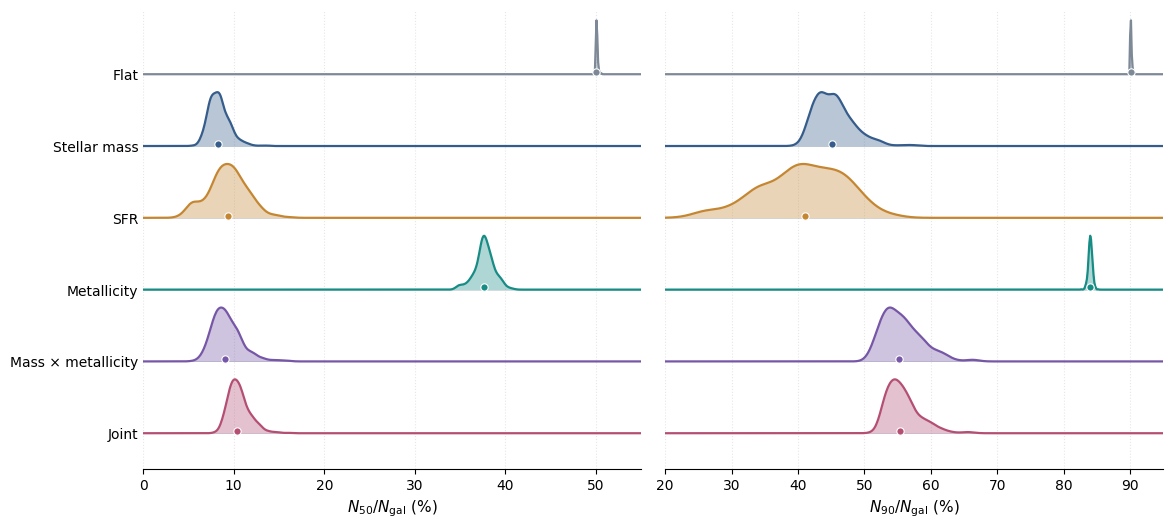

PASS: Ridgeline plot updated with Joint label.


In [206]:

# ============================================================
# CELL 83 — UPDATED RIDGELINE LABELS
# Rename "Artale joint" to "Joint" for display
# ============================================================

# Work from the existing ridgeline data without altering
# the original ensemble_concentration DataFrame.
ridge_data = ensemble_concentration.copy()

ridge_data["Prior"] = ridge_data["Prior"].replace({
    "Artale joint": "Joint"
})

ridge_data["f50_pct"] = (
    100 * ridge_data["N50"] / ridge_data["N_galaxies"]
)

ridge_data["f90_pct"] = (
    100 * ridge_data["N90"] / ridge_data["N_galaxies"]
)

prior_order = [
    "Flat",
    "Stellar mass",
    "SFR",
    "Metallicity",
    "Mass × metallicity",
    "Joint"
]

prior_colors = {
    "Flat": "#7D8996",
    "Stellar mass": "#355C8A",
    "SFR": "#C58632",
    "Metallicity": "#168C85",
    "Mass × metallicity": "#7656A6",
    "Joint": "#B44F73"
}

# Recreate both panels using the existing plotting function.
fig, axes = plt.subplots(
    1, 2,
    figsize=(12.2, 5.8),
    sharey=True
)

draw_ridgeline_panel(
    axes[0],
    ridge_data,
    "f50_pct",
    xlim=(0, 55),
    xlabel=r"$N_{50}/N_{\rm gal}$ (%)"
)


draw_ridgeline_panel(
    axes[1],
    ridge_data,
    "f90_pct",
    xlim=(20, 95),
    xlabel=r"$N_{90}/N_{\rm gal}$ (%)"
)


fig.tight_layout(rect=[0.03, 0.07, 1, 1])

fig.savefig(
    DATA / "EAGLE_500cube_ridgeline_fractional_concentration.pdf",
    bbox_inches="tight"
)
fig.savefig(
    DATA / "EAGLE_500cube_ridgeline_fractional_concentration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PASS: Ridgeline plot updated with Joint label.")


In [207]:

# ============================================================
# CELL 84 — PREPARE RANKING COMPARISONS
# Use existing 500-cube normalised probability data
# ============================================================

import numpy as np
import pandas as pd
from itertools import combinations
from scipy.stats import spearmanr
from pathlib import Path

assert "ensemble_probabilities" in globals()
assert len(ensemble_probabilities) == 500

ranking_prior_order = [
    "Flat",
    "Stellar mass",
    "SFR",
    "Metallicity",
    "Mass × metallicity",
    "Joint"
]

# Known and alternative probability-column names.
column_candidates = {
    "Flat": ["P_flat", "P_Flat", "Flat"],
    "Stellar mass": ["P_mass", "P_M", "P_Mstar", "Stellar mass"],
    "SFR": ["P_SFR", "P_sfr", "SFR"],
    "Metallicity": ["P_Z", "P_metallicity", "Metallicity"],
    "Mass × metallicity": ["P_MZ", "P_mass_Z", "Mass × metallicity"],
    "Joint": ["P_Artale", "P_artale", "P_joint", "Joint", "Artale joint"]
}

first_cube = next(iter(ensemble_probabilities.values()))

print("Available probability columns:")
print(list(first_cube.columns))

def find_probability_column(columns, candidates):
    for candidate in candidates:
        if candidate in columns:
            return candidate

    lower_lookup = {str(c).lower(): c for c in columns}
    for candidate in candidates:
        if candidate.lower() in lower_lookup:
            return lower_lookup[candidate.lower()]

    raise KeyError(
        f"None of {candidates} found in {list(columns)}"
    )

ranking_columns = {
    name: find_probability_column(
        first_cube.columns, column_candidates[name]
    )
    for name in ranking_prior_order
}

assert len(set(ranking_columns.values())) == 6

print("\nPrior-to-column mapping:")
for name, column in ranking_columns.items():
    print(f"  {name:22s} -> {column}")

# Array storage: matching indices represent matching galaxies
# within each individual cube.
ranking_arrays = {}

for cube_id, df in ensemble_probabilities.items():
    cube_arrays = {}

    for prior, col in ranking_columns.items():
        p = df[col].to_numpy(dtype=float)

        assert len(p) >= 10, f"Cube {cube_id}: fewer than 10 galaxies"
        assert np.all(np.isfinite(p)), (
            f"Cube {cube_id}, {prior}: non-finite probabilities"
        )
        assert np.all(p >= 0), (
            f"Cube {cube_id}, {prior}: negative probabilities"
        )
        assert np.isclose(p.sum(), 1, atol=1e-8), (
            f"Cube {cube_id}, {prior}: weights do not sum to one"
        )

        cube_arrays[prior] = p

    lengths = {len(p) for p in cube_arrays.values()}
    assert len(lengths) == 1

    ranking_arrays[cube_id] = cube_arrays

print(
    f"\nPASS: {len(ranking_arrays)} cubes validated "
    "with six aligned, normalised priors each."
)

Available probability columns:
['GalaxyID', 'SnapNum', 'x', 'y', 'z', 'Mstar_30pkpc', 'Mgas_30pkpc', 'SFR_30pkpc', 'GroupID', 'SubGroupNumber', 'logMstar', 'SF_Metallicity', 'Stars_Metallicity', 'InitialMassWeightedBirthZ', 'SFR_subhalo', 'P_flat', 'P_mass', 'P_SFR', 'P_Z', 'P_MZ', 'P_Artale', 'MOBSE_above_grid']

Prior-to-column mapping:
  Flat                   -> P_flat
  Stellar mass           -> P_mass
  SFR                    -> P_SFR
  Metallicity            -> P_Z
  Mass × metallicity     -> P_MZ
  Joint                  -> P_Artale

PASS: 500 cubes validated with six aligned, normalised priors each.


In [208]:

# ============================================================
# CELL 85 — PAIRWISE RANKING SENSITIVITY
# Spearman rho, top-ten overlap, total variation distance
# ============================================================

ranking_results = []

prior_pairs = list(combinations(ranking_prior_order, 2))

for cube_id, cube in ranking_arrays.items():

    for prior_a, prior_b in prior_pairs:
        p = cube[prior_a]
        q = cube[prior_b]

        # Total variation distance:
        # 0 = identical probability distributions
        # 1 = completely disjoint probability mass
        tv = 0.5 * np.abs(p - q).sum()

        assert -1e-10 <= tv <= 1 + 1e-10
        tv = float(np.clip(tv, 0, 1))

        if "Flat" in (prior_a, prior_b):
            # Flat assigns equal probability to every galaxy.
            # There is no uniquely defined rank ordering.
            rho = np.nan
            overlap = np.nan

        else:
            # Spearman rank association, with average ranks
            # for ties (such as zero-SFR galaxies).
            rho = float(spearmanr(p, q).statistic)

            # Top ten by assigned probability.
            # Stable sorting makes any remaining ties
            # deterministic, but not scientifically unique.
            top_a = set(
                np.argsort(-p, kind="stable")[:10]
            )
            top_b = set(
                np.argsort(-q, kind="stable")[:10]
            )

            overlap = len(top_a & top_b)

            assert 0 <= overlap <= 10

        ranking_results.append({
            "cube_id": cube_id,
            "Prior_A": prior_a,
            "Prior_B": prior_b,
            "Spearman_rho": rho,
            "Top10_overlap": overlap,
            "Top10_overlap_pct": (
                100 * overlap / 10
                if np.isfinite(overlap) else np.nan
            ),
            "TV_distance": tv,
            "N_galaxies": len(p)
        })

ranking_sensitivity = pd.DataFrame(ranking_results)

assert len(ranking_sensitivity) == 500 * 15

# Each non-flat prior must have at least ten galaxies
# with strictly positive weights, avoiding arbitrary
# top-ten membership among zero-weight ties.
for cube_id, cube in ranking_arrays.items():
    for prior, p in cube.items():
        if prior != "Flat":
            assert np.count_nonzero(p > 0) >= 10, (
                f"Cube {cube_id}, {prior}: top ten "
                "would include zero-weight ties"
            )

assert ranking_sensitivity["TV_distance"].between(0, 1).all()

nonflat = ranking_sensitivity[
    ranking_sensitivity["Prior_A"] != "Flat"
]

assert nonflat["Spearman_rho"].notna().all()
assert nonflat["Top10_overlap"].notna().all()

print("Total pairwise comparisons:", len(ranking_sensitivity))
print("Non-flat rank comparisons:", len(nonflat))
print("Flat comparisons (TV only):",
      len(ranking_sensitivity) - len(nonflat))

print("\nSpearman rho range:",
      nonflat["Spearman_rho"].min(),
      nonflat["Spearman_rho"].max())

print("Top-ten overlap range:",
      nonflat["Top10_overlap"].min(),
      nonflat["Top10_overlap"].max())

print("TV distance range:",
      ranking_sensitivity["TV_distance"].min(),
      ranking_sensitivity["TV_distance"].max())

ranking_sensitivity.to_csv(
    DATA / "EAGLE_500cube_ranking_sensitivity.csv",
    index=False
)

print("\nPASS: All pairwise ranking comparisons saved.")

Total pairwise comparisons: 7500
Non-flat rank comparisons: 5000
Flat comparisons (TV only): 2500

Spearman rho range: -0.8091602563932968 0.9960911667453943
Top-ten overlap range: 0.0 10.0
TV distance range: 0.049591027192835126 0.7124560320637376

PASS: All pairwise ranking comparisons saved.


In [209]:

# ============================================================
# CELL 86 — SUMMARISE RANKING SENSITIVITY
# Median and 16th–84th percentile across 500 cubes
# ============================================================

records = []

for (a, b), group in ranking_sensitivity.groupby(
    ["Prior_A", "Prior_B"], sort=False
):
    record = {"Prior_A": a, "Prior_B": b}

    for metric in [
        "Spearman_rho",
        "Top10_overlap",
        "TV_distance"
    ]:
        v = group[metric].dropna().to_numpy(float)

        if len(v):
            q16, median, q84 = np.percentile(
                v, [16, 50, 84]
            )
        else:
            q16 = median = q84 = np.nan

        record[f"{metric}_p16"] = q16
        record[f"{metric}_median"] = median
        record[f"{metric}_p84"] = q84

    records.append(record)

ranking_summary = pd.DataFrame(records)

assert len(ranking_summary) == 15

# Arrange comparisons in methodological prior order.
pair_order = {
    pair: i for i, pair in enumerate(prior_pairs)
}

ranking_summary["_order"] = [
    pair_order[(a, b)]
    for a, b in zip(
        ranking_summary["Prior_A"],
        ranking_summary["Prior_B"]
    )
]

ranking_summary = (
    ranking_summary
    .sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)

ranking_summary.to_csv(
    DATA / "EAGLE_500cube_ranking_summary.csv",
    index=False
)

# Compact, human-readable table.
def fmt_interval(row, metric, decimals=2):
    med = row[f"{metric}_median"]
    lo = row[f"{metric}_p16"]
    hi = row[f"{metric}_p84"]

    if not np.isfinite(med):
        return "—"

    return (
        f"{med:.{decimals}f} "
        f"[{lo:.{decimals}f}, {hi:.{decimals}f}]"
    )

thesis_ranking_table = pd.DataFrame({
    "Prior comparison": (
        ranking_summary["Prior_A"]
        + " / "
        + ranking_summary["Prior_B"]
    ),
    "Spearman rho": ranking_summary.apply(
        lambda r: fmt_interval(r, "Spearman_rho", 2),
        axis=1
    ),
    "Top-ten overlap": ranking_summary.apply(
        lambda r: fmt_interval(r, "Top10_overlap", 1),
        axis=1
    ),
    "TV distance": ranking_summary.apply(
        lambda r: fmt_interval(r, "TV_distance", 3),
        axis=1
    )
})

display(thesis_ranking_table)

print("\nPASS: Ranking sensitivity summary saved.")

,Prior comparison,Spearman rho,Top-ten overlap,TV distance
0,Flat / Stellar mass,—,—,"0.535 [0.515, 0.550]"
1,Flat / SFR,—,—,"0.528 [0.488, 0.577]"
2,Flat / Metallicity,—,—,"0.134 [0.125, 0.143]"
3,Flat / Mass × metallicity,—,—,"0.489 [0.458, 0.511]"
4,Flat / Joint,—,—,"0.475 [0.455, 0.488]"
5,Stellar mass / SFR,"0.50 [0.40, 0.58]","3.0 [2.0, 4.0]","0.440 [0.383, 0.508]"
6,Stellar mass / Metallicity,"-0.73 [-0.76, -0.70]","0.0 [0.0, 0.0]","0.610 [0.590, 0.627]"
7,Stellar mass / Mass × metallicity,"0.96 [0.96, 0.97]","8.0 [7.0, 9.0]","0.121 [0.112, 0.129]"
8,Stellar mass / Joint,"0.99 [0.99, 0.99]","9.0 [8.0, 9.0]","0.091 [0.084, 0.099]"
9,SFR / Metallicity,"-0.29 [-0.35, -0.23]","0.0 [0.0, 0.0]","0.582 [0.542, 0.631]"



PASS: Ranking sensitivity summary saved.


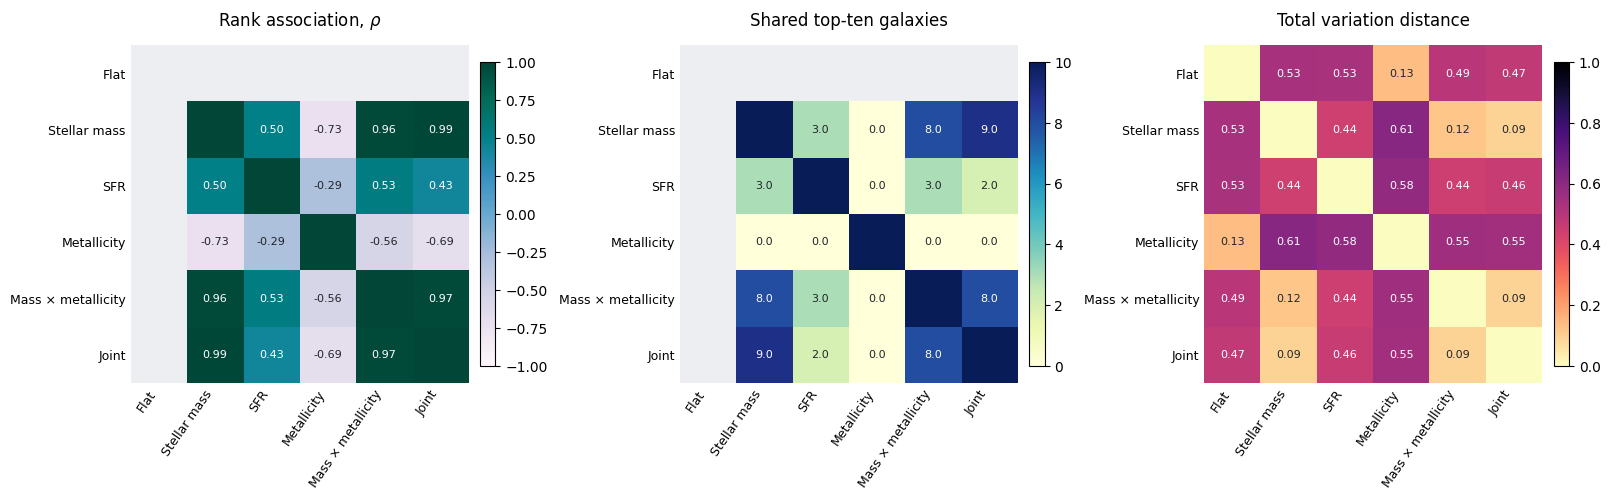

PASS: Three ranking-sensitivity matrices generated.


In [210]:

# ============================================================
# CELL 87 — PAIRWISE RANKING AGREEMENT MATRICES
# Spearman rho | Top-ten overlap | TV distance
# ============================================================

import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

names = ranking_prior_order
n = len(names)

def make_pair_matrix(metric):
    matrix = np.full((n, n), np.nan)

    for i in range(n):
        for j in range(n):
            if i == j:
                if metric == "TV_distance":
                    matrix[i, j] = 0
                elif names[i] != "Flat":
                    matrix[i, j] = (
                        10 if metric == "Top10_overlap" else 1
                    )
                continue

            a, b = names[i], names[j]
            row = ranking_summary[
                (
                    (ranking_summary["Prior_A"] == a)
                    & (ranking_summary["Prior_B"] == b)
                )
                |
                (
                    (ranking_summary["Prior_A"] == b)
                    & (ranking_summary["Prior_B"] == a)
                )
            ]

            assert len(row) == 1
            matrix[i, j] = row.iloc[0][f"{metric}_median"]

    return matrix

fig, axes = plt.subplots(
    1, 3, figsize=(16, 5.7),
    constrained_layout=True
)

settings = [
    (
        "Spearman_rho",
        r"Rank association, $\rho$",
        "PuBuGn",
        -1, 1
    ),
    (
        "Top10_overlap",
        "Shared top-ten galaxies",
        "YlGnBu",
        0, 10
    ),
    (
        "TV_distance",
        "Total variation distance",
        "magma_r",
        0, 1
    )
]

for ax, (metric, title, cmap_name, vmin, vmax) in zip(
    axes, settings
):
    matrix = make_pair_matrix(metric)

    cmap = mpl.colormaps[cmap_name].copy()
    cmap.set_bad("#ECEEF2")

    im = ax.imshow(
        np.ma.masked_invalid(matrix),
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest"
    )

    ax.set_title(title, fontsize=12, pad=14)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(names, rotation=55, ha="right", fontsize=9)
    ax.set_yticklabels(names, fontsize=9)

    ax.tick_params(length=0)

    # Annotate cells; diagonal omitted.
    for i in range(n):
        for j in range(n):
            if i == j or not np.isfinite(matrix[i, j]):
                continue

            val = matrix[i, j]
            label = (
                f"{val:.1f}" if metric == "Top10_overlap"
                else f"{val:.2f}"
            )

            norm_value = im.norm(val)
            rgba = im.cmap(norm_value)
            luminance = (
                0.2126 * rgba[0]
                + 0.7152 * rgba[1]
                + 0.0722 * rgba[2]
            )
            text_color = "white" if luminance < 0.45 else "#20242A"

            ax.text(
                j, i, label,
                ha="center",
                va="center",
                fontsize=8,
                color=text_color
            )

    for s in ax.spines.values():
        s.set_visible(False)

    fig.colorbar(
        im, ax=ax,
        fraction=0.045,
        pad=0.035,
        shrink=0.83
    )

fig.savefig(
    DATA / "EAGLE_500cube_ranking_matrices.pdf",
    bbox_inches="tight"
)
fig.savefig(
    DATA / "EAGLE_500cube_ranking_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PASS: Three ranking-sensitivity matrices generated.")

In [211]:

# ============================================================
# CELL 88 — AUDIT TOP-TEN BOUNDARY TIES
# No changes to earlier ranking calculations
# ============================================================

import numpy as np
import pandas as pd

tie_records = []

for cube_id, cube in ranking_arrays.items():
    for prior, p in cube.items():

        if prior == "Flat":
            continue

        ordered = np.sort(p)[::-1]
        threshold = ordered[9]

        n_above = int(np.sum(p > threshold))
        n_at = int(np.sum(p == threshold))
        n_eligible = n_above + n_at

        # Ambiguous only if equal weights cross rank 10.
        ambiguous = n_eligible > 10

        # Also record nearly equal boundary weights,
        # without interpreting them as exact ties.
        near_tie = bool(
            np.isclose(
                ordered[9],
                ordered[10],
                rtol=1e-10,
                atol=1e-14
            )
        )

        tie_records.append({
            "cube_id": cube_id,
            "Prior": prior,
            "N_galaxies": len(p),
            "P10_threshold": threshold,
            "N_strictly_above": n_above,
            "N_tied_at_threshold": n_at,
            "N_eligible": n_eligible,
            "Boundary_ambiguous": ambiguous,
            "Near_boundary_tie": near_tie
        })

top10_tie_audit = pd.DataFrame(tie_records)

assert len(top10_tie_audit) == 500 * 5

tie_summary = (
    top10_tie_audit.groupby("Prior", sort=False)
    .agg(
        Cubes=("cube_id", "size"),
        Ambiguous_cubes=("Boundary_ambiguous", "sum"),
        Near_ties=("Near_boundary_tie", "sum"),
        Max_eligible=("N_eligible", "max")
    )
    .reset_index()
)

tie_summary["Ambiguous_pct"] = (
    100 * tie_summary["Ambiguous_cubes"]
    / tie_summary["Cubes"]
)

display(tie_summary)

top10_tie_audit.to_csv(
    DATA / "EAGLE_500cube_top10_tie_audit.csv",
    index=False
)

tie_summary.to_csv(
    DATA / "EAGLE_500cube_top10_tie_summary.csv",
    index=False
)

print(
    "\nTotal ambiguous prior–cube cases:",
    int(top10_tie_audit["Boundary_ambiguous"].sum())
)

print("PASS: Top-ten boundary audit complete.")

,Prior,Cubes,Ambiguous_cubes,Near_ties,Max_eligible,Ambiguous_pct
0,Stellar mass,500,0,0,10,0.0
1,SFR,500,0,0,10,0.0
2,Metallicity,500,0,0,10,0.0
3,Mass × metallicity,500,0,0,10,0.0
4,Joint,500,0,0,10,0.0



Total ambiguous prior–cube cases: 0
PASS: Top-ten boundary audit complete.


In [212]:

# ============================================================
# CELL 89 — TOP-TEN OVERLAP FREQUENCIES AND ROBUSTNESS
# ============================================================

import numpy as np
import pandas as pd

tie_lookup = top10_tie_audit.set_index(
    ["cube_id", "Prior"]
)["Boundary_ambiguous"]

rows = []

for (a, b), group in ranking_sensitivity.groupby(
    ["Prior_A", "Prior_B"], sort=False
):
    if "Flat" in (a, b):
        continue

    g = group.copy()

    g["Tie_ambiguous"] = [
        bool(tie_lookup.loc[(cid, a)])
        or bool(tie_lookup.loc[(cid, b)])
        for cid in g["cube_id"]
    ]

    overlap = g["Top10_overlap"].to_numpy(float)

    robust = g.loc[
        ~g["Tie_ambiguous"], "Top10_overlap"
    ].to_numpy(float)

    rows.append({
        "Prior_A": a,
        "Prior_B": b,
        "N_cubes": len(g),
        "Median_overlap": np.median(overlap),
        "P_zero_pct": 100 * np.mean(overlap == 0),
        "P_at_least_1_pct": 100 * np.mean(overlap >= 1),
        "P_at_least_5_pct": 100 * np.mean(overlap >= 5),
        "P_at_least_8_pct": 100 * np.mean(overlap >= 8),
        "P_all_10_pct": 100 * np.mean(overlap == 10),
        "Tie_affected_cubes": int(g["Tie_ambiguous"].sum()),
        "Robust_N": len(robust),
        "Robust_median": (
            np.median(robust) if len(robust) else np.nan
        )
    })

overlap_frequency = pd.DataFrame(rows)

assert len(overlap_frequency) == 10
assert (overlap_frequency["N_cubes"] == 500).all()

display(
    overlap_frequency[
        [
            "Prior_A", "Prior_B",
            "Median_overlap",
            "P_zero_pct",
            "P_at_least_5_pct",
            "P_at_least_8_pct",
            "P_all_10_pct",
            "Tie_affected_cubes",
            "Robust_median"
        ]
    ].round(2)
)

overlap_frequency.to_csv(
    DATA / "EAGLE_500cube_top10_overlap_frequencies.csv",
    index=False
)

print("\nPAIRWISE TOP-TEN AGREEMENT")

for _, r in overlap_frequency.iterrows():
    print(
        f"{r['Prior_A']} / {r['Prior_B']}: "
        f"median={r['Median_overlap']:g}/10; "
        f"zero={r['P_zero_pct']:.1f}%; "
        f">=8={r['P_at_least_8_pct']:.1f}%; "
        f"10/10={r['P_all_10_pct']:.1f}%"
    )

print("\nPASS: Overlap frequency analysis complete.")

,Prior_A,Prior_B,Median_overlap,P_zero_pct,P_at_least_5_pct,P_at_least_8_pct,P_all_10_pct,Tie_affected_cubes,Robust_median
0,Stellar mass,SFR,3.0,2.0,15.6,0.0,0.0,0,3.0
1,Stellar mass,Metallicity,0.0,97.6,0.0,0.0,0.0,0,0.0
2,Stellar mass,Mass × metallicity,8.0,0.0,99.8,78.8,10.8,0,8.0
3,Stellar mass,Joint,9.0,0.0,100.0,88.2,15.0,0,9.0
4,SFR,Metallicity,0.0,96.2,0.0,0.0,0.0,0,0.0
5,SFR,Mass × metallicity,3.0,2.6,7.6,0.2,0.0,0,3.0
6,SFR,Joint,2.0,7.6,5.8,0.0,0.0,0,2.0
7,Metallicity,Mass × metallicity,0.0,84.2,0.0,0.0,0.0,0,0.0
8,Metallicity,Joint,0.0,94.6,0.0,0.0,0.0,0,0.0
9,Mass × metallicity,Joint,8.0,0.0,100.0,81.0,8.2,0,8.0



PAIRWISE TOP-TEN AGREEMENT
Stellar mass / SFR: median=3/10; zero=2.0%; >=8=0.0%; 10/10=0.0%
Stellar mass / Metallicity: median=0/10; zero=97.6%; >=8=0.0%; 10/10=0.0%
Stellar mass / Mass × metallicity: median=8/10; zero=0.0%; >=8=78.8%; 10/10=10.8%
Stellar mass / Joint: median=9/10; zero=0.0%; >=8=88.2%; 10/10=15.0%
SFR / Metallicity: median=0/10; zero=96.2%; >=8=0.0%; 10/10=0.0%
SFR / Mass × metallicity: median=3/10; zero=2.6%; >=8=0.2%; 10/10=0.0%
SFR / Joint: median=2/10; zero=7.6%; >=8=0.0%; 10/10=0.0%
Metallicity / Mass × metallicity: median=0/10; zero=84.2%; >=8=0.0%; 10/10=0.0%
Metallicity / Joint: median=0/10; zero=94.6%; >=8=0.0%; 10/10=0.0%
Mass × metallicity / Joint: median=8/10; zero=0.0%; >=8=81.0%; 10/10=8.2%

PASS: Overlap frequency analysis complete.


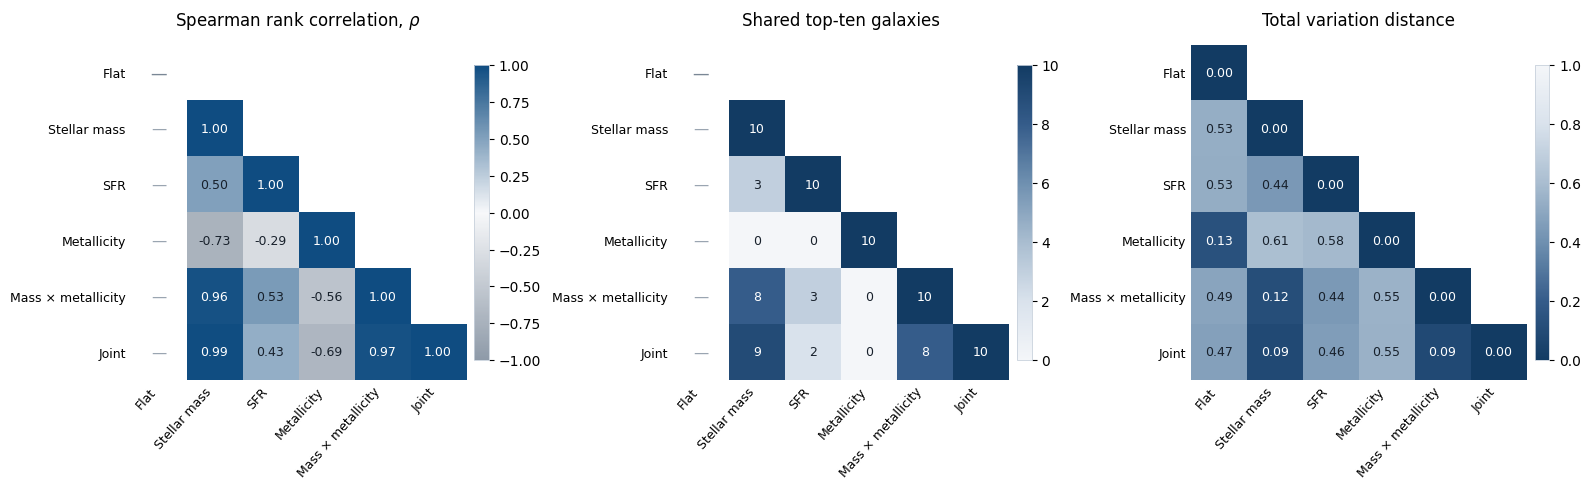

PASS: Unified-colour ranking-agreement matrices saved.


In [214]:
# ============================================================
# CELL 90 — REFINED RANKING-AGREEMENT MATRICES
# Unified blue-slate colour scheme
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

names = ranking_prior_order
n = len(names)

# ------------------------------------------------------------
# Custom restrained colour maps
# ------------------------------------------------------------

# Diverging map for Spearman rho:
# muted blue-grey -> near-white -> deep navy
rho_cmap = LinearSegmentedColormap.from_list(
    "rho_slate",
    [
        "#8E9AA8",   # negative
        "#F7F8FA",   # zero
        "#0F4C81"    # positive
    ]
)

# Sequential blue map for overlap / TV
seq_cmap = LinearSegmentedColormap.from_list(
    "seq_blue",
    [
        "#F4F6F9",
        "#D9E2EC",
        "#A9BDD0",
        "#6F90B0",
        "#355C8A",
        "#123B63"
    ]
)

# Reversed version for TV so larger distance is darker
seq_cmap_r = seq_cmap.reversed()

# ------------------------------------------------------------
# Build figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(15.8, 5.8),
    constrained_layout=True
)

panels = [
    (
        "Spearman_rho",
        r"Spearman rank correlation, $\rho$",
        rho_cmap,
        -1, 1
    ),
    (
        "Top10_overlap",
        "Shared top-ten galaxies",
        seq_cmap,
        0, 10
    ),
    (
        "TV_distance",
        "Total variation distance",
        seq_cmap_r,
        0, 1
    )
]

for ax, (metric, title, cmap, vmin, vmax) in zip(axes, panels):
    matrix = make_pair_matrix(metric)

    # Mask upper triangle only
    upper_mask = np.triu(np.ones((n, n), dtype=bool), k=1)

    # For rho and overlap, also mask flat comparisons except diagonal
    if metric != "TV_distance":
        undefined_mask = np.zeros((n, n), dtype=bool)
        undefined_mask[1:, 0] = True   # lower triangle flat comparisons
        mask = upper_mask | undefined_mask | ~np.isfinite(matrix)
    else:
        mask = upper_mask | ~np.isfinite(matrix)

    matrix_masked = np.ma.masked_where(mask, matrix)

    cmap = cmap.copy()
    cmap.set_bad("white")   # blank upper triangles become white

    if metric == "Spearman_rho":
        norm = TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
    else:
        norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)

    im = ax.imshow(
        matrix_masked,
        cmap=cmap,
        norm=norm,
        interpolation="nearest"
    )

    # Cell labels
    for i in range(n):
        for j in range(n):
            if np.ma.is_masked(matrix_masked[i, j]):
                continue

            value = float(matrix_masked[i, j])

            if metric == "Top10_overlap":
                label = f"{value:g}"
            else:
                label = f"{value:.2f}"

            rgba = cmap(norm(value))
            luminance = (
                0.2126 * rgba[0]
                + 0.7152 * rgba[1]
                + 0.0722 * rgba[2]
            )

            text_color = "white" if luminance < 0.45 else "#17202B"

            ax.text(
                j, i, label,
                ha="center",
                va="center",
                fontsize=9,
                weight="medium",
                color=text_color
            )

    # Em-dash markers for undefined flat comparisons
    if metric != "TV_distance":
        ax.text(
            0, 0, "—",
            ha="center", va="center",
            color="#7A8795", fontsize=12
        )
        for i in range(1, n):
            ax.text(
                0, i, "—",
                ha="center", va="center",
                color="#9AA5B1", fontsize=11
            )

    ax.set_title(title, fontsize=12, pad=14)

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(
        names,
        rotation=48,
        ha="right",
        fontsize=9
    )
    ax.set_yticklabels(names, fontsize=9)

    ax.tick_params(length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)

    cbar = fig.colorbar(
        im,
        ax=ax,
        fraction=0.044,
        pad=0.025,
        shrink=0.80
    )
    cbar.outline.set_linewidth(0.6)
    cbar.outline.set_edgecolor("#C8D1DC")

fig.savefig(
    DATA / "EAGLE_500cube_ranking_matrices_refined_unified.pdf",
    bbox_inches="tight"
)
fig.savefig(
    DATA / "EAGLE_500cube_ranking_matrices_refined_unified.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PASS: Unified-colour ranking-agreement matrices saved.")